# TP 3 — Prompter des LLM locaux sur Tiny Shakespeare

J'identifie le locuteur d'une réplique avec des LLM prêts à l'emploi, sans entraîner de paramètres. Je garde les données, le découpage et la mesure des TP1 et TP2, car seul le pipeline change. L'ingénierie passe des features vers le prompt, son évaluation et son coût, donc le prompt devient un objet versionné et testé.

Je compare aussi deux modèles à budget mémoire comparable, car choisir un modèle est un choix de déploiement autant qu'un choix de qualité.

| Étape | Section | Ce que je livre |
|---|---|---|
| 1. Prompting | section 1 | Les 962 répliques, un jeu de mise au point, les repères ML, un prompt en blocs et une échelle d'itérations. |
| 2. Modèle LLM | section 2 | Un serveur Ollama local, les cartes des deux modèles, le décodage, le budget de sortie et les contrôles. |
| 3. Sortie générée | section 3 | Comment je lis les sorties, les modes de sortie, les itérations un bloc à la fois, le raisonnement et les folds. |
| 4. Évaluation | section 4 | Scores par fold face à LinearSVC, erreurs relues, coût et latence, test final, journal et conclusion. |


## 0. Mon problème et les acquis des TP1 et TP2

Je prédis le locuteur d'une réplique à partir de son seul texte, parmi 10 classes. Comme aux TP1 et TP2, je garde les répliques d'au moins 10 mots des 10 locuteurs les plus fréquents. Le modèle ne voit aucune donnée d'entraînement, sauf les exemples que je place dans le prompt.

| Fait observé dans les TP1 et TP2 | Ce que j'examine dans le TP3 |
|---|---|
| LinearSVC obtient un F1 macro de 0,482 ± 0,035 en validation croisée et 0,563 sur le test (TP1) | Un LLM sans entraînement atteint-il ce repère, et à quel coût ? |
| `kate`, `romeo`, `paulina` et `camillo` portent les poids les plus élevés (TP1, section 8.3) | Le LLM connaît-il déjà ces personnages et leur pièce, ou faut-il le lui dire ? |
| 9 confusions JULIET–ROMEO et 7 de GLOUCESTER vers DUKE VINCENTIO sur le test (TP1) | Les mêmes paires résistent-elles au LLM, et lesquelles corrige-t-il ? |
| Chaque modèle est ajusté dans les folds, jamais sur tout le développement (TP2) | Les exemples du prompt suivent la même règle, donc ils viennent du train du fold seulement. |
| Une prédiction est une classe parmi 10 (TP1 et TP2) | Une sortie générée est un texte libre, donc je dois la lire, la normaliser et compter les sorties hors liste. |
| Le TP2 comparait des architectures à données égales | Je compare ici deux modèles déjà entraînés, à budget mémoire comparable, sans toucher à leurs poids. |


> *Mes hypothèses :*
>
> - **H1, connaissance préalable.** Sans exemple, le LLM dépasse la classe majoritaire mais reste sous les 0,482 de LinearSVC, car le texte seul doit lui suffire pour reconnaître dix personnages. Testée dans les sections 3.1 et 3.6.
> - **H2, contexte.** Donner la pièce et le rôle de chaque personnage corrige surtout les répliques qui citent un nom. Le modèle relie un nom à une pièce plus sûrement qu'à un locuteur. Testée dans la section 3.4.
> - **H3, exemples.** Dix puis trente exemples tirés du train gagnent au moins 0,05 de F1 macro sur la meilleure version sans exemple, mais un autre tirage change le score. Testée dans les sections 3.4 et 3.6.
> - **H4, format.** Contraindre la sortie change la conformité plus que la qualité. Les sorties hors liste tombent donc à zéro sans écart de F1 macro au-delà de la dispersion des folds. Testée dans la section 3.3.
> - **H5, coût.** Le LLM coûte au moins cent fois la latence de LinearSVC par réplique. Il ne se justifie donc que si son F1 macro dépasse LinearSVC de plus que la dispersion des folds. Testée dans la section 4.3.
> - **H6, modèle à budget mémoire comparable.** Le grand modèle fortement quantifié dépasse le petit en F1 macro sur les mêmes prompts directs. Il coûte pourtant au moins deux fois sa latence par réplique. Testée dans les sections 3.6 et 4.3.
> - **H7, transfert du prompt.** Les gains obtenus en itérant sur un modèle se retrouvent sur l'autre avec le même signe, mais pas la même ampleur. Un prompt est en effet réglé contre le comportement d'un modèle. Testée dans les sections 3.4 et 3.6.
> - **H8, raisonnement.** Demander une sortie structurée peut déclencher un raisonnement interne, donc le mode de sortie et le raisonnement varient ensemble. Le raisonnement corrige surtout les répliques sans nom cité, au prix d'environ vingt fois plus de tokens générés. Testée dans les sections 3.3 et 3.5.

Je décide chaque version sur le jeu de mise au point, puis je confirme sur les cinq folds avant de regarder le test.


### Mon environnement

Je sélectionne `.venv/bin/python` comme kernel et j'installe les dépendances dans le terminal :

```sh
uv pip install --python .venv/bin/python -r requirements.txt
```

Les LLM tournent dans un serveur Ollama local, lancé à part dans le terminal :

```sh
ollama serve
ollama pull hf.co/unsloth/gemma-4-E4B-it-GGUF:UD-Q8_K_XL
ollama pull hf.co/unsloth/Qwen3.8-27B-GGUF:UD-Q2_K_XL
```

> *Mes choix :*
>
> - Un serveur local plutôt qu'une API hébergée, car les poids sont ouverts, aucune donnée ne sort de la machine et la version du modèle reste figée dans mon journal.
> - Deux modèles, un petit peu quantifié et un grand fortement quantifié, car ils occupent une place comparable en mémoire sur mon M3 Max. Leurs cartes sont lues dans la section 2.2.
> - Un seul des deux mène les itérations et l'autre vérifie les choix retenus, car mesurer chaque version sur les deux doublerait le temps sans changer les décisions. La section 2.5 fixe lequel mène.
> - Le client Python d'Ollama, figé dans `requirements.txt`, car chaque appel reste une requête JSON vers le serveur et le client me rend les compteurs de tokens et les durées.
> - Température 0 et seed 42, car une classification demande la génération la moins aléatoire, et je vérifie dans la section 2.4 que deux appels identiques donnent le même texte.
> - Un cache sur disque de chaque réponse, car chaque appel a un coût en temps et le notebook doit se rejouer de haut en bas sans relancer les mêmes appels.


In [1]:
# Environnement : versions, matériel, seed, client Ollama et présence des deux modèles.
import json
import platform
import random
import subprocess
import sys
import urllib.request
from importlib.metadata import version

import numpy as np
import ollama

# Seed fixée ici pour random et numpy, puis transmise au serveur à chaque appel (section 2.3).
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

# Serveur Ollama local, puis les deux modèles comparés
URL_OLLAMA = 'http://localhost:11434'
MODELES = {
    'gemma': 'hf.co/unsloth/gemma-4-E4B-it-GGUF:UD-Q8_K_XL',
    'qwen': 'hf.co/unsloth/Qwen3.8-27B-GGUF:UD-Q2_K_XL',
}
MODELE_DEV, MODELE_COMPARAISON = 'gemma', 'qwen'
client = ollama.Client(host=URL_OLLAMA)

# Versions et dépendances
print(f'Python : {platform.python_version()} — {sys.executable}')
for paquet in ('numpy', 'pandas', 'matplotlib', 'scikit-learn', 'ipykernel', 'ollama'):
    print(f'{paquet} : {version(paquet)}')

# Système et processeur
print(f'Système : {platform.platform()} — {platform.machine()}')
if sys.platform == 'darwin':
    processeur, ram = subprocess.check_output(
        ['sysctl', '-n', 'machdep.cpu.brand_string', 'hw.memsize'], text=True,
    ).splitlines()
    print(f'Processeur : {processeur} — RAM : {int(ram) / 2**30:g} Gio')

# Serveur : sa version, puis la présence des deux modèles et leur taille sur disque
with urllib.request.urlopen(f'{URL_OLLAMA}/api/version', timeout=10) as reponse:
    version_serveur = json.load(reponse)['version']
tailles = {modele.model: modele.size for modele in client.list().models}
for cle, nom in MODELES.items():
    assert nom in tailles, f'{nom} absent, à installer avec ollama pull {nom}'
    print(f'{cle} : {nom} — {tailles[nom] / 2**30:.2f} Gio')
print(f'Ollama : {version_serveur} — mise au point sur {MODELE_DEV} — Seed : {RANDOM_STATE}')

Python : 3.14.7 — /Users/hopy/Documents/ING3_GIA/ING3_IA_GB_S1/NLP/.venv/bin/python
numpy : 2.5.3
pandas : 3.0.5
matplotlib : 3.11.1
scikit-learn : 1.9.0
ipykernel : 7.3.0
ollama : 0.6.2
Système : macOS-26.5-arm64-arm-64bit-Mach-O — arm64
Processeur : Apple M3 Max — RAM : 36 Gio
gemma : hf.co/unsloth/gemma-4-E4B-it-GGUF:UD-Q8_K_XL — 9.04 Gio
qwen : hf.co/unsloth/Qwen3.8-27B-GGUF:UD-Q2_K_XL — 10.81 Gio
Ollama : 0.32.5 — mise au point sur gemma — Seed : 42


## 1. Prompting

### 1.1 Les mêmes répliques

Je reprends le chargement et le parser du TP1 comme au TP2, sans dépendre de leur état d'exécution. Le modèle reçoit la réplique brute, avec sa casse et sa ponctuation, car son tokenizer est dans la boîte noire et je ne le contrôle pas. Je ne prétraite rien, donc je mesure l'effet du prompt seul.


In [2]:
# Corpus : téléchargement de Tiny Shakespeare, parser du TP1 et jeu retenu, comme au TP2.
import re

import pandas as pd
from IPython.display import display

URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
SEUIL_MOTS, NB_LOCUTEURS = 10, 10

# Téléchargement du texte brut
with urllib.request.urlopen(URL, timeout=30) as reponse:
    texte = reponse.read().decode('utf-8')


def parser_repliques(txt: str) -> pd.DataFrame:
    """Reprend les règles du TP1 : un bloc, une étiquette et sa réplique."""
    lignes = []
    for bloc in txt.split("\n\n"):
        bloc = bloc.strip()
        if not bloc:
            continue
        parties = bloc.split("\n")
        entete = re.match(r"^([A-Z][A-Za-z' ]*):$", parties[0])  # Nom en majuscules puis « : »
        if entete and len(parties) > 1:
            lignes.append({
                'locuteur': entete.group(1).strip(),
                'replique': " ".join(p.strip() for p in parties[1:]).strip(),
            })
    return pd.DataFrame(lignes)


# Seuil de longueur avant de compter les locuteurs, ordre et indices du TP1 conservés
df = parser_repliques(texte)
longueurs = df['replique'].str.split().str.len()
locuteurs = df.loc[longueurs >= SEUIL_MOTS, 'locuteur'].value_counts().head(NB_LOCUTEURS).index
donnees = df.loc[(longueurs >= SEUIL_MOTS) & df['locuteur'].isin(locuteurs),
                 ['replique', 'locuteur']].copy()

Je contrôle ensuite le jeu retenu, car il doit être identique à celui des TP1 et TP2 pour que les scores restent comparables.

In [3]:
# Contrôles du jeu retenu : effectifs, longueurs, valeurs manquantes, doublons.
effectifs = donnees['locuteur'].value_counts()
longueurs_retenues = donnees['replique'].str.split().str.len()

# Comptes globaux
print(f'Extraction : {len(df):,} répliques, {df["locuteur"].nunique()} labels')
print(f'Jeu retenu : {len(donnees)} répliques, {len(effectifs)} classes')
print(f'Longueurs (mots) : min {longueurs_retenues.min()}, '
      f'médiane {longueurs_retenues.median():g}, max {longueurs_retenues.max()}')
print(f'Valeurs manquantes : {donnees.isna().sum().sum()}')
print(f'Répliques vides : {donnees["replique"].str.strip().eq("").sum()}')
print(f'Textes dupliqués dans le jeu retenu : {donnees["replique"].duplicated().sum()}')
display(effectifs.rename('Répliques').to_frame())

Extraction : 7,094 répliques, 297 labels
Jeu retenu : 962 répliques, 10 classes
Longueurs (mots) : min 10, médiane 31, max 578
Valeurs manquantes : 0
Répliques vides : 0
Textes dupliqués dans le jeu retenu : 0


,Répliques
locuteur,
GLOUCESTER,129
DUKE VINCENTIO,125
MENENIUS,107
PETRUCHIO,95
ROMEO,94
CORIOLANUS,87
JULIET,85
LEONTES,82
ISABELLA,80


> *Mes observations :*
>
> Je retrouve les 962 répliques des TP1 et TP2, avec 7 094 répliques et 297 étiquettes à l'extraction, puis 10 classes de 78 à 129 répliques. Aucune valeur manquante, aucune réplique vide et aucun doublon. Les longueurs vont de 10 à 578 mots, avec une médiane de 31, et le modèle recevra chaque réplique telle quelle.

### 1.2 Partitions, folds et jeu de mise au point

Je garde le découpage 80/20 stratifié avec la seed 42 et les cinq folds du TP2, car chaque version de prompt sera comparée réplique par réplique à LinearSVC. Le test ne sert qu'une fois, dans la section 4.4.

In [4]:
# Découpage développement / test du TP1, 80/20 stratifié, seed 42, puis les cinq folds du TP2.
from sklearn.model_selection import StratifiedKFold, train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    donnees['replique'], donnees['locuteur'],
    test_size=0.2, stratify=donnees['locuteur'], random_state=RANDOM_STATE,
)
assert set(X_train.index).isdisjoint(X_test.index)  # Aucun indice partagé
assert not set(X_train).intersection(X_test)  # Aucun texte partagé

# Cinq folds stratifiés, indices d'origine utilisables avec .loc
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = [{'train': X_train.index[train], 'validation': X_train.index[validation]}
         for train, validation in cv.split(X_train, y_train)]
assert all(y_train.loc[fold['validation']].nunique() == y_train.nunique() for fold in folds)

# Tailles, empreinte du découpage, puis taille des folds
print(f'Développement : {len(X_train)} répliques, test : {len(X_test)}')
print(f'Premiers indices du test : {list(X_test.index[:10])}')
display(pd.DataFrame([{nom: len(indices) for nom, indices in fold.items()} for fold in folds],
                     index=pd.RangeIndex(1, len(folds) + 1, name='Fold')))

Développement : 769 répliques, test : 193
Premiers indices du test : [3009, 6783, 5903, 1321, 3338, 2294, 3344, 2875, 3378, 2212]


,train,validation
Fold,,
1,615,154
2,615,154
3,615,154
4,615,154
5,616,153


J'ajoute un jeu de mise au point de 5 répliques par classe, tirées parmi les 769 répliques de développement avec la seed 42. Chaque appel au modèle coûte du temps, mesuré dans la section 2.5, et je prévois plusieurs versions, donc j'itère sur ces 50 répliques. Les 719 répliques restantes forment une réserve pour les exemples du prompt, donc aucune réplique évaluée n'apparaît dans un prompt. Une réplique pèse 2 points sur 50. Je fixe donc un gain net minimal de 3 répliques dans la section 1.4, puis je confirme sur les cinq folds dans la section 3.6.

In [5]:
# Jeu de mise au point : 5 répliques par classe parmi les 769, seed 42, et réserve des 719 autres.
PAR_CLASSE = 5
MISE_AU_POINT = (y_train.groupby(y_train).sample(PAR_CLASSE, random_state=RANDOM_STATE)
                 .index.sort_values())
RESERVE = X_train.index.difference(MISE_AU_POINT)

# Vérifications : 5 par classe, disjonction et réserve complémentaire
assert (y_train.loc[MISE_AU_POINT].value_counts() == PAR_CLASSE).all()
assert not MISE_AU_POINT.isin(RESERVE).any()
assert len(MISE_AU_POINT) + len(RESERVE) == len(X_train)

# Tailles, répartition dans les folds et longueur face aux 769
fold_de = pd.Series({indice: numero for numero, fold in enumerate(folds, start=1)
                     for indice in fold['validation']})
mots = X_train.str.split().str.len()
print(f'Mise au point : {len(MISE_AU_POINT)} répliques, réserve : {len(RESERVE)}')
print(f'Répliques de mise au point par fold de validation : '
      f'{fold_de.loc[MISE_AU_POINT].value_counts().sort_index().to_dict()}')
print(f'Longueur médiane (mots) : {mots.loc[MISE_AU_POINT].median():g} sur les 50, '
      f'{mots.median():g} sur les 769')

Mise au point : 50 répliques, réserve : 719
Répliques de mise au point par fold de validation : {1: 9, 2: 14, 3: 4, 4: 15, 5: 8}
Longueur médiane (mots) : 27 sur les 50, 31 sur les 769


> *Mes observations :*
>
> Le découpage redonne 769 répliques de développement et 193 de test, avec les mêmes premiers indices de test qu'au TP2, et les folds gardent leurs 615 ou 616 répliques de train. Le jeu de mise au point compte bien 50 répliques, 5 par classe, et la réserve les 719 autres. Les 50 se répartissent inégalement entre les folds de validation, de 4 à 15 répliques. Cela ne gêne pas, car je ne lis que leurs prédictions hors fold. Leur longueur médiane de 27 mots, contre 31, les rend un peu plus courtes que l'ensemble.

Je reprends les repères du TP1 sur les cinq folds avec l'évaluateur du TP2, la classe majoritaire et le pipeline TF–IDF + LinearSVC exact du TP1. J'attends 0,482 ± 0,035 de F1 macro, ce qui vérifie que les folds sont les mêmes. Je garde les prédictions par réplique, car la section 4.1 compare chaque version de prompt à LinearSVC sur les mêmes répliques. Je lis aussi son score sur les 50 répliques de mise au point, pour situer chaque version pendant les itérations.


In [6]:
# Outils d'évaluation du TP2 : scores, registre et évaluateur ML sur les cinq folds.
import time

from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

PARAMS_TFIDF = dict(ngram_range=(1, 2), min_df=2, max_df=1.0, stop_words=None, sublinear_tf=True)
PARAMS_SVC = dict(C=1.0, class_weight=None, max_iter=5000, random_state=42)  # Réglages du TP1
resultats = {}  # nom -> scores par fold et prédictions de validation par indice


def pourcentage(partie: float, total: float) -> float:
    """Part en pourcentage."""
    return 100 * partie / total


def scores(vrais, predits) -> dict:
    """F1 macro et accuracy, les deux métriques de comparaison."""
    return {'F1 macro': f1_score(vrais, predits, average='macro', zero_division=0),
            'Accuracy': accuracy_score(vrais, predits)}


def resumer(nom: str) -> pd.DataFrame:
    """Moyenne et écart-type entre folds des scores d'un modèle du registre."""
    table = resultats[nom]['folds']
    return pd.DataFrame({'moyenne': table.mean(), 'écart-type': table.std()}).T.round(3)


def evaluer_ml(nom: str, construire_pipeline) -> pd.DataFrame:
    """Ajuste un pipeline neuf sur chaque fold, garde scores, temps et prédictions par indice."""
    lignes, predictions = [], pd.Series(index=X_train.index, dtype=object)
    for numero, fold in enumerate(folds, start=1):
        debut = time.perf_counter()
        textes, cibles = X_train.loc[fold['train']], y_train.loc[fold['train']]
        pipeline = construire_pipeline().fit(textes, cibles)
        predit = pipeline.predict(X_train.loc[fold['validation']])
        predictions.loc[fold['validation']] = predit
        f1_train = scores(cibles, pipeline.predict(textes))['F1 macro']
        lignes.append({'Fold': numero, 'F1 train': f1_train,
                       **scores(y_train.loc[fold['validation']], predit),
                       'Temps (s)': time.perf_counter() - debut})
    resultats[nom] = {'famille': 'ML', 'folds': pd.DataFrame(lignes).set_index('Fold'),
                      'predictions': predictions}
    return resultats[nom]['folds'].round(3)


def construire_svc_tp1() -> Pipeline:
    """Pipeline exact du TP1 : TF–IDF par défaut de scikit-learn puis LinearSVC."""
    return Pipeline([('tfidf', TfidfVectorizer(lowercase=True, **PARAMS_TFIDF)),
                     ('svc', LinearSVC(**PARAMS_SVC))])

Je lance les deux repères sur les cinq folds, puis je lis le score de LinearSVC sur les 50 répliques de mise au point.

In [7]:
# Repères ML sur les cinq folds : classe majoritaire et LinearSVC du TP1, puis LinearSVC sur les 50.
REPERES = {'Majoritaire': lambda: DummyClassifier(strategy='most_frequent'),
           'LinearSVC TP1': construire_svc_tp1}
for nom, construire in REPERES.items():
    print(nom)
    display(evaluer_ml(nom, construire))
display(pd.concat({nom: resumer(nom) for nom in REPERES}))

# Sur les 50, LinearSVC garde ses prédictions hors fold, donc aucune réplique vue à l'entraînement
predit_50 = resultats['LinearSVC TP1']['predictions'].loc[MISE_AU_POINT]
score_50 = scores(y_train.loc[MISE_AU_POINT], predit_50)
print(f'LinearSVC TP1 sur les 50 répliques de mise au point : F1 macro {score_50["F1 macro"]:.3f}, '
      f'accuracy {score_50["Accuracy"]:.3f}, '
      f'{(predit_50 == y_train.loc[MISE_AU_POINT]).sum()} justes sur 50')

Majoritaire


,F1 train,F1 macro,Accuracy,Temps (s)
Fold,,,,
1,0.024,0.024,0.136,0.005
2,0.024,0.024,0.136,0.004
3,0.024,0.024,0.136,0.004
4,0.024,0.023,0.130,0.004
5,0.024,0.023,0.131,0.004


LinearSVC TP1


,F1 train,F1 macro,Accuracy,Temps (s)
Fold,,,,
1,1.0,0.453,0.461,0.057
2,1.0,0.429,0.435,0.054
3,1.0,0.500,0.513,0.053
4,1.0,0.511,0.519,0.052
5,1.0,0.517,0.529,0.053


F1 train  F1 macro  Accuracy  Temps (s)
Majoritaire   moyenne        0.024     0.024     0.134      0.004
              écart-type     0.000     0.001     0.003      0.001
LinearSVC TP1 moyenne        1.000     0.482     0.492      0.054
              écart-type     0.000     0.039     0.041      0.002

LinearSVC TP1 sur les 50 répliques de mise au point : F1 macro 0.303, accuracy 0.320, 16 justes sur 50


> *Mes observations :*
>
> LinearSVC du TP1 retrouve 0,482 de F1 macro et 0,492 d'accuracy, avec les mêmes scores par fold qu'au TP2, donc les folds sont les mêmes. Son écart-type vaut 0,039 et non 0,035, car `resumer` divise par n − 1 comme au TP2. Le repère majoritaire reste à 0,024. Sur les 50 répliques de mise au point, LinearSVC ne trouve que 16 locuteurs, soit 0,303 de F1 macro et 0,320 d'accuracy.
>
> *Ma conclusion :* les 50 répliques sont plus difficiles que la moyenne pour LinearSVC, peut-être parce qu'elles sont plus courtes, et une réplique y pèse 2 points. Je compare donc chaque version de prompt à ce 0,303 pendant les itérations, puis aux 0,482 des folds dans la section 3.6.

### 1.3 Le prompt en blocs

Un prompt est une spécification testable, donc je l'écris en six blocs nommés, `objectif`, `contexte`, `contraintes`, `format`, `exemples` et `criteres`. Chaque bloc est une chaîne, vide au départ sauf l'objectif, et une fonction les assemble en messages. Le rôle system porte les règles stables, le rôle user porte les données de la tâche, donc je peux changer la demande sans réécrire les règles.

La réplique est délimitée par des guillemets, car elle est une donnée et non une instruction. Elle vient en dernier, car le préfixe commun à tous les appels peut alors rester en cache, ce que je vérifie dans la section 2.4. Une version est un dictionnaire avec son parent, le bloc changé, sa valeur, son hypothèse et sa décision, dans un registre `VERSIONS`. Chaque changement reste ainsi traçable, comme une clé de `REGLAGES` au TP2. J'écris les blocs en anglais, car les répliques sont en anglais et le modèle y est le plus sûr.


In [8]:
# Le prompt en six blocs, le registre des versions, puis v0, la version zero-shot minimale.
# Ordre d'assemblage des blocs dans le prompt
BLOCS = ['objectif', 'contexte', 'criteres', 'contraintes', 'format', 'exemples']
NOMS = sorted(locuteurs)  # Liste fermée des dix locuteurs
VERSIONS = {}  # nom -> parent, bloc, blocs, appel, tirage d'exemples, hypothèse, décision
APPEL_DIRECT = {'format': None, 'think': False}  # Sans format imposé et sans raisonnement


def declarer_version(nom: str, parent, bloc: str, valeur, hypothese: str,
                     appel: dict | None = None, tirage: dict | None = None) -> dict:
    """Copie blocs, appel et tirage d'exemples du parent, puis change un seul bloc, ou fixe v0."""
    blocs = dict(VERSIONS[parent]['blocs']) if parent else dict.fromkeys(BLOCS, '')
    changements = valeur if isinstance(valeur, dict) else {bloc: valeur}
    assert set(changements) <= set(BLOCS), changements
    blocs.update(changements)
    base = VERSIONS[parent] if parent else {'appel': APPEL_DIRECT, 'tirage': None}
    VERSIONS[nom] = {'parent': parent, 'bloc': bloc, 'blocs': blocs,
                     'appel': {**base['appel'], **(appel or {})},
                     'tirage': tirage or base['tirage'], 'hypothese': hypothese, 'decision': None}
    return VERSIONS[nom]


def formater_exemples(paires: list) -> str:
    """Exemples réplique puis locuteur, dans le même format que la réplique à classer."""
    return '\n\n'.join(f'Reply: "{replique}"\nSpeaker: {locuteur}' for replique, locuteur in paires)


def assembler_messages(version: dict, replique: str, exemples: list | None = None) -> list:
    """System avec les blocs stables, user avec les exemples puis la réplique, en dernier."""
    blocs = version['blocs']
    systeme = '\n\n'.join(blocs[bloc] for bloc in BLOCS if bloc != 'exemples' and blocs[bloc])
    utilisateur = []
    if exemples:
        utilisateur += [blocs['exemples'], formater_exemples(exemples)]
    utilisateur.append(f'Reply: "{replique}"\nSpeaker:')
    return [{'role': 'system', 'content': systeme},
            {'role': 'user', 'content': '\n\n'.join(part for part in utilisateur if part)}]


declarer_version('v0', None, 'objectif, contraintes', {
    'objectif': ('Identify which Shakespeare character speaks the reply. The speaker is one of: '
                 + ', '.join(NOMS) + '.'),
    'contraintes': 'Answer with one name from the list.',
}, 'H1')
print(f'{len(NOMS)} noms dans la liste fermée, versions déclarées : {list(VERSIONS)}')

10 noms dans la liste fermée, versions déclarées : ['v0']


Je regarde enfin les messages de v0 tels que le modèle les recevra, pour une réplique de mise au point.

In [9]:
# Messages de v0 pour la première réplique de mise au point, puis un exemple de la réserve.
premiere = MISE_AU_POINT[0]
for message in assembler_messages(VERSIONS['v0'], X_train.loc[premiere]):
    print(f"[{message['role']}]\n{message['content']}\n")
print(f'Locuteur réel : {y_train.loc[premiere]}\n')
print('Un exemple de la réserve, au format que prendront les exemples du prompt :')
print(formater_exemples([(X_train.loc[RESERVE[0]], y_train.loc[RESERVE[0]])]))

[system]
Identify which Shakespeare character speaks the reply. The speaker is one of: CORIOLANUS, DUKE VINCENTIO, GLOUCESTER, ISABELLA, JULIET, KING RICHARD II, LEONTES, MENENIUS, PETRUCHIO, ROMEO.

Answer with one name from the list.

[user]
Reply: "The senators of Rome are this good belly, And you the mutinous members; for examine Their counsels and their cares, digest things rightly Touching the weal o' the common, you shall find No public benefit which you receive But it proceeds or comes from them to you And no way from yourselves. What do you think, You, the great toe of this assembly?"
Speaker:

Locuteur réel : MENENIUS

Un exemple de la réserve, au format que prendront les exemples du prompt :
Reply: "What work's, my countrymen, in hand? where go you With bats and clubs? The matter? speak, I pray you."
Speaker: MENENIUS


> *Mes observations :*
>
> Le message system de v0 ne contient que l'objectif, avec la liste fermée des dix noms, et la contrainte d'un seul nom. Le message user porte la réplique entre guillemets, puis « Speaker: », le même format que les exemples de la réserve. Aucun contexte, critère ou format n'est donné, donc v0 mesure ce que le modèle sait déjà de ces personnages. Le message system reste identique pour toutes les répliques, et seule la fin du message user change, ce qui garde un préfixe commun en cache.

### 1.4 L'échelle d'itérations et la règle de décision

Je planifie une échelle de versions, un seul bloc changé par version, car un changement isolé est le seul que je peux attribuer. L'échelle est un plan et non une consigne, donc les erreurs lues à chaque étape choisissent le bloc suivant.

| Version | Bloc changé | Hypothèse | Ce que je regarde |
|---|---|---|---|
| v0 | aucun, zero-shot minimal | H1 | sorties brutes, conformité, F1 macro sur les 50 |
| v1 | `format`, trois modes (texte strict, JSON demandé, schéma imposé) | H4, H8 | conformité, troncature, tokens de raisonnement, latence |
| v2 | `criteres` (indices à utiliser, un nom cité n'est pas le locuteur) | les erreurs à nom cité | répliques corrigées et cassées |
| v3 | `contexte` (pièce et rôle des dix personnages) | H2 | erreurs par pièce |
| v4 | `exemples`, un par classe, tirés de la réserve | H3 | gain net, tokens du prompt |
| v5 | `exemples`, trois par classe | H3, H5 | gain net, coût, cache de préfixe |
| v6 | choix des exemples, répliques que LinearSVC rate | les cas frontière guident mieux | gain net face à v4 et v5 |
| v7, dans la section 3.5 | `format`, raisonnement demandé puis locuteur | H8 | gain net, tokens de raisonnement |

Chaque itération suit la même boucle. Je déclare la version depuis la dernière retenue, je l'évalue sur les 50 répliques, puis je la compare à son parent en répliques corrigées, cassées et gain net. Je lis les confusions les plus fréquentes et cinq erreurs avec leur sortie brute, je décide, puis j'écris la décision dans `VERSIONS` et une ligne dans le journal.

> *Mes choix :*
>
> - Une version remplace son parent si son gain net atteint 3 répliques sur 50, si sa conformité ne baisse pas et si son prompt tient dans `BUDGET_TOKENS`.
> - Sinon le parent reste et la version garde sa ligne dans le journal, car une hypothèse réfutée reste une information.
> - Les exemples sont équilibrés par classe, car des exemples déséquilibrés copieraient le déséquilibre des classes dans le prompt.
> - J'itère sur un seul modèle et je vérifie le transfert sur l'autre aux paliers retenus, car régler un prompt contre deux modèles à la fois empêche d'attribuer un gain.


In [10]:
# Règle de décision de l'échelle : bilan d'une version face à son parent, puis décision.
SEUIL_GAIN = 3  # Répliques nettes sur 50, soit 6 points d'accuracy


def bilan_changement(vrais, predit_parent, predit_version) -> dict:
    """Répliques corrigées et cassées par une version face à son parent, et gain net."""
    vrais, parent, version = map(np.asarray, (vrais, predit_parent, predit_version))
    corrigees = int(((version == vrais) & (parent != vrais)).sum())
    cassees = int(((version != vrais) & (parent == vrais)).sum())
    return {'Corrigées': corrigees, 'Cassées': cassees, 'Gain net': corrigees - cassees}


def regle_decision(gain_net: int, conformite_version: float, conformite_parent: float,
                   tokens_prompt: int, budget: int) -> tuple:
    """La version remplace son parent si les trois conditions de la section 1.4 tiennent."""
    if gain_net < SEUIL_GAIN:
        return 'parent gardé', f'gain net {gain_net} < {SEUIL_GAIN}'
    if conformite_version < conformite_parent:
        return 'parent gardé', 'conformité en baisse'
    if tokens_prompt > budget:
        return 'parent gardé', f'prompt de {tokens_prompt} tokens > budget de {budget}'
    return 'version retenue', f'gain net {gain_net}, conformité et budget tenus'


# Exemple construit sur 8 répliques : la version corrige 4 erreurs du parent et en casse 1
vrais = ['ROMEO', 'JULIET', 'ROMEO', 'GLOUCESTER', 'ISABELLA', 'LEONTES', 'MENENIUS', 'PETRUCHIO']
parent = ['ROMEO', 'ROMEO', 'JULIET', 'DUKE VINCENTIO', 'CORIOLANUS', 'LEONTES', 'MENENIUS',
          'PETRUCHIO']
version = ['ROMEO', 'JULIET', 'ROMEO', 'GLOUCESTER', 'ISABELLA', 'LEONTES', 'CORIOLANUS',
           'PETRUCHIO']
bilan = bilan_changement(vrais, parent, version)
print(bilan)
for conformite, tokens in ((1.0, 300), (0.96, 300), (1.0, 5000)):
    print(f'conformité {conformite}, prompt de {tokens} tokens, budget fictif de 2000 : '
          f'{regle_decision(bilan["Gain net"], conformite, 0.98, tokens, 2000)}')

{'Corrigées': 4, 'Cassées': 1, 'Gain net': 3}
conformité 1.0, prompt de 300 tokens, budget fictif de 2000 : ('version retenue', 'gain net 3, conformité et budget tenus')
conformité 0.96, prompt de 300 tokens, budget fictif de 2000 : ('parent gardé', 'conformité en baisse')
conformité 1.0, prompt de 5000 tokens, budget fictif de 2000 : ('parent gardé', 'prompt de 5000 tokens > budget de 2000')


> *Mes observations :*
>
> Sur l'exemple construit, la version corrige 4 erreurs du parent et en casse 1, soit un gain net de 3. Elle est retenue avec une conformité de 1, puis refusée quand sa conformité baisse à 0,96 ou quand son prompt dépasse le budget. La règle est donc fixée avant le premier résultat du modèle, et `BUDGET_TOKENS` viendra de la mesure de la section 2.3.

## 2. Modèle LLM

### 2.1 Un serveur local et une boîte noire

Je contrôle les entrées et les paramètres, puis le serveur exécute le modèle et renvoie une sortie probabiliste. Le client envoie une requête JSON avec les messages par rôle, les options de décodage et le format attendu. La réponse peut porter deux canaux distincts, le contenu et un raisonnement, donc je garde les deux.

Chaque réponse est mise en cache sur disque dans `cache_llm/`, sous une clé qui hache le modèle, les messages, les options, le format et le drapeau `think`. Le modèle fait partie de la clé, donc les deux modèles ne se mélangent jamais. Un nouveau passage du notebook rejoue ainsi les mêmes sorties, et le cache garde les compteurs de tokens et les durées, donc le coût de chaque version reste lisible.


In [11]:
# Appeler un modèle avec un cache sur disque, puis lire contenu, raisonnement, tokens et durées.
import hashlib
from pathlib import Path

DOSSIER_CACHE = Path('cache_llm')
DECODAGE = {'temperature': 0, 'seed': RANDOM_STATE}  # Complété dans la section 2.3
NS = 1e9  # Le serveur compte les durées en nanosecondes


def cle_cache(corps: dict) -> str:
    """Empreinte SHA-256 de la requête : modèle, messages, options, format et réflexion."""
    texte = json.dumps(corps, sort_keys=True, ensure_ascii=False)
    return hashlib.sha256(texte.encode('utf-8')).hexdigest()


def appeler_llm(modele: str, messages: list, options: dict, format=None, think=False,
                cache: bool = True) -> dict:
    """Réponse lue dans le cache, sinon demandée au serveur puis enregistrée en JSON."""
    corps = {'model': MODELES[modele], 'messages': messages, 'options': options,
             'format': format, 'think': think}
    chemin = DOSSIER_CACHE / f'{cle_cache(corps)}.json'
    if cache and chemin.exists():
        return {**json.loads(chemin.read_text(encoding='utf-8')), 'provenance': 'cache'}
    # Un argument à None n'est pas transmis, donc think=None laisse le modèle décider
    envoi = {cle: valeur for cle, valeur in corps.items() if valeur is not None}
    reponse = client.chat(**envoi).model_dump(mode='json')
    if cache:  # Un appel de contrôle hors cache n'écrase pas la mesure enregistrée
        chemin.write_text(json.dumps(reponse, ensure_ascii=False), encoding='utf-8')
    return {**reponse, 'provenance': 'appel'}


def extraire_mesures(reponse: dict) -> dict:
    """Contenu, raisonnement, tokens, durées en secondes, raison d'arrêt et provenance."""
    message = reponse['message']
    return {'contenu': message.get('content') or '', 'raisonnement': message.get('thinking') or '',
            'tokens prompt': reponse.get('prompt_eval_count') or 0,
            'tokens générés': reponse.get('eval_count') or 0,
            'durée (s)': (reponse.get('total_duration') or 0) / NS,
            'chargement (s)': (reponse.get('load_duration') or 0) / NS,
            'évaluation du prompt (s)': (reponse.get('prompt_eval_duration') or 0) / NS,
            'génération (s)': (reponse.get('eval_duration') or 0) / NS,
            'arrêt': reponse.get('done_reason'), 'provenance': reponse['provenance']}


# Un appel de v0 sur la première réplique de mise au point, avec Gemma
mesures_demo = extraire_mesures(
    appeler_llm('gemma', assembler_messages(VERSIONS['v0'], X_train.loc[premiere]), DECODAGE))
print(pd.Series(mesures_demo).to_string())
print(f'Locuteur réel : {y_train.loc[premiere]}')

contenu                     CORIOLANUS
raisonnement                          
tokens prompt                      163
tokens générés                       6
durée (s)                     6.201595
chargement (s)                5.767783
évaluation du prompt (s)       0.28702
génération (s)                0.131934
arrêt                             stop
provenance                       cache
Locuteur réel : MENENIUS


> *Mes observations :*
>
> Le premier appel de v0 répond CORIOLANUS, alors que la réplique est de MENENIUS. Il génère 6 tokens pour un prompt de 163 tokens et s'arrête de lui-même. Le canal de raisonnement reste vide, car je transmets `think=False`. Sur les 6,2 s de l'appel, le chargement du modèle prend 5,8 s et la génération 0,13 s, donc je sépare toujours le chargement de la latence.

### 2.2 Les cartes des deux modèles

Je lis la carte de chaque modèle depuis le serveur, architecture, nombre de paramètres, quantification, taille de contexte, taille sur disque et capacités déclarées. Le choix d'un modèle inclut son mode d'accès et ses limites, donc ces lignes cadrent toute la comparaison.

Je lis la quantification annoncée par le serveur plutôt que celle du nom de l'image, car les deux peuvent différer. Je regarde aussi si un mode de réflexion natif est déclaré, car tous les modèles n'en offrent pas, et un raisonnement doit alors être demandé dans le prompt.


In [12]:
# Carte de chaque modèle lue sur le serveur, face au nom de son image et à sa taille sur disque.


def carte(cle: str) -> dict:
    """Famille, paramètres, quantification, contexte, capacités et taille d'un modèle."""
    nom = MODELES[cle]
    infos = client.show(nom).model_dump()
    details, modelinfo = infos['details'], infos['modelinfo']
    architecture = modelinfo['general.architecture']
    return {'Image': nom, 'Famille': details['family'], 'Paramètres': details['parameter_size'],
            'Quantification annoncée par le serveur': details['quantization_level'],
            "Quantification du nom de l'image": nom.rsplit(':', 1)[1],
            'Contexte maximal (tokens)': modelinfo[f'{architecture}.context_length'],
            'Capacités déclarées': ', '.join(infos['capabilities']),
            'Taille sur disque (Gio)': round(tailles[nom] / 2**30, 2)}


display(pd.DataFrame({cle: carte(cle) for cle in MODELES}))

,gemma,qwen
Image,hf.co/unsloth/gemma-4-E4B-it-GGUF:UD-Q8_K_XL,hf.co/unsloth/Qwen3.8-27B-GGUF:UD-Q2_K_XL
Famille,gemma4,qwen35
Paramètres,7.52B,27.3B
Quantification annoncée par le serveur,Q8_0,Q4_K_S
Quantification du nom de l'image,UD-Q8_K_XL,UD-Q2_K_XL
Contexte maximal (tokens),131072,262144
Capacités déclarées,"tools, completion, vision, audio","tools, thinking, completion, vision"
Taille sur disque (Gio),9.04,10.81


> *Mes observations :*
>
> Gemma compte 7,52 milliards de paramètres en Q8_0 pour 9,04 Gio, et Qwen 27,3 milliards en Q4_K_S pour 10,81 Gio. Le serveur annonce Q4_K_S pour Qwen alors que le nom de l'image dit UD-Q2_K_XL, donc je garde la quantification du serveur. Seul Qwen déclare la capacité `thinking`, et les contextes maximaux vont de 131 072 à 262 144 tokens.
>
> *Ma conclusion :* les deux modèles occupent une place comparable, 9 et 11 Gio, avec environ 3,6 fois plus de paramètres pour Qwen. Le raisonnement natif n'est annoncé que pour Qwen, ce que la section 2.3 vérifie.

### 2.3 Décodage et budget de sortie

Je fixe les options de décodage dans un dictionnaire `OPTIONS` par modèle, comme `REGLAGES` au TP2, donc une expérience n'en change qu'une clé. Température 0, car une classification demande la génération la moins aléatoire. Seed 42, pour rejouer un appel à l'identique. Je laisse top-p et top-k par défaut, car je ne règle qu'un paramètre à la fois. Je transmets aussi le drapeau `think` à chaque appel, `False` pour toute configuration directe, car un modèle peut sinon décider seul de raisonner.

`num_predict` borne la longueur de la sortie, et une borne trop courte coupe la réponse avant sa fin. Une réponse directe s'arrête d'elle-même, donc une borne large ne coûte rien. Je fixe 2 048 tokens, puis je vérifie sur la distribution mesurée des tokens générés, par mode et par modèle, que la borne garde une marge. Je surveille la raison d'arrêt de chaque appel, car une génération coupée rend un contenu vide que mon parseur lirait à tort comme une sortie hors liste.

La fenêtre de contexte est un budget partagé entre les instructions, les exemples, la réplique, la sortie et une marge. Je mesure les tokens du prompt de v0 sur les 50 répliques, puis ceux d'un prompt à dix et à trente exemples tirés de la réserve. J'en déduis `num_ctx` et `BUDGET_TOKENS` pour la règle de la section 1.4.


In [13]:
# Décodage commun, trois modes de sortie, puis tokens générés et tokens du prompt par modèle.
OPTIONS = {cle: {**DECODAGE, 'num_predict': 2048, 'num_ctx': 8192} for cle in MODELES}
SCHEMA = {'type': 'object', 'properties': {'speaker': {'type': 'string', 'enum': NOMS}},
          'required': ['speaker']}
FORMATS = {  # Bloc format du prompt, puis format imposé au serveur, pour la section 3.3
    'texte': ('Answer with the exact name only, with no other word.', None),
    'json': ('Answer in JSON as {"speaker": "<name from the list>"}.', None),
    'schema': ('Answer in JSON as {"speaker": "<name from the list>"}.', SCHEMA),
}
DIX, CINQ = MISE_AU_POINT[:10], MISE_AU_POINT[:5]


def tirer_exemples(pool, par_classe: int, seed: int = RANDOM_STATE) -> list:
    """Paires réplique et locuteur, équilibrées par classe, puis mélangées."""
    cibles = y_train.loc[pool]
    tirage = cibles.groupby(cibles).sample(par_classe, random_state=seed).sample(frac=1,
                                                                                random_state=seed)
    return [(X_train.loc[indice], y_train.loc[indice]) for indice in tirage.index]


def mesurer_appels(modele: str, version: dict, indices, format=None, think=False,
                   exemples: list | None = None, options: dict | None = None,
                   textes: pd.Series = X_train) -> pd.DataFrame:
    """Une ligne de mesures par réplique pour une version, un modèle et un réglage d'appel."""
    lignes = []
    for indice in indices:
        messages = assembler_messages(version, textes.loc[indice], exemples)
        reponse = appeler_llm(modele, messages, options or OPTIONS[modele], format, think)
        lignes.append({'indice': indice, **extraire_mesures(reponse)})
    return pd.DataFrame(lignes).set_index('indice')


def avec_format(mode: str) -> dict:
    """v0 avec le bloc format d'un mode, sans l'enregistrer comme version."""
    return {'blocs': {**VERSIONS['v0']['blocs'], 'format': FORMATS[mode][0]}}


def resumer_mesures(modele: str, configuration: str, table: pd.DataFrame) -> dict:
    """Appels, tokens générés et du prompt, arrêts sur la borne et latence hors chargement."""
    generes = table['tokens générés']
    return {'Modèle': modele, 'Configuration': configuration, 'Appels': len(table),
            'Générés min': generes.min(), 'Générés médiane': generes.median(),
            'Générés max': generes.max(), 'Prompt médiane': table['tokens prompt'].median(),
            'Arrêts sur la borne': int((table['arrêt'] == 'length').sum()),
            'Latence médiane (s)': (table['durée (s)'] - table['chargement (s)']).median()}


# Tous les appels d'un modèle avant ceux de l'autre
EXEMPLES = {10: tirer_exemples(RESERVE, 1), 30: tirer_exemples(RESERVE, 3)}
mesures = []
for modele in MODELES:
    mesures.append((modele, 'v0, direct', mesurer_appels(modele, VERSIONS['v0'], MISE_AU_POINT)))
    for mode, (_, format_serveur) in FORMATS.items():
        mesures.append((modele, f'{mode}, direct',
                        mesurer_appels(modele, avec_format(mode), DIX, format_serveur)))
    for nombre, paires in EXEMPLES.items():
        mesures.append((modele, f'v0, {nombre} exemples',
                        mesurer_appels(modele, VERSIONS['v0'], DIX[:1], exemples=paires)))
    if modele == 'gemma':  # think laissé au modèle : Gemma raisonne seul en sortie structurée
        for mode in ('json', 'schema'):
            mesures.append((modele, f'{mode}, think non transmis',
                            mesurer_appels(modele, avec_format(mode), CINQ, FORMATS[mode][1],
                                           None)))
    else:  # Qwen accepte le drapeau de réflexion
        mesures.append((modele, 'v0, think=True',
                        mesurer_appels(modele, VERSIONS['v0'], CINQ, think=True)))
display(pd.DataFrame([resumer_mesures(*mesure) for mesure in mesures])
        .set_index(['Modèle', 'Configuration']).round(2))

Appels  Générés min  Générés médiane  \
Modèle Configuration                                                      
gemma  v0, direct                      50            3              5.0   
       texte, direct                   10            4              4.0   
       json, direct                    10            8             18.0   
       schema, direct                  10           17             19.0   
       v0, 10 exemples                  1            5              5.0   
       v0, 30 exemples                  1            4              4.0   
       json, think non transmis         5          437            737.0   
       schema, think non transmis       5          437            737.0   
qwen   v0, direct                      50            3              5.0   
       texte, direct                   10            5              5.5   
       json, direct                    10           10             10.5   
       schema, direct                  10           10             10.5   
       v0, 10 exemples                  1            5              5.0   
       v0, 30 exemples                  1            5              5.0   
       v0, think=True                   5          171           1076.0   

                                   Générés max  Prompt médiane  \
Modèle Configuration                                             
gemma  v0, direct                            6           126.5   
       texte, direct                         6           140.0   
       json, direct                         20           142.0   
       schema, direct                       20           142.0   
       v0, 10 exemples                       5           884.0   
       v0, 30 exemples                       4          2567.0   
       json, think non transmis           1049           143.0   
       schema, think non transmis         1049           143.0   
qwen   v0, direct                            7           132.0   
       texte, direct                         6           145.0   
       json, direct                         11           147.0   
       schema, direct                       11           147.0   
       v0, 10 exemples                       5           901.0   
       v0, 30 exemples                       5          2579.0   
       v0, think=True                     2048           168.0   

                                   Arrêts sur la borne  Latence médiane (s)  
Modèle Configuration                                                         
gemma  v0, direct                                    0                 0.26  
       texte, direct                                 0                 0.29  
       json, direct                                  0                 0.66  
       schema, direct                                0                 0.62  
       v0, 10 exemples                               0                 1.03  
       v0, 30 exemples                               0                 0.12  
       json, think non transmis                      0                19.30  
       schema, think non transmis                    0                21.02  
qwen   v0, direct                                    0                 1.09  
       texte, direct                                 0                 1.22  
       json, direct                                  0                 1.48  
       schema, direct                                0                 1.43  
       v0, 10 exemples                               0                 6.41  
       v0, 30 exemples                               0                 0.49  
       v0, think=True                                2                91.13

> *Mes observations :*
>
> Sans raisonnement, les deux modèles génèrent de 3 à 20 tokens, et aucun appel ne s'arrête sur la borne. Le JSON coûte une médiane de 18 tokens chez Gemma et de 10,5 chez Qwen, contre 4 et 5,5 en texte strict. Laissé libre de `think`, Gemma raisonne seul dès que la sortie est en JSON, avec 437 à 1 049 tokens générés et 19 à 21 s par appel. Avec `think=True`, Qwen génère une médiane de 1 076 tokens en 91 s, et 2 appels sur 5 touchent la borne. Le prompt de v0 compte une médiane de 126,5 tokens chez Gemma et de 132 chez Qwen, contre environ 890 avec dix exemples et 2 570 avec trente.
>
> *Ma conclusion :* la borne de 2 048 tokens laisse une marge large à toute configuration directe et au raisonnement spontané de Gemma. Elle coupe en revanche le raisonnement de Qwen, donc la section 3.5 relèvera la borne pour cette seule configuration. H8 se vérifie déjà pour Gemma, car la sortie structurée déclenche un raisonnement d'une médiane de 737 tokens, contre 18 en JSON direct.

Je vérifie ensuite la borne de sortie et le budget du prompt sur toutes ces mesures, avant de fixer `BUDGET_TOKENS` pour la règle de la section 1.4.

In [14]:
# Borne de sortie et budget du prompt, vérifiés sur toutes les mesures de la section.
NUM_PREDICT, NUM_CTX = OPTIONS['gemma']['num_predict'], OPTIONS['gemma']['num_ctx']
toutes = pd.concat([table.assign(Modèle=modele, Configuration=configuration)
                    for modele, configuration, table in mesures], ignore_index=True)
plus_long = toutes.loc[toutes['tokens générés'].idxmax()]
directes = toutes[~toutes['Configuration'].str.contains('think')]
BUDGET_TOKENS = NUM_CTX - NUM_PREDICT  # Le prompt doit laisser toute la sortie possible
prompt_30 = toutes.loc[toutes['Configuration'] == 'v0, 30 exemples', 'tokens prompt'].max()

print(f'Appels mesurés : {len(toutes)}, arrêtés sur la borne : '
      f'{int((toutes["arrêt"] == "length").sum())}')
print(f'Plus longue génération : {plus_long["tokens générés"]} tokens '
      f'({plus_long["Modèle"]}, {plus_long["Configuration"]}), pour une borne de {NUM_PREDICT}')
print(f'Plus longue génération sans raisonnement : {directes["tokens générés"].max()} tokens')
print(f'BUDGET_TOKENS = {NUM_CTX} - {NUM_PREDICT} = {BUDGET_TOKENS} tokens de prompt')
print(f'Prompt à trente exemples : {prompt_30} tokens au plus, soit '
      f'{pourcentage(prompt_30, BUDGET_TOKENS):.0f} % du budget')

Appels mesurés : 179, arrêtés sur la borne : 2
Plus longue génération : 2048 tokens (qwen, v0, think=True), pour une borne de 2048
Plus longue génération sans raisonnement : 20 tokens
BUDGET_TOKENS = 8192 - 2048 = 6144 tokens de prompt
Prompt à trente exemples : 2579 tokens au plus, soit 42 % du budget


> *Mes observations :*
>
> Sur 179 appels mesurés, seuls 2 s'arrêtent sur la borne, tous deux avec le raisonnement de Qwen. La plus longue génération sans raisonnement compte 20 tokens. Le budget du prompt vaut 8 192 − 2 048 = 6 144 tokens, et le prompt à trente exemples n'en prend que 2 579, soit 42 %.
>
> *Ma conclusion :* je fixe `BUDGET_TOKENS` à 6 144. Trente exemples coûtent environ 82 tokens chacun, donc la règle de la section 1.4 ne refusera une version pour sa taille qu'au-delà d'environ 70 exemples.

### 2.4 Contrôles avant d'itérer

Trois contrôles précèdent la première itération, car une mesure de prompt n'a de sens que si l'appel est reproductible et si son coût est connu. Je les passe sur les deux modèles, car rien ne garantit qu'ils se comportent pareil.

Le déterminisme, deux appels identiques hors cache, à température 0 puis à 0,7 avec la seed, doivent rendre le même texte. Le cache de préfixe, un prompt à trente exemples envoyé deux fois puis avec une autre réplique, doit réduire le temps d'évaluation du prompt. La latence par appel, chargement exclu, donne le budget d'une version. Les deux premiers contrôles sont les lignes 1 et 2 du journal.


In [15]:
# Contrôles sur les deux modèles : déterminisme hors cache, cache de préfixe, latence.
REPLIQUE_CONTROLE = MISE_AU_POINT[0]


def appel_controle(modele: str, messages: list, temperature: float = 0) -> dict:
    """Appel hors cache, à une température donnée, avec les autres options de la section 2.3."""
    options = {**OPTIONS[modele], 'temperature': temperature}
    return extraire_mesures(appeler_llm(modele, messages, options, cache=False))


# Déterminisme, puis cache de préfixe avec trente exemples, modèle par modèle
determinisme, prefixe = [], []
for modele in MODELES:
    messages = assembler_messages(VERSIONS['v0'], X_train.loc[REPLIQUE_CONTROLE])
    for temperature in (0, 0.7):
        sorties = [appel_controle(modele, messages, temperature)['contenu'] for _ in range(2)]
        determinisme.append({'Modèle': modele, 'Température': temperature, 'Sortie 1': sorties[0],
                             'Sortie 2': sorties[1], 'Identiques': sorties[0] == sorties[1]})
    for envoi, indice in (('premier envoi', REPLIQUE_CONTROLE), ('même prompt', REPLIQUE_CONTROLE),
                          ('autre réplique', MISE_AU_POINT[1])):
        mesure = appel_controle(modele, assembler_messages(VERSIONS['v0'], X_train.loc[indice],
                                                           EXEMPLES[30]))
        prefixe.append({'Modèle': modele, 'Envoi': envoi,
                        'Tokens du prompt': mesure['tokens prompt'],
                        'Évaluation du prompt (s)': mesure['évaluation du prompt (s)']})

# Latence hors chargement et vitesse de génération, depuis v0 sur les 50 (section 2.3)
latence = pd.DataFrame([
    {'Modèle': modele,
     'Latence médiane hors chargement (s)': (table['durée (s)'] - table['chargement (s)']).median(),
     'Génération médiane (tokens/s)': (table['tokens générés'] / table['génération (s)']).median()}
    for modele, configuration, table in mesures if configuration == 'v0, direct'])
display(pd.DataFrame(determinisme))
display(pd.DataFrame(prefixe).round(3))
display(latence.set_index('Modèle').round(2))

,Modèle,Température,Sortie 1,Sortie 2,Identiques
0,gemma,0.0,CORIOLANUS,CORIOLANUS,True
1,gemma,0.7,CORIOLANUS,CORIOLANUS,True
2,qwen,0.0,MENENIUS,MENENIUS,True
3,qwen,0.7,MENENIUS,MENENIUS,True


,Modèle,Envoi,Tokens du prompt,Évaluation du prompt (s)
0,gemma,premier envoi,2567,2.652
1,gemma,même prompt,2567,0.032
2,gemma,autre réplique,2517,0.115
3,qwen,premier envoi,2579,15.762
4,qwen,même prompt,2579,0.201
5,qwen,autre réplique,2524,15.398


,Latence médiane hors chargement (s),Génération médiane (tokens/s)
Modèle,,
gemma,0.26,47.42
qwen,1.09,16.48


> *Mes observations :*
>
> Deux appels identiques hors cache rendent le même texte pour les deux modèles, à température 0 comme à 0,7 avec la seed 42. Le second envoi du prompt à trente exemples évalue ses tokens en quelques centièmes de seconde chez Gemma, au lieu d'environ 2,7 s. Chez Qwen, il passe d'environ 15,8 s à 0,2 s. Avec une autre réplique, Gemma garde l'avantage avec environ 0,1 s, alors que Qwen repaie plus de 15 s. Hors chargement, une réplique directe prend 0,26 s chez Gemma et 1,09 s chez Qwen, qui génère 16,5 tokens par seconde contre 47,4.
>
> *Ma conclusion :* la seed rend les appels reproductibles, donc le cache rejoue une mesure fidèle. Le cache de préfixe ne sert que Gemma quand la réplique change, donc trente exemples coûtent peu à Gemma et beaucoup à Qwen.

### 2.5 Le modèle de mise au point et la règle de bascule

Charger un modèle coûte du temps, donc je ne mélange jamais les deux dans une même boucle. Je groupe tous les appels d'un modèle, puis je passe à l'autre, car alterner à chaque réplique paierait un chargement par appel.

Je désigne un modèle de mise au point, qui mène les itérations de la section 3.4, et un modèle de comparaison, qui vérifie les paliers retenus. Le tableau ci-dessous mesure le coût de bascule et la latence des deux, puis justifie lequel mène. Je traduis ces latences en budget pour 50, 769 et 193 appels, car ce budget décide de ce que je peux passer sur les folds.


In [16]:
# Coût de bascule, latence directe face à trente exemples, budget par modèle, groupement.
# Quatre bascules, puis un appel sans bascule
ALTERNANCE = ['gemma', 'qwen', 'gemma', 'qwen', 'qwen']


def grouper_par_modele(travaux: list) -> list:
    """Exécute les travaux (modèle, fonction) d'un modèle avant ceux de l'autre, ordre rendu."""
    sorties = {}
    for modele in MODELES:
        for rang, (cle, fonction) in enumerate(travaux):
            if cle == modele:
                sorties[rang] = fonction()
    return [sorties[rang] for rang in range(len(travaux))]


def ligne_budget(modele: str, configuration: str, table: pd.DataFrame) -> dict:
    """Latence médiane hors chargement et durée de 50, 769 et 193 appels, en minutes."""
    latence = (table['durée (s)'] - table['chargement (s)']).median()
    return {'Modèle': modele, 'Configuration': configuration, 'Latence médiane (s)': latence,
            **{f'{nombre} appels (min)': nombre * latence / 60 for nombre in (50, 769, 193)}}


# Chargement payé à chaque bascule, appels hors cache
messages = assembler_messages(VERSIONS['v0'], X_train.loc[REPLIQUE_CONTROLE])
bascules = pd.DataFrame([{'Appel': rang, 'Modèle': modele,
                          'Chargement (s)': appel_controle(modele, messages)['chargement (s)']}
                         for rang, modele in enumerate(ALTERNANCE, start=1)]).set_index('Appel')

# Trente exemples sur les dix mêmes répliques, puis budget de chaque configuration
travaux = [(modele, lambda modele=modele: mesurer_appels(modele, VERSIONS['v0'], DIX,
                                                         exemples=EXEMPLES[30]))
           for modele in MODELES]
avec_exemples = dict(zip(MODELES, grouper_par_modele(travaux)))
budget = [ligne_budget(modele, configuration, table) for modele, configuration, table in mesures
          if configuration in ('v0, direct', 'json, think non transmis', 'v0, think=True')]
budget += [ligne_budget(modele, 'v0, 30 exemples', table)
           for modele, table in avec_exemples.items()]
display(bascules.round(2))
display(pd.DataFrame(budget).set_index(['Modèle', 'Configuration']).sort_index().round(2))

,Modèle,Chargement (s)
Appel,,
1,gemma,4.29
2,qwen,2.84
3,gemma,3.75
4,qwen,3.08
5,qwen,0.15


Latence médiane (s)  50 appels (min)  \
Modèle Configuration                                                    
gemma  json, think non transmis                19.30            16.09   
       v0, 30 exemples                          0.28             0.23   
       v0, direct                               0.26             0.22   
qwen   v0, 30 exemples                          6.87             5.73   
       v0, direct                               1.09             0.91   
       v0, think=True                          91.13            75.94   

                                 769 appels (min)  193 appels (min)  
Modèle Configuration                                                 
gemma  json, think non transmis            247.42             62.10  
       v0, 30 exemples                       3.60              0.90  
       v0, direct                            3.37              0.85  
qwen   v0, 30 exemples                      88.09             22.11  
       v0, direct                           14.01              3.52  
       v0, think=True                     1168.03            293.15

> *Mes observations :*
>
> Chaque bascule entre les deux modèles coûte plusieurs secondes de chargement, contre moins de 0,2 s pour un second appel au même modèle. Un passage direct de v0 sur 769 répliques prend environ 3,4 min avec Gemma et 14 min avec Qwen. Avec trente exemples, il prend 3,6 min avec Gemma, mais 88 min avec Qwen. Le raisonnement coûte bien plus, environ 4 h avec Gemma et 19 h avec Qwen sur 769 répliques.
>
> *Ma conclusion :* je garde Gemma comme modèle de mise au point, car il répond environ quatre fois plus vite en direct et profite du cache de préfixe. Je groupe tous les appels par modèle avec `grouper_par_modele`. Les folds ne recevront donc que des configurations directes, et le raisonnement restera mesuré sur les 50 répliques.

## 3. Sortie générée

### 3.1 Première génération avec v0

> *Mon hypothèse :* sans exemple, v0 dépasse la classe majoritaire mais reste sous LinearSVC sur les 50 répliques, car le texte seul doit suffire à reconnaître dix personnages. C'est un premier test de H1.

Je lance v0 sur les 50 répliques de mise au point et j'affiche cinq sorties brutes avec le locuteur réel. Je regarde le texte, sa longueur et la raison d'arrêt, car une sortie générée n'est pas encore une prédiction.


In [17]:
# Évaluer une version sur des répliques, puis v0 sur les 50 répliques de mise au point.
ESSAIS = {}  # (version, modèle) -> une ligne de mesures par réplique


def evaluer_version(nom: str, modele: str, indices=MISE_AU_POINT, pool=RESERVE) -> pd.DataFrame:
    """Appels d'une version, exemples tirés dans pool, locuteur réel ajouté, rangés dans ESSAIS."""
    version, exemples = VERSIONS[nom], None
    if version['tirage']:
        assert pd.Index(pool).intersection(indices).empty  # Aucune réplique évaluée en exemple
        exemples = exemples_pour(version, pool)  # Défini dans la section 3.4
    appel = version['appel']
    options = {**OPTIONS[modele], **appel.get('options', {})}  # Borne relevée pour la réflexion
    table = mesurer_appels(modele, version, indices, appel['format'], appel['think'], exemples,
                           options)
    table['vrai'] = y_train.loc[indices]
    ESSAIS[(nom, modele)] = table
    return table


for modele in MODELES:  # Toutes les répliques de Gemma, puis celles de Qwen
    evaluer_version('v0', modele)

# Cinq premières répliques avec la sortie brute de chaque modèle
COLONNES = ['contenu', 'tokens générés', 'arrêt']
apercu = pd.concat({'réel': y_train.loc[MISE_AU_POINT[:5]].to_frame('locuteur'),
                    **{modele: ESSAIS[('v0', modele)].loc[MISE_AU_POINT[:5], COLONNES]
                       for modele in MODELES}}, axis=1)
display(apercu)

# Sorties distinctes et les plus fréquentes de chaque modèle sur les 50
for modele in MODELES:
    sorties = ESSAIS[('v0', modele)]['contenu']
    frequentes = sorties.value_counts().head(5)
    print(f'{modele} : {sorties.nunique()} sorties distinctes, les plus fréquentes '
          + ', '.join(f'{sortie} ({nombre})' for sortie, nombre in frequentes.items()))

réel       gemma                             qwen                 \
       locuteur     contenu tokens générés arrêt     contenu tokens générés   
44     MENENIUS  CORIOLANUS              6  stop    MENENIUS              5   
291    MENENIUS  CORIOLANUS              6  stop  CORIOLANUS              6   
364  CORIOLANUS     LEONTES              4  stop  CORIOLANUS              6   
397  CORIOLANUS   PETRUCHIO              5  stop  CORIOLANUS              6   
506  CORIOLANUS       ROMEO              3  stop    MENENIUS              5   

           
    arrêt  
44   stop  
291  stop  
364  stop  
397  stop  
506  stop

gemma : 8 sorties distinctes, les plus fréquentes ROMEO (12), GLOUCESTER (9), PETRUCHIO (8), LEONTES (7), DUKE VINCENTIO (6)
qwen : 9 sorties distinctes, les plus fréquentes CORIOLANUS (11), MENENIUS (8), KING RICHARD II (7), ISABELLA (7), ROMEO (6)


> *Mes observations :*
>
> Les deux modèles répondent par un nom de la liste et rien d'autre, en 3 à 6 tokens, et chaque génération s'arrête d'elle-même. Sur les cinq premières répliques, Gemma se trompe cinq fois, alors que Qwen en trouve trois. Gemma n'emploie que 8 noms différents sur les 50 répliques et répond ROMEO 12 fois, alors qu'une classe ne compte que 5 répliques. Qwen emploie 9 noms et répond le plus souvent CORIOLANUS, 11 fois.
>
> *Ma conclusion :* v0 produit déjà des étiquettes propres, donc lire la sortie ne deviendra difficile qu'avec les modes structurés de la section 3.3. Gemma semble pencher vers ROMEO, sans doute le personnage le plus célèbre de la liste, ce que la section 4.2 vérifiera sur les 769 répliques.

### 3.2 Lire la sortie générée

Une sortie est un texte libre, donc je la normalise avant de la compter. La règle nettoie les espaces et la casse, puis accepte un nom exact ou un seul nom de la liste contenu dans le texte.

Je distingue trois issues, car elles ne se corrigent pas de la même façon :
- une étiquette valide, lue comme un nom de la liste,
- une sortie hors liste, lue mais sans nom reconnaissable,
- une sortie tronquée, arrêtée par la borne de longueur avant sa fin.

Une troncature est un défaut de budget et non une erreur du modèle, donc je la compte à part et je corrige `num_predict`. Les deux autres issues comptent comme des erreurs dans le F1 macro, et la sortie hors liste reçoit sa ligne dans la matrice de confusion. Je compare ensuite v0 à LinearSVC sur les mêmes 50 répliques, en score et par paire de locuteurs confondus.


In [18]:
# Lire une sortie : nom exact, sinon un seul nom de la liste dans le texte, sinon hors liste.
HORS_LISTE, TRONQUEE = 'hors liste', 'tronquée'
MOTIFS_NOMS = {nom: re.compile(rf'\b{re.escape(nom)}\b') for nom in NOMS}  # Nom entier seulement


def normaliser_reponse(texte: str) -> str:
    """Étiquette lue dans une sortie, ou HORS_LISTE si elle ne contient aucun nom ou plusieurs."""
    objet = re.search(r'\{.*\}', texte, re.S)  # Un objet JSON, entre balises de code ou non
    if objet:
        try:
            texte = str(json.loads(objet.group()).get('speaker', texte))
        except (json.JSONDecodeError, AttributeError):
            pass
    propre = ' '.join(texte.upper().split()).strip(' .:"`\'')
    if propre in NOMS:
        return propre
    trouves = [nom for nom, motif in MOTIFS_NOMS.items() if motif.search(propre)]
    return trouves[0] if len(trouves) == 1 else HORS_LISTE


def lire_etiquettes(table: pd.DataFrame) -> pd.Series:
    """Étiquette de chaque appel d'une table, TRONQUEE si la génération a touché la borne."""
    return table['contenu'].map(normaliser_reponse).where(table['arrêt'] != 'length', TRONQUEE)


def etiqueter(nom: str, modele: str) -> pd.Series:
    """Étiquettes d'un essai rangé dans ESSAIS."""
    return lire_etiquettes(ESSAIS[(nom, modele)])


# Contrôle de la règle sur des sorties construites, car v0 ne produit aucun cas difficile
SORTIES_TEST = ['ROMEO', ' romeo. ', '```json\n{"speaker": "KING RICHARD II"}\n```',
                'I think it is Juliet speaking.', 'ROMEO or JULIET', 'Hamlet',
                '{"reasoning": "Romeo speaks of Juliet here.", "speaker": "ROMEO"}']
for sortie in SORTIES_TEST:
    print(f'{sortie!r} -> {normaliser_reponse(sortie)}')

'ROMEO' -> ROMEO
' romeo. ' -> ROMEO
'```json\n{"speaker": "KING RICHARD II"}\n```' -> KING RICHARD II
'I think it is Juliet speaking.' -> JULIET
'ROMEO or JULIET' -> hors liste
'Hamlet' -> hors liste
'{"reasoning": "Romeo speaks of Juliet here.", "speaker": "ROMEO"}' -> ROMEO


> *Mes observations :*
>
> La règle lit un nom exact quelle que soit sa casse, un nom dans un JSON entre balises de code et un nom cité dans une phrase. Elle classe hors liste une sortie qui cite deux noms, ROMEO et JULIET, et une sortie sans nom de la liste, Hamlet.

Je compare maintenant v0 à LinearSVC sur les mêmes 50 répliques, en score, en répliques gagnées et perdues, puis par paire de locuteurs confondus. LinearSVC garde ses prédictions hors fold de la section 1.3.

In [19]:
# Scores de v0 et de LinearSVC sur les 50 répliques, répliques gagnées et paires confondues.


def scorer_table(table: pd.DataFrame) -> dict:
    """F1 macro sur les dix noms, accuracy, conformité, sorties ratées, tokens et latence."""
    etiquettes = lire_etiquettes(table)
    return {'F1 macro': f1_score(table['vrai'], etiquettes, labels=NOMS, average='macro',
                                 zero_division=0),
            'Accuracy': accuracy_score(table['vrai'], etiquettes),
            'Conformité (%)': pourcentage(etiquettes.isin(NOMS).sum(), len(etiquettes)),
            'Hors liste': int((etiquettes == HORS_LISTE).sum()),
            'Tronquées': int((etiquettes == TRONQUEE).sum()),
            'Tokens générés (médiane)': table['tokens générés'].median(),
            'Latence hors chargement (s)': (table['durée (s)'] - table['chargement (s)']).median()}


def scorer(nom: str, modele: str) -> dict:
    """Scores d'un essai rangé dans ESSAIS, avec sa version et son modèle."""
    return {'Version': nom, 'Modèle': modele, **scorer_table(ESSAIS[(nom, modele)])}


def paires_confondues(vrais: pd.Series, predits: pd.Series, n: int = 5) -> str:
    """Les n confusions réel → prédit les plus fréquentes, avec leur nombre."""
    erreurs = pd.Series([f'{vrai} → {predit}' for vrai, predit in zip(vrais, predits)
                         if vrai != predit])
    frequentes = erreurs.value_counts().head(n)
    return ', '.join(f'{paire} ({nombre})' for paire, nombre in frequentes.items())


# LinearSVC hors fold face à v0 sur les deux modèles
vrais_50 = y_train.loc[MISE_AU_POINT]
ligne_svc = {'Version': 'LinearSVC TP1', 'Modèle': 'hors fold', **score_50,
             'Conformité (%)': 100.0}
comparaison_50 = pd.DataFrame([ligne_svc] + [scorer('v0', modele) for modele in MODELES])
display(comparaison_50.set_index(['Version', 'Modèle']).round(3))

# Répliques que v0 trouve et que LinearSVC rate, puis l'inverse, et les paires confondues
for modele in MODELES:
    bilan = bilan_changement(vrais_50, predit_50, etiqueter('v0', modele))
    print(f'v0 {modele} face à LinearSVC : {bilan["Corrigées"]} répliques gagnées, '
          f'{bilan["Cassées"]} perdues, gain net {bilan["Gain net"]}')
print(f'\nLinearSVC : {paires_confondues(vrais_50, predit_50)}')
for modele in MODELES:
    print(f'v0 {modele} : {paires_confondues(vrais_50, etiqueter("v0", modele))}')

F1 macro  Accuracy  Conformité (%)  Hors liste  \
Version       Modèle                                                      
LinearSVC TP1 hors fold     0.303      0.32           100.0         NaN   
v0            gemma         0.236      0.26           100.0         0.0   
              qwen          0.426      0.46           100.0         0.0   

                         Tronquées  Tokens générés (médiane)  \
Version       Modèle                                           
LinearSVC TP1 hors fold        NaN                       NaN   
v0            gemma            0.0                       5.0   
              qwen             0.0                       5.0   

                         Latence hors chargement (s)  
Version       Modèle                                  
LinearSVC TP1 hors fold                          NaN  
v0            gemma                            0.263  
              qwen                             1.093

v0 gemma face à LinearSVC : 7 répliques gagnées, 10 perdues, gain net -3
v0 qwen face à LinearSVC : 13 répliques gagnées, 6 perdues, gain net 7

LinearSVC : GLOUCESTER → JULIET (3), LEONTES → DUKE VINCENTIO (3), ROMEO → JULIET (2), ISABELLA → GLOUCESTER (2), ISABELLA → DUKE VINCENTIO (2)
v0 gemma : MENENIUS → CORIOLANUS (3), CORIOLANUS → LEONTES (3), JULIET → ROMEO (3), GLOUCESTER → DUKE VINCENTIO (2), GLOUCESTER → PETRUCHIO (2)
v0 qwen : KING RICHARD II → CORIOLANUS (3), GLOUCESTER → KING RICHARD II (2), ROMEO → KING RICHARD II (2), LEONTES → MENENIUS (2), DUKE VINCENTIO → ISABELLA (2)


> *Mes observations :*
>
> Sur les 50 répliques, v0 obtient 0,236 de F1 macro avec Gemma et 0,426 avec Qwen, contre 0,303 pour LinearSVC. La conformité vaut 100 % pour les deux modèles, sans sortie hors liste ni tronquée. Face à LinearSVC, Gemma gagne 7 répliques et en perd 10, soit un gain net de −3, alors que Qwen en gagne 13 et en perd 6, soit +7. Gemma confond surtout MENENIUS avec CORIOLANUS et JULIET avec ROMEO, deux paires d'une même pièce (TP2, section 4.2). Les erreurs de Qwen sont plus dispersées et vont surtout vers KING RICHARD II.
>
> *Ma conclusion :* sur ces 50 répliques, H1 tient pour Gemma, qui dépasse la classe majoritaire mais reste sous LinearSVC. H1 est réfutée pour Qwen, qui dépasse LinearSVC de 0,123 sans aucun exemple. Une réplique pèse 2 points ici, donc les cinq folds de la section 3.6 trancheront. Gemma reste le modèle de mise au point pour sa vitesse, et Qwen vérifiera chaque palier.

### 3.3 Trois modes de sortie

> *Mon hypothèse :* contraindre la sortie change la conformité plus que la qualité, donc les sorties hors liste disparaissent sans gain net de F1 macro. C'est le test de H4.

Je déclare trois versions v1 depuis v0, un seul bloc `format` changé. Un texte strict, un nom exact et rien d'autre. Un JSON demandé dans le prompt, puis lu par mon parseur. Un schéma JSON imposé au serveur, avec la liste des dix noms comme énumération.

Un modèle peut décider de raisonner quand la sortie est contrainte, donc le mode et le raisonnement changeraient ensemble. Je mesure alors les deux, conformité et troncature d'un côté, tokens de raisonnement de l'autre, et je le dis avant de conclure sur H4. Je teste les trois modes sur les deux modèles, car la fiabilité d'un mode contraint est une propriété du modèle et non du prompt. Chaque modèle garde ensuite le mode qui lui réussit.


J'écris d'abord les deux fonctions promises dans la section 1.4. L'une compare une version à son parent sur les mêmes répliques, l'autre applique la règle de décision et l'écrit dans `VERSIONS`. Les sections 3.3 et 3.4 les réutilisent à chaque palier.

In [20]:
# Comparer une version à son parent sur les 50 répliques, puis décider avec la règle de 1.4.
RETENUE = {modele: 'v0' for modele in MODELES}  # Dernière version retenue par modèle


def comparer_au_parent(nom: str, modele: str) -> dict:
    """Répliques corrigées et cassées face au parent, conformités et plus grand prompt."""
    parent = VERSIONS[nom]['parent']
    etiquettes = {cle: etiqueter(cle, modele) for cle in (parent, nom)}
    conformite = {cle: pourcentage(serie.isin(NOMS).sum(), len(serie))
                  for cle, serie in etiquettes.items()}
    return {'Version': nom, 'Modèle': modele, 'Parent': parent,
            **bilan_changement(ESSAIS[(nom, modele)]['vrai'], etiquettes[parent], etiquettes[nom]),
            'Conformité parent (%)': conformite[parent], 'Conformité (%)': conformite[nom],
            'Prompt max (tokens)': int(ESSAIS[(nom, modele)]['tokens prompt'].max())}


def decider(nom: str, modele: str) -> dict:
    """Applique la règle à une version sur un modèle et écrit la décision dans VERSIONS."""
    ligne = comparer_au_parent(nom, modele)
    decision, raison = regle_decision(ligne['Gain net'], ligne['Conformité (%)'],
                                      ligne['Conformité parent (%)'], ligne['Prompt max (tokens)'],
                                      BUDGET_TOKENS)
    VERSIONS[nom]['decision'] = {**(VERSIONS[nom]['decision'] or {}), modele: decision}
    return {**ligne, 'Décision': decision, 'Raison': raison}

Je déclare ensuite les trois versions v1, un seul bloc `format` changé, puis je les évalue sur les 50 répliques, tous les appels de Gemma avant ceux de Qwen.

In [21]:
# Trois modes de sortie déclarés depuis v0, évalués sur les 50 répliques pour les deux modèles.
MODES = {'v1-texte': 'texte', 'v1-json': 'json', 'v1-schema': 'schema'}
for nom, mode in MODES.items():
    texte, format_serveur = FORMATS[mode]
    declarer_version(nom, 'v0', 'format', texte, 'H4, la contrainte change la conformité',
                     appel={'format': format_serveur})
travaux = [(modele, lambda nom=nom, modele=modele: evaluer_version(nom, modele))
           for nom in MODES for modele in MODELES]
grouper_par_modele(travaux)

# Scores, raisonnement et latence de chaque version, puis décision face à v0 par modèle
scores_modes = pd.DataFrame([
    {**scorer(nom, modele),
     'Raisonnement (caractères)': ESSAIS[(nom, modele)]['raisonnement'].str.len().median()}
    for nom in ['v0', *MODES] for modele in MODELES])
decisions = pd.DataFrame([decider(nom, modele) for modele in MODELES for nom in MODES])
display(scores_modes.set_index(['Modèle', 'Version']).sort_index().round(3))
display(decisions.set_index(['Modèle', 'Version']).drop(columns='Parent'))

# Version retenue par modèle : le plus grand gain net parmi les versions retenues
for modele in MODELES:
    retenues = decisions[(decisions['Modèle'] == modele)
                         & (decisions['Décision'] == 'version retenue')]
    if len(retenues):
        RETENUE[modele] = retenues.loc[retenues['Gain net'].idxmax(), 'Version']
print(f'Version retenue par modèle : {RETENUE}')

F1 macro  Accuracy  Conformité (%)  Hors liste  Tronquées  \
Modèle Version                                                                
gemma  v0            0.236      0.26           100.0           0          0   
       v1-json       0.250      0.30           100.0           0          0   
       v1-schema     0.269      0.32           100.0           0          0   
       v1-texte      0.212      0.24           100.0           0          0   
qwen   v0            0.426      0.46           100.0           0          0   
       v1-json       0.461      0.50           100.0           0          0   
       v1-schema     0.461      0.50           100.0           0          0   
       v1-texte      0.469      0.52           100.0           0          0   

                  Tokens générés (médiane)  Latence hors chargement (s)  \
Modèle Version                                                            
gemma  v0                              5.0                        0.263   
       v1-json                        18.0                        0.616   
       v1-schema                      19.0                        0.642   
       v1-texte                        5.0                        0.263   
qwen   v0                              5.0                        1.093   
       v1-json                        10.0                        1.462   
       v1-schema                      10.0                        1.431   
       v1-texte                        5.0                        1.069   

                  Raisonnement (caractères)  
Modèle Version                               
gemma  v0                               0.0  
       v1-json                          0.0  
       v1-schema                        0.0  
       v1-texte                         0.0  
qwen   v0                               0.0  
       v1-json                          0.0  
       v1-schema                        0.0  
       v1-texte                         0.0

Corrigées  Cassées  Gain net  Conformité parent (%)  \
Modèle Version                                                          
gemma  v1-texte           1        2        -1                  100.0   
       v1-json            4        2         2                  100.0   
       v1-schema          4        1         3                  100.0   
qwen   v1-texte           3        0         3                  100.0   
       v1-json            2        0         2                  100.0   
       v1-schema          2        0         2                  100.0   

                  Conformité (%)  Prompt max (tokens)         Décision  \
Modèle Version                                                           
gemma  v1-texte            100.0                  479     parent gardé   
       v1-json             100.0                  481     parent gardé   
       v1-schema           100.0                  481  version retenue   
qwen   v1-texte            100.0                  481  version retenue   
       v1-json             100.0                  483     parent gardé   
       v1-schema           100.0                  483     parent gardé   

                                                  Raison  
Modèle Version                                            
gemma  v1-texte                          gain net -1 < 3  
       v1-json                            gain net 2 < 3  
       v1-schema  gain net 3, conformité et budget tenus  
qwen   v1-texte   gain net 3, conformité et budget tenus  
       v1-json                            gain net 2 < 3  
       v1-schema                          gain net 2 < 3

Version retenue par modèle : {'gemma': 'v1-schema', 'qwen': 'v1-texte'}


> *Mes observations :*
>
> Les trois modes gardent 100 % de conformité sur les deux modèles, sans sortie hors liste ni tronquée, comme v0. Chez Gemma, le schéma imposé monte le F1 macro de 0,236 à 0,269, avec 4 répliques corrigées et 1 cassée, soit le gain net minimal de 3. Le JSON demandé gagne 2 répliques nettes et le texte strict en perd 1. Chez Qwen, le texte strict gagne 3 répliques nettes, de 0,426 à 0,469, alors que le JSON et le schéma en gagnent 2. Le JSON coûte 18 à 19 tokens générés chez Gemma contre 5, et sa latence passe de 0,26 à environ 0,63 s.
>
> *Ma conclusion :* H4 tient, car la contrainte ne change rien à une conformité déjà complète. La qualité ne bouge que de −1 à +3 répliques nettes sur 50, soit au plus 6 points. La règle retient le schéma pour Gemma et le texte strict pour Qwen, chacun au seuil de 3 répliques, donc les cinq folds devront confirmer ces choix. Le meilleur mode d'un modèle n'est pas celui de l'autre, ce qui annonce H7. Avec le drapeau `think` laissé au modèle, ces modes structurés feraient raisonner Gemma sur 437 à 1 049 tokens (section 2.3). Je fixe donc le drapeau, et la section 3.5 mesurera ce raisonnement sur les 50 répliques.

### 3.4 Itérer, un bloc à la fois

Chaque itération suit la boucle de la section 1.4. Je déclare la version depuis `RETENUE` avec un seul bloc changé et son hypothèse, je l'évalue sur les 50 répliques, puis je la compare à son parent. Je lis les confusions les plus fréquentes et cinq répliques en erreur avec leur sortie brute, car les erreurs choisissent le bloc suivant. J'applique la règle, j'écris la décision dans `VERSIONS` et une ligne dans le journal.

Les exemples de v4 à v6 viennent de la réserve de 719 répliques, jamais des 50 évaluées. Avant v3, je demande au modèle la pièce de chaque personnage en dix appels, puis je compare à la liste que je fournis. H2 suppose en effet qu'il relie un nom à une pièce. Je n'optimise pas sur quelques anecdotes, donc un gain net de 3 répliques est mon minimum et les cinq folds tranchent ensuite.

À chaque palier retenu, je rejoue la version sur le modèle de comparaison, sur les mêmes 50 répliques. Le gain garde-t-il son signe et son ampleur ? Cette colonne de transfert teste H7 pour 50 appels seulement, car un prompt réglé contre un modèle peut n'apporter rien à un autre.


J'écris d'abord les outils d'une marche de l'échelle. `iterer` déclare la version depuis la dernière retenue sur Gemma, l'évalue, la compare à son parent, montre ses erreurs, puis la rejoue sur Qwen si elle est retenue. Les exemples d'une version sont tirés dans la réserve. Les répliques difficiles sont celles que LinearSVC rate en validation croisée dans la réserve seule, donc les 50 répliques ne choisissent jamais un exemple.

In [22]:
# Outils de l'échelle : exemples d'une version, répliques difficiles, puis une itération complète.
from sklearn.model_selection import cross_val_predict

EN_TETE_EXEMPLES = 'Examples of replies with their speaker:'
APERCU = 160  # Caractères affichés d'une réplique en erreur


def repliques_difficiles(pool) -> pd.Index:
    """Répliques du pool que LinearSVC rate en validation croisée à 5 plis dans le pool seul."""
    plis = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    predit = cross_val_predict(construire_svc_tp1(), X_train.loc[pool], y_train.loc[pool], cv=plis)
    return pd.Index(pool)[predit != y_train.loc[pool].to_numpy()]


def exemples_pour(version: dict, pool) -> list:
    """Exemples d'une version, tirés dans pool au hasard ou parmi les répliques difficiles."""
    tirage = version['tirage']
    source = repliques_difficiles(pool) if tirage['choix'] == 'difficiles' else pool
    return tirer_exemples(source, tirage['par_classe'])


def afficher_erreurs(nom: str, modele: str, n: int = 5) -> None:
    """Paires confondues, puis n répliques en erreur avec la sortie brute du modèle."""
    table, etiquettes = ESSAIS[(nom, modele)], etiqueter(nom, modele)
    print(f'   paires confondues : {paires_confondues(table["vrai"], etiquettes)}')
    for indice, ligne in table[etiquettes != table['vrai']].head(n).iterrows():
        print(f'   {ligne["vrai"]} → {etiquettes[indice]} : '
              f'{X_train.loc[indice][:APERCU]!r}, sortie {ligne["contenu"]!r}')


def iterer(nom: str, bloc: str, valeur, hypothese: str, tirage: dict | None = None) -> dict:
    """Une marche de l'échelle sur Gemma, puis son transfert sur Qwen si elle est retenue."""
    declarer_version(nom, RETENUE['gemma'], bloc, valeur, hypothese, tirage=tirage)
    evaluer_version(nom, 'gemma')
    ligne = decider(nom, 'gemma')
    print(f'{nom} sur gemma : F1 {scorer(nom, "gemma")["F1 macro"]:.3f} contre '
          f'{scorer(ligne["Parent"], "gemma")["F1 macro"]:.3f} pour {ligne["Parent"]}, '
          f'{ligne["Corrigées"]} corrigées, {ligne["Cassées"]} cassées, gain net '
          f'{ligne["Gain net"]}, {ligne["Décision"]} ({ligne["Raison"]})')
    afficher_erreurs(nom, 'gemma')
    if ligne['Décision'] == 'version retenue':
        RETENUE['gemma'] = nom
        evaluer_version(nom, 'qwen')
        transfert = decider(nom, 'qwen')
        print(f'Transfert sur qwen : F1 {scorer(nom, "qwen")["F1 macro"]:.3f} contre '
              f'{scorer(ligne["Parent"], "qwen")["F1 macro"]:.3f}, gain net '
              f'{transfert["Gain net"]}')
    return ligne

**v2, critères.** Les erreurs de v0 et v1 confondent des locuteurs d'une même pièce, et plusieurs répliques citent un autre personnage. Je dis donc au modèle quels indices regarder et qu'un nom cité est en général celui de l'interlocuteur.

> *Mon hypothèse :* des indices explicites corrigent surtout les erreurs à nom cité.

In [23]:
# v2 : bloc criteres, les indices à utiliser et le rôle d'un nom cité dans la réplique.
CRITERES = ("How to decide: judge by the speaker's voice, vocabulary, concerns and the situation "
            'in the reply. A name inside the reply is usually the person addressed or talked '
            'about, not the speaker.')
iterer('v2', 'criteres', CRITERES, 'des indices explicites corrigent les erreurs à nom cité');

v2 sur gemma : F1 0.306 contre 0.269 pour v1-schema, 3 corrigées, 1 cassées, gain net 2, parent gardé (gain net 2 < 3)
   paires confondues : MENENIUS → CORIOLANUS (3), JULIET → ROMEO (3), GLOUCESTER → DUKE VINCENTIO (2), GLOUCESTER → PETRUCHIO (2), LEONTES → PETRUCHIO (2)
   MENENIUS → CORIOLANUS : "The senators of Rome are this good belly, And you the mutinous members; for examine Their counsels and their cares, digest things rightly Touching the weal o' t", sortie '{\n"speaker": "CORIOLANUS"\n}'
   MENENIUS → CORIOLANUS : "Now it's twenty-seven: every gash was an enemy's grave. Hark! the trumpets.", sortie '{\n"speaker": "CORIOLANUS"\n}'
   CORIOLANUS → ROMEO : "Kindly! Sir, I pray, let me ha't: I have wounds to show you, which shall be yours in private. Your good voice, sir; what say you?", sortie '{\n"speaker": "ROMEO"\n}'
   CORIOLANUS → PETRUCHIO : "Shall remain! Hear you this Triton of the minnows? mark you His absolute 'shall'?", sortie '{\n"speaker": "PETRUCHIO"\n}'
   MENENI

> *Mes observations :*
>
> v2 monte le F1 macro de Gemma de 0,269 à 0,306, avec 3 répliques corrigées et 1 cassée, soit un gain net de 2, sous mon seuil de 3. Les confusions restent les mêmes, MENENIUS vers CORIOLANUS et JULIET vers ROMEO, des paires d'une même pièce. Parmi les cinq erreurs lues, trois répliques de MENENIUS partent vers CORIOLANUS, et deux de CORIOLANUS vers ROMEO et PETRUCHIO.
>
> *Ma conclusion :* je garde v1-schema comme parent, car le gain reste sous le seuil. Les erreurs touchent des personnages que le modèle ne semble pas situer, ce que le contrôle suivant vérifie.

Avant v3, je vérifie ce que chaque modèle sait déjà de la pièce de chaque personnage, car H2 suppose qu'il relie un nom à une pièce. Je compare ses réponses à ma liste. GLOUCESTER et JULIET apparaissent aussi dans une autre pièce du corpus (TP2, section 4.2), donc je retiens leur pièce principale.

In [24]:
# Ce que chaque modèle sait de la pièce de chaque personnage, avant de lui donner le contexte.
PIECES = {'CORIOLANUS': 'Coriolanus', 'DUKE VINCENTIO': 'Measure for Measure',
          'GLOUCESTER': 'Richard III', 'ISABELLA': 'Measure for Measure',
          'JULIET': 'Romeo and Juliet', 'KING RICHARD II': 'Richard II',
          'LEONTES': "The Winter's Tale", 'MENENIUS': 'Coriolanus',
          'PETRUCHIO': 'The Taming of the Shrew', 'ROMEO': 'Romeo and Juliet'}
QUESTION_PIECE = ('In which Shakespeare play does the character {nom} speak? '
                  'Answer with the title only.')


def demander_piece(modele: str, nom: str) -> str:
    """Titre de pièce donné par un modèle pour un personnage, en appel direct."""
    messages = [{'role': 'user', 'content': QUESTION_PIECE.format(nom=nom)}]
    return extraire_mesures(appeler_llm(modele, messages, OPTIONS[modele]))['contenu'].strip()


def piece_juste(reponse: str, titre: str) -> bool:
    """Vrai si la réponse contient le titre attendu, sans l'article, comme mot entier."""
    titre = re.sub(r'^the ', '', titre.lower())
    return re.search(rf'\b{re.escape(titre)}\b', reponse.lower()) is not None


connaissances = pd.DataFrame({'Ma liste': PIECES,
                              **{modele: {nom: demander_piece(modele, nom) for nom in NOMS}
                                 for modele in MODELES}})
for modele in MODELES:
    connaissances[f'{modele} juste'] = [piece_juste(reponse, PIECES[nom])
                                       for nom, reponse in connaissances[modele].items()]
display(connaissances)
print({modele: int(connaissances[f'{modele} juste'].sum()) for modele in MODELES})

,Ma liste,gemma,qwen,gemma juste,qwen juste
CORIOLANUS,Coriolanus,Titus Andronicus,Coriolanus,False,True
DUKE VINCENTIO,Measure for Measure,Othello,Measure for Measure,False,True
GLOUCESTER,Richard III,As You Like It,King Lear,False,False
ISABELLA,Measure for Measure,The Tempest,Measure for Measure,False,True
JULIET,Romeo and Juliet,Romeo and Juliet,Romeo and Juliet,True,True
KING RICHARD II,Richard II,Richard II,Richard II,True,True
LEONTES,The Winter's Tale,Titus Andronicus,The Winter's Tale,False,True
MENENIUS,Coriolanus,The Tempest,Coriolanus,False,True
PETRUCHIO,The Taming of the Shrew,Romeo and Juliet,The Taming of the Shrew,False,True
ROMEO,Romeo and Juliet,Romeo and Juliet,Romeo and Juliet,True,True


{'gemma': 3, 'qwen': 9}


> *Mes observations :*
>
> Gemma ne donne la bonne pièce que pour 3 personnages sur 10, ROMEO, JULIET et KING RICHARD II. Il place CORIOLANUS et LEONTES dans Titus Andronicus et PETRUCHIO dans Romeo and Juliet. Qwen en trouve 9 sur 10, et seul GLOUCESTER lui échappe, placé dans King Lear.
>
> *Ma conclusion :* Gemma ne relie pas la plupart de ces noms à leur pièce, donc le contexte de v3 lui apporte une connaissance qui lui manque. Qwen la possède déjà, donc j'attends un transfert faible sur Qwen.

**v3, contexte.** Je donne pour chaque locuteur sa pièce, son rôle et quelques personnages liés, comme Kate pour PETRUCHIO ou Paulina pour LEONTES. Je sépare ensuite le gain sur les répliques qui citent un de ces noms et sur les autres.

> *Mon hypothèse :* le contexte corrige surtout les répliques qui citent un nom, car le modèle relie alors ce nom à une pièce. C'est le test de H2.

In [25]:
# v3 : bloc contexte, la pièce, le rôle et quelques personnages liés à chacun des dix locuteurs.
CONTEXTE = '\n'.join([
    'The ten characters, their play and role:',
    '- CORIOLANUS (Coriolanus): proud Roman general who scorns the plebeians, enemy of Aufidius.',
    '- MENENIUS (Coriolanus): old patrician, friend of Coriolanus, tells the citizens fables.',
    '- DUKE VINCENTIO (Measure for Measure): Duke of Vienna, disguised as a friar, leaves Angelo '
    'in charge.',
    '- ISABELLA (Measure for Measure): novice nun who pleads with Angelo for her brother Claudio.',
    '- GLOUCESTER (Richard III, also Henry VI): Richard, Duke of Gloucester, plots against his '
    'brothers Clarence and Edward.',
    '- KING RICHARD II (Richard II): the king deposed by Bolingbroke, Duke of Hereford.',
    '- ROMEO (Romeo and Juliet): young Montague in love with Juliet, kills Tybalt.',
    '- JULIET (Romeo and Juliet): young Capulet in love with Romeo, with her Nurse.',
    "- LEONTES (The Winter's Tale): jealous king of Sicilia, husband of Hermione, with Polixenes, "
    'Camillo and Paulina.',
    '- PETRUCHIO (The Taming of the Shrew): suitor who woos and tames Katharina, called Kate.'])
iterer('v3', 'contexte', CONTEXTE, 'H2, le contexte des pièces corrige les répliques à nom cité')

# Gain de v3 face à son parent selon que la réplique cite ou non un nom de la liste ou du contexte
NOMS_CITES = sorted(set(re.findall(r'\b[A-Z][a-z]+\b', CONTEXTE))
                    | {mot.title() for nom in NOMS for mot in nom.split()} - {'The', 'King'})
cite = X_train.loc[MISE_AU_POINT].str.contains('|'.join(rf'\b{nom}\b' for nom in NOMS_CITES))
for libelle, masque in (('avec un nom cité', cite), ('sans nom cité', ~cite)):
    bilan = bilan_changement(y_train.loc[MISE_AU_POINT][masque],
                             etiqueter(VERSIONS['v3']['parent'], 'gemma')[masque],
                             etiqueter('v3', 'gemma')[masque])
    print(f'{libelle} ({int(masque.sum())} répliques) : {bilan}')

v3 sur gemma : F1 0.453 contre 0.269 pour v1-schema, 10 corrigées, 3 cassées, gain net 7, version retenue (gain net 7, conformité et budget tenus)
   paires confondues : MENENIUS → CORIOLANUS (2), CORIOLANUS → PETRUCHIO (2), GLOUCESTER → PETRUCHIO (2), ROMEO → JULIET (2), JULIET → ROMEO (2)
   MENENIUS → CORIOLANUS : "Now it's twenty-seven: every gash was an enemy's grave. Hark! the trumpets.", sortie '{\n"speaker": "CORIOLANUS"\n}'
   CORIOLANUS → PETRUCHIO : "Kindly! Sir, I pray, let me ha't: I have wounds to show you, which shall be yours in private. Your good voice, sir; what say you?", sortie '{\n"speaker": "PETRUCHIO"\n}'
   CORIOLANUS → PETRUCHIO : "Shall remain! Hear you this Triton of the minnows? mark you His absolute 'shall'?", sortie '{\n"speaker": "PETRUCHIO"\n}'
   CORIOLANUS → LEONTES : 'Come, leave your tears: a brief farewell: the beast With many heads butts me away. Nay, mother, Where is your ancient courage? you were used To say extremity wa', sortie '{\n"speaker": "

> *Mes observations :*
>
> v3 monte le F1 macro de Gemma de 0,269 à 0,453, avec 10 répliques corrigées et 3 cassées, soit un gain net de 7. Sur les 17 répliques qui citent un nom de la liste ou du contexte, le gain net vaut 5, contre 2 sur les 33 autres. Rejouée sur Qwen, v3 monte son F1 de 0,461 à 0,488, mais avec un gain net de 0. Les confusions restantes sont dispersées, deux par paire au plus, dont JULIET et ROMEO dans les deux sens.
>
> *Ma conclusion :* je retiens v3 pour Gemma. H2 tient sur ces 50 répliques, car le gain se concentre sur les répliques qui citent un nom, 5 sur 17 contre 2 sur 33. Le transfert garde le signe du F1 mais pas l'ampleur, ce qui va dans le sens de H7, car Qwen connaissait déjà les pièces.

**v4, un exemple par locuteur.** Je place dix exemples tirés au hasard dans la réserve, un par classe, dans le message user avant la réplique.

> *Mon hypothèse :* des exemples montrent au modèle la voix de chaque locuteur. C'est le premier test de H3.

In [26]:
# v4 : bloc exemples, un exemple par locuteur tiré au hasard dans la réserve.
iterer('v4', 'exemples', EN_TETE_EXEMPLES, 'H3, dix exemples aident le modèle',
       tirage={'par_classe': 1, 'choix': 'aleatoire'})
print(f"Tokens du prompt de v4 : médiane {ESSAIS[('v4', 'gemma')]['tokens prompt'].median():g}")

v4 sur gemma : F1 0.222 contre 0.453 pour v3, 3 corrigées, 11 cassées, gain net -8, parent gardé (gain net -8 < 3)
   paires confondues : MENENIUS → CORIOLANUS (4), JULIET → ROMEO (4), GLOUCESTER → PETRUCHIO (2), KING RICHARD II → GLOUCESTER (2), LEONTES → CORIOLANUS (2)
   MENENIUS → CORIOLANUS : "The senators of Rome are this good belly, And you the mutinous members; for examine Their counsels and their cares, digest things rightly Touching the weal o' t", sortie '{\n"speaker": "CORIOLANUS"\n}'
   MENENIUS → CORIOLANUS : "Now it's twenty-seven: every gash was an enemy's grave. Hark! the trumpets.", sortie '{\n"speaker": "CORIOLANUS"\n}'
   CORIOLANUS → MENENIUS : "Shall remain! Hear you this Triton of the minnows? mark you His absolute 'shall'?", sortie '{\n"speaker": "MENENIUS"\n}'
   MENENIUS → CORIOLANUS : "Now the good gods forbid That our renowned Rome, whose gratitude Towards her deserved children is enroll'd In Jove's own book, like an unnatural dam Should now ", sortie '{\n"s

> *Mes observations :*
>
> Dix exemples font chuter Gemma de 0,453 à 0,222, avec 3 répliques corrigées et 11 cassées, soit un gain net de −8. Le prompt passe d'une médiane de 410,5 tokens à 1 139,5. JULIET vers ROMEO et MENENIUS vers CORIOLANUS remontent à 4 erreurs chacune.
>
> *Ma conclusion :* je garde v3. Un exemple par locuteur, tiré au hasard, semble brouiller le contexte au lieu de le compléter.

**v5, trois exemples par locuteur.** Je passe à trente exemples tirés au hasard dans la réserve.

> *Mon hypothèse :* trente exemples aident plus que dix, pour un prompt plus long que je mesure.

In [27]:
# v5 : trois exemples par locuteur, tirés au hasard dans la réserve.
iterer('v5', 'exemples', EN_TETE_EXEMPLES, 'H3 et H5, trente exemples aident plus que dix',
       tirage={'par_classe': 3, 'choix': 'aleatoire'})
print(f"Tokens du prompt de v5 : médiane {ESSAIS[('v5', 'gemma')]['tokens prompt'].median():g}")

v5 sur gemma : F1 0.352 contre 0.453 pour v3, 2 corrigées, 5 cassées, gain net -3, parent gardé (gain net -3 < 3)
   paires confondues : JULIET → ROMEO (4), MENENIUS → CORIOLANUS (2), GLOUCESTER → PETRUCHIO (2), LEONTES → DUKE VINCENTIO (2), LEONTES → PETRUCHIO (2)
   MENENIUS → CORIOLANUS : "Now it's twenty-seven: every gash was an enemy's grave. Hark! the trumpets.", sortie '{\n"speaker": "CORIOLANUS"\n}'
   CORIOLANUS → PETRUCHIO : "Kindly! Sir, I pray, let me ha't: I have wounds to show you, which shall be yours in private. Your good voice, sir; what say you?", sortie '{\n"speaker": "PETRUCHIO"\n}'
   CORIOLANUS → LEONTES : 'Come, leave your tears: a brief farewell: the beast With many heads butts me away. Nay, mother, Where is your ancient courage? you were used To say extremity wa', sortie '{\n"speaker": "LEONTES"\n}'
   MENENIUS → CORIOLANUS : 'This is unlikely: He and Aufidius can no more atone Than violentest contrariety.', sortie '{\n"speaker": "CORIOLANUS"\n}'
   GLOUCESTER 

> *Mes observations :*
>
> Trente exemples donnent 0,352, mieux que dix mais toujours sous v3, avec un gain net de −3. Le prompt monte à une médiane de 2 822,5 tokens, alors que la latence de Gemma reste à 0,63 s grâce au cache de préfixe.
>
> *Ma conclusion :* je garde v3. Plus d'exemples réduisent la perte, mais aucun nombre testé ne bat le contexte seul.

**v6, exemples difficiles.** Je garde le nombre d'exemples de la meilleure de v4 et v5, mais je les prends parmi les répliques que LinearSVC rate.

> *Mon hypothèse :* des cas frontière guident mieux que des exemples quelconques.

In [28]:
# v6 : autant d'exemples que la meilleure de v4 et v5, mais pris parmi les répliques difficiles.
MEILLEURE_ALEATOIRE = max(('v4', 'v5'), key=lambda nom: scorer(nom, 'gemma')['F1 macro'])
PAR_CLASSE_V6 = VERSIONS[MEILLEURE_ALEATOIRE]['tirage']['par_classe']
print(f'Répliques difficiles dans la réserve : {len(repliques_difficiles(RESERVE))} sur '
      f'{len(RESERVE)}, {PAR_CLASSE_V6} exemple(s) par locuteur comme {MEILLEURE_ALEATOIRE}')
iterer('v6', 'exemples', EN_TETE_EXEMPLES, 'les cas que LinearSVC rate guident mieux',
       tirage={'par_classe': PAR_CLASSE_V6, 'choix': 'difficiles'})

# Même nombre d'exemples, tirage au hasard contre répliques difficiles
bilan = bilan_changement(y_train.loc[MISE_AU_POINT], etiqueter(MEILLEURE_ALEATOIRE, 'gemma'),
                         etiqueter('v6', 'gemma'))
print(f'v6 face à {MEILLEURE_ALEATOIRE} : {bilan}')

Répliques difficiles dans la réserve : 366 sur 719, 3 exemple(s) par locuteur comme v5
v6 sur gemma : F1 0.350 contre 0.453 pour v3, 1 corrigées, 4 cassées, gain net -3, parent gardé (gain net -3 < 3)
   paires confondues : JULIET → ROMEO (3), LEONTES → DUKE VINCENTIO (3), MENENIUS → CORIOLANUS (2), ISABELLA → DUKE VINCENTIO (2), CORIOLANUS → GLOUCESTER (1)
   MENENIUS → CORIOLANUS : "Now it's twenty-seven: every gash was an enemy's grave. Hark! the trumpets.", sortie '{\n"speaker": "CORIOLANUS"\n}'
   CORIOLANUS → GLOUCESTER : 'To brag unto them, thus I did, and thus; Show them the unaching scars which I should hide, As if I had received them for the hire Of their breath only!', sortie '{\n"speaker": "GLOUCESTER"\n}'
   CORIOLANUS → PETRUCHIO : "Kindly! Sir, I pray, let me ha't: I have wounds to show you, which shall be yours in private. Your good voice, sir; what say you?", sortie '{\n"speaker": "PETRUCHIO"\n}'
   CORIOLANUS → KING RICHARD II : "Shall remain! Hear you this Triton of 

> *Mes observations :*
>
> La réserve compte 366 répliques difficiles sur 719, et v6 en prend 3 par locuteur, comme v5. v6 obtient 0,350, soit un gain net de −3 face à v3 et de 0 face à v5, avec 2 répliques corrigées et 2 cassées.
>
> *Ma conclusion :* je garde v3. Choisir des exemples difficiles ne change rien face à un tirage au hasard du même nombre.

Je rassemble enfin toutes les versions dans le registre, avec leur score, leur gain face au parent et leur décision sur chaque modèle évalué.

In [29]:
# Registre des versions : score, gain face au parent et décision par modèle, prompt et latence.


def ligne_registre(nom: str) -> dict:
    """Une ligne du registre pour une version, avec ses résultats sur chaque modèle évalué."""
    version = VERSIONS[nom]
    ligne = {'Version': nom, 'Parent': version['parent'], 'Bloc': version['bloc']}
    for modele in MODELES:
        if (nom, modele) not in ESSAIS:
            continue
        ligne[f'F1 {modele}'] = scorer(nom, modele)['F1 macro']
        if version['parent']:
            ligne[f'Gain net {modele}'] = comparer_au_parent(nom, modele)['Gain net']
        ligne[f'Décision {modele}'] = (version['decision'] or {}).get(modele, '')
    essai = ESSAIS[(nom, 'gemma')]
    ligne['Prompt gemma (médiane)'] = essai['tokens prompt'].median()
    ligne['Latence gemma (s)'] = (essai['durée (s)'] - essai['chargement (s)']).median()
    return ligne


display(pd.DataFrame([ligne_registre(nom) for nom in VERSIONS]).set_index('Version').round(3))
print(f'Version retenue par modèle : {RETENUE}')

,Parent,Bloc,F1 gemma,Décision gemma,F1 qwen,Décision qwen,Prompt gemma (médiane),Latence gemma (s),Gain net gemma,Gain net qwen
Version,,,,,,,,,,
v0,NaN,"objectif, contraintes",0.236,,0.426,,126.5,0.263,NaN,NaN
v1-texte,v0,format,0.212,parent gardé,0.469,version retenue,139.5,0.263,-1.0,3.0
v1-json,v0,format,0.250,parent gardé,0.461,parent gardé,141.5,0.616,2.0,2.0
v1-schema,v0,format,0.269,version retenue,0.461,parent gardé,141.5,0.642,3.0,2.0
v2,v1-schema,criteres,0.306,parent gardé,NaN,NaN,182.5,0.644,2.0,NaN
v3,v1-schema,contexte,0.453,version retenue,0.488,parent gardé,410.5,0.644,7.0,0.0
v4,v3,exemples,0.222,parent gardé,NaN,NaN,1139.5,0.618,-8.0,NaN
v5,v3,exemples,0.352,parent gardé,NaN,NaN,2822.5,0.631,-3.0,NaN
v6,v3,exemples,0.350,parent gardé,NaN,NaN,2538.5,0.631,-3.0,NaN


Version retenue par modèle : {'gemma': 'v3', 'qwen': 'v1-texte'}


> *Ma conclusion :* l'échelle retient deux paliers pour Gemma, le schéma imposé de v1 puis le contexte de v3. Gemma passe ainsi de 0,236 avec v0 à 0,453 sur les 50 répliques. Les critères de v2 gagnent 2 répliques, sous le seuil, et les exemples de v4 à v6 font tous baisser le score. H3 est donc réfutée pour Gemma, car aucune version avec exemples n'approche le gain de 0,05 attendu, et toutes perdent face à v3. H2 tient, car le contexte corrige surtout les répliques qui citent un nom, et il comble une connaissance des pièces que Gemma n'avait pas. Le transfert vers Qwen garde le signe du F1 sans gain net, ce qui soutient H7. La section 3.6 choisira la version de Qwen pour les folds, entre v1-texte et v3.

### 3.5 Faire raisonner le modèle

> *Mon hypothèse :* le raisonnement corrige surtout les répliques qui ne citent aucun nom, car c'est là que l'indice lexical manque. C'est le test de H8, et c'est la version v7 de mon échelle.

Trois façons d'obtenir une étiquette, directement, en demandant un raisonnement dans le bloc `format`, puis par le drapeau de réflexion du serveur quand le modèle l'annonce. Un modèle qui refuse ce drapeau le dit par une erreur, que j'affiche plutôt que de la contourner.

Je compare ces façons sur les 50 répliques et je sépare les tokens de raisonnement des tokens de réponse, car les deux ne coûtent pas la même chose. Je lis enfin le gain séparément sur les répliques qui citent un nom de la liste et sur les autres.


In [30]:
# v7 sur v3 : raisonnement demandé, réflexion native du serveur, réflexion laissée au modèle.
import ollama

SCHEMA_RAISONNEMENT = {'type': 'object',
                       'properties': {'reasoning': {'type': 'string'},
                                      'speaker': {'type': 'string', 'enum': NOMS}},
                       'required': ['reasoning', 'speaker']}
RAISONNER = ('First reason in two or three sentences in the "reasoning" field, using the clues '
             'and the context, then give the speaker in the "speaker" field.')
declarer_version('v7-format', 'v3', 'format', RAISONNER, 'H8, un raisonnement demandé',
                 appel={'format': SCHEMA_RAISONNEMENT})
declarer_version('v7-natif', 'v3', 'appel', {}, 'H8, la réflexion native du serveur',
                 appel={'think': True, 'options': {'num_predict': 6144}})
declarer_version('v7-libre', 'v3', 'appel', {}, 'H8, la réflexion laissée au modèle',
                 appel={'think': None})
CONFIGURATIONS = {'gemma': ['v7-format', 'v7-libre'], 'qwen': ['v7-format', 'v7-natif']}

# Le drapeau de réflexion sur Gemma, une erreur du serveur affichée plutôt que contournée
try:
    evaluer_version('v7-natif', 'gemma', MISE_AU_POINT[:1])
except ollama.ResponseError as erreur:
    print(f'Gemma, think=True : {erreur}')
for nom in ('v7-format', 'v7-natif', 'v7-libre'):
    appel = VERSIONS[nom]['appel']
    print(f"{nom} : format {'schéma' if appel['format'] else 'aucun'}, think {appel['think']}, "
          f"options {appel.get('options', {})}")

Gemma, think=True : "hf.co/unsloth/gemma-4-E4B-it-GGUF:UD-Q8_K_XL" does not support thinking (status code: 400)
v7-format : format schéma, think False, options {}
v7-natif : format schéma, think True, options {'num_predict': 6144}
v7-libre : format schéma, think None, options {}


Je lance ensuite chaque façon disponible sur les 50 répliques. La réflexion de Qwen est la plus longue, environ 90 s par réplique d'après la section 2.3, donc je la lance une fois et le cache la garde.

In [31]:
# Évaluation des façons disponibles sur les 50 répliques, tous les appels de Gemma puis de Qwen.
travaux = [(modele, lambda nom=nom, modele=modele: evaluer_version(nom, modele))
           for modele, noms in CONFIGURATIONS.items() for nom in noms]
grouper_par_modele(travaux)
for modele, noms in CONFIGURATIONS.items():
    for nom in noms:
        table = ESSAIS[(nom, modele)]
        print(f'{modele}, {nom} : {len(table)} appels, '
              f'{(table["durée (s)"] - table["chargement (s)"]).sum() / 60:.1f} min')

gemma, v7-format : 50 appels, 2.0 min
gemma, v7-libre : 50 appels, 15.6 min
qwen, v7-format : 50 appels, 8.0 min
qwen, v7-natif : 50 appels, 166.8 min


Je compare enfin chaque façon à v3 en direct, en score, en tokens, en longueur de raisonnement et en latence. Je sépare le gain sur les 17 répliques qui citent un nom et sur les 33 autres, avec le même masque que dans la section 3.4.

In [32]:
# Scores, tokens, raisonnement, troncatures et latence de chaque façon, face à v3 en direct.


def texte_raisonnement(contenu: str, raisonnement: str) -> str:
    """Raisonnement du canal dédié, sinon le champ reasoning d'une sortie JSON."""
    if raisonnement:
        return raisonnement
    objet = re.search(r'\{.*\}', contenu, re.S)
    try:
        return str(json.loads(objet.group()).get('reasoning', '')) if objet else ''
    except (json.JSONDecodeError, AttributeError):
        return ''


def ligne_raisonnement(nom: str, modele: str) -> dict:
    """Scores d'un essai et longueur médiane de son raisonnement, en caractères."""
    table = ESSAIS[(nom, modele)]
    longueurs = [len(texte_raisonnement(contenu, raisonnement))
                 for contenu, raisonnement in zip(table['contenu'], table['raisonnement'])]
    return {**scorer(nom, modele), 'Raisonnement (caractères)': float(np.median(longueurs))}


lignes = [ligne_raisonnement(nom, modele) for modele, noms in CONFIGURATIONS.items()
          for nom in ['v3', *noms]]
comparaisons = pd.DataFrame([decider(nom, modele) for modele, noms in CONFIGURATIONS.items()
                             for nom in noms])
display(pd.DataFrame(lignes).set_index(['Modèle', 'Version']).round(3))
display(comparaisons.set_index(['Modèle', 'Version']).drop(columns='Parent'))

# Gain face à v3 selon que la réplique cite un nom (section 3.4), puis un extrait de raisonnement
for modele, noms in CONFIGURATIONS.items():
    for nom in noms:
        bilans = {libelle: bilan_changement(y_train.loc[MISE_AU_POINT][masque],
                                            etiqueter('v3', modele)[masque],
                                            etiqueter(nom, modele)[masque])['Gain net']
                  for libelle, masque in (('avec nom cité', cite), ('sans nom cité', ~cite))}
        table = ESSAIS[(nom, modele)]
        extrait = texte_raisonnement(table['contenu'].iloc[0], table['raisonnement'].iloc[0])
        print(f'{modele}, {nom} : gain net {bilans}')
        print(f'   raisonnement sur la première réplique : {extrait[:300]!r}')

F1 macro  Accuracy  Conformité (%)  Hors liste  Tronquées  \
Modèle Version                                                                
gemma  v3            0.453      0.46           100.0           0          0   
       v7-format     0.337      0.36           100.0           0          0   
       v7-libre      0.348      0.36           100.0           0          0   
qwen   v3            0.488      0.50           100.0           0          0   
       v7-format     0.505      0.50            98.0           0          1   
       v7-natif      0.534      0.44            56.0           0         22   

                  Tokens générés (médiane)  Latence hors chargement (s)  \
Modèle Version                                                            
gemma  v3                             19.0                        0.644   
       v7-format                      85.5                        2.422   
       v7-libre                      687.0                       17.866   
qwen   v3                             10.0                        1.317   
       v7-format                      96.0                        6.966   
       v7-natif                      914.5                       59.659   

                  Raisonnement (caractères)  
Modèle Version                               
gemma  v3                               0.0  
       v7-format                      302.0  
       v7-libre                      2805.5  
qwen   v3                               0.0  
       v7-format                      334.0  
       v7-natif                      3351.0

Corrigées  Cassées  Gain net  Conformité parent (%)  \
Modèle Version                                                          
gemma  v7-format          3        8        -5                  100.0   
       v7-libre           3        8        -5                  100.0   
qwen   v7-format          2        2         0                  100.0   
       v7-natif           2        5        -3                  100.0   

                  Conformité (%)  Prompt max (tokens)      Décision  \
Modèle Version                                                        
gemma  v7-format           100.0                  769  parent gardé   
       v7-libre            100.0                  752  parent gardé   
qwen   v7-format            98.0                  781  parent gardé   
       v7-natif             56.0                  798  parent gardé   

                           Raison  
Modèle Version                     
gemma  v7-format  gain net -5 < 3  
       v7-libre   gain net -5 < 3  
qwen   v7-format   gain net 0 < 3  
       v7-natif   gain net -3 < 3

gemma, v7-format : gain net {'avec nom cité': -3, 'sans nom cité': -2}
   raisonnement sur la première réplique : "The speech directly addresses a group of 'senators of Rome' and criticizes their perceived self-interest versus the common good. The tone is one of disdain towards the political body while asserting his own superior judgment regarding Roman affairs, which aligns perfectly with Coriolanus's known arr"
gemma, v7-libre : gain net {'avec nom cité': -2, 'sans nom cité': -3}
   raisonnement sur la première réplique : '1.  **Analyze the Request:** The user wants me to identify the speaker of a specific quote from Shakespeare, choosing only from a provided list of ten characters. The output must be in JSON format.\n\n2.  **Analyze the Quote:** "The senators of Rome are this good belly, And you the mutinous members; f'
qwen, v7-format : gain net {'avec nom cité': 1, 'sans nom cité': -1}
   raisonnement sur la première réplique : "The speaker is addressing a group of Roman citizens 

> *Mes observations :*
>
> Gemma refuse le drapeau `think=True` avec une erreur 400, donc sa réflexion n'existe que laissée au modèle. Chez Gemma, le raisonnement demandé baisse le F1 macro de 0,453 à 0,337, et la réflexion laissée au modèle à 0,348, avec 3 répliques corrigées et 8 cassées dans les deux cas. Chez Qwen, le raisonnement demandé donne 0,505 contre 0,488, sans gain net, avec 1 sortie tronquée. La réflexion native de Qwen touche la borne de 6 144 tokens sur 22 répliques sur 50, donc sa conformité tombe à 56 %. Elle trouve pourtant 22 locuteurs, soit 22 sur les 28 réponses qu'elle termine, et son F1 macro monte à 0,534.
>
> Le raisonnement coûte cher. Avec la réflexion laissée au modèle, Gemma génère une médiane de 687 tokens au lieu de 19, et sa latence passe de 0,64 à 17,9 s. La réflexion native de Qwen génère une médiane de 914,5 tokens au lieu de 10, en 59,7 s au lieu de 1,3, et ses 50 appels ont pris 166,8 min. Le gain net sur les répliques sans nom cité vaut −2 et −3 chez Gemma, −1 et −4 chez Qwen.
>
> *Ma conclusion :* H8 tient pour son déclencheur, car Gemma écrit 2 805,5 caractères de raisonnement quand le drapeau lui est laissé avec une sortie structurée. Elle est réfutée pour son effet sur ces 50 répliques. Le raisonnement ne corrige pas les répliques sans nom cité, et il génère de 4,5 à 91 fois plus de tokens que v3. Aucune version v7 ne passe la règle, donc v3 reste retenue pour Gemma, et les folds ne prendront que des configurations directes. Les 22 justes sur 28 réponses terminées de Qwen suggèrent qu'une réflexion terminée vise juste. Ces 28 sont peut-être les plus faciles, et le vérifier demanderait une borne plus haute et plusieurs heures de calcul.

### 3.6 Les versions retenues sur les cinq folds

Je passe v0 et v3 sur les 769 répliques, pour les deux modèles, car 50 répliques ne suffisent pas pour conclure. Je ne garde que les configurations sans raisonnement, car le budget mesuré dans la section 2.5 rend une configuration qui raisonne trop longue sur 769 répliques. Les conclusions de la section 3.5 restent donc appuyées sur 50 répliques, et je le signale sans le corriger.

> *Mon hypothèse :* le gain de v3 sur v0 rétrécit sur les 719 répliques hors mise au point, car j'ai retenu v3 parce qu'elle gagnait sur les 50. Aucune des 719 n'a été scorée pendant l'échelle, donc elles mesurent ce gain sans ce biais de sélection.

v0 et v3 n'ont aucun exemple, donc aucune réplique d'un train de fold n'entre dans le prompt. Chaque réplique est prédite une seule fois, et les folds ne servent qu'à grouper les prédictions pour comparer fold par fold avec LinearSVC. H3 n'est donc pas retestée ici, car aucune version à exemples n'a été retenue dans la section 3.4.

Je passe les mêmes prompts aux deux modèles, car H6 compare les modèles à prompt égal et H7 demande si le gain de v3 se retrouve sur Qwen. v1-texte, retenue pour Qwen dans la section 3.3, reste donc mesurée sur les 50 seulement.

In [33]:
# Outils des folds : une version sans exemple sur les 769 répliques, puis ses scores par fold.
CONFIGURATIONS_FOLDS = ['v0', 'v3']  # Mêmes prompts pour les deux modèles (H6, H7)
COUPLES = [f'{nom} {modele}' for modele in MODELES for nom in CONFIGURATIONS_FOLDS]
SOUS_JEUX = {'50 de mise au point': MISE_AU_POINT, '719 hors mise au point': RESERVE,
             '769': X_train.index}


def temps_appels(table: pd.DataFrame) -> float:
    """Somme des durées d'appel hors chargement, en secondes."""
    return (table['durée (s)'] - table['chargement (s)']).sum()


def evaluer_llm_folds(nom: str, modele: str) -> pd.DataFrame:
    """Une version sans exemple sur les 769 répliques, scores par fold rangés dans resultats."""
    version = VERSIONS[nom]
    assert not version['tirage']  # Sans exemple, aucune réplique d'un train de fold dans le prompt
    appel = version['appel']
    table = mesurer_appels(modele, version, X_train.index, appel['format'], appel['think'])
    table['vrai'] = y_train
    lignes = []
    for numero, fold in enumerate(folds, start=1):
        partie = table.loc[fold['validation']]
        score = scorer_table(partie)
        lignes.append({'Fold': numero, 'F1 macro': score['F1 macro'],
                       'Accuracy': score['Accuracy'], 'Conformité (%)': score['Conformité (%)'],
                       'Temps (s)': temps_appels(partie)})
    cle = f'{nom} {modele}'
    resultats[cle] = {'famille': 'LLM', 'folds': pd.DataFrame(lignes).set_index('Fold'),
                      'predictions': lire_etiquettes(table), 'mesures': table}
    return resultats[cle]['folds']


def passer_sur_folds(nom: str) -> None:
    """Une version sur les 769 répliques, appels groupés par modèle, puis contrôle des 50."""
    travaux = [(modele, lambda modele=modele: evaluer_llm_folds(nom, modele))
               for modele in MODELES]
    grouper_par_modele(travaux)
    for modele in MODELES:
        table = resultats[f'{nom} {modele}']['mesures']
        # Les 50 rejouent le cache des sections 3.1 à 3.4, donc les mêmes étiquettes
        assert lire_etiquettes(table.loc[MISE_AU_POINT]).equals(etiqueter(nom, modele))
        print(f'{modele}, {nom} : {len(table)} appels, '
              f'{temps_appels(table) / 60:.1f} min hors chargement')


def table_f1_folds(noms: list) -> pd.DataFrame:
    """F1 macro par fold de plusieurs entrées du registre, avec moyenne et écart-type."""
    f1 = pd.DataFrame({nom: resultats[nom]['folds']['F1 macro'] for nom in noms}).T
    return f1.assign(moyenne=f1.mean(axis=1), **{'écart-type': f1.std(axis=1)}).round(3)


def table_appels(noms: list) -> pd.DataFrame:
    """Scores, conformité, tokens et latence de plusieurs entrées LLM sur les 769 répliques."""
    return pd.DataFrame.from_dict({nom: scorer_table(resultats[nom]['mesures']) for nom in noms},
                                  orient='index').round(3)


def f1_sous_jeux(nom: str) -> dict:
    """F1 macro d'une entrée du registre sur les 50, les 719 et les 769 répliques."""
    entree, ligne = resultats[nom], {'Modèle': nom}
    for sous_jeu, indices in SOUS_JEUX.items():
        if entree['famille'] == 'LLM':
            ligne[f'F1 {sous_jeu}'] = scorer_table(entree['mesures'].loc[indices])['F1 macro']
        else:  # Prédictions hors fold du ML
            vrais = y_train.loc[indices]
            ligne[f'F1 {sous_jeu}'] = scores(vrais, entree['predictions'].loc[indices])['F1 macro']
    return ligne


def ligne_gain(modele: str, sous_jeu: str) -> dict:
    """Gain de v3 sur v0 pour un modèle sur un sous-jeu, en F1 macro et en répliques."""
    indices = SOUS_JEUX[sous_jeu]
    tables = {nom: resultats[f'{nom} {modele}']['mesures'].loc[indices]
              for nom in CONFIGURATIONS_FOLDS}
    f1 = {nom: scorer_table(table)['F1 macro'] for nom, table in tables.items()}
    bilan = bilan_changement(y_train.loc[indices], lire_etiquettes(tables['v0']),
                             lire_etiquettes(tables['v3']))
    return {'Modèle': modele, 'Sous-jeu': sous_jeu, 'F1 v0': f1['v0'], 'F1 v3': f1['v3'],
            'Gain F1': f1['v3'] - f1['v0'], **bilan,
            'Gain net pour 100 répliques': pourcentage(bilan['Gain net'], len(indices))}

Je commence par v0, le prompt sans contexte, pour mesurer ce que chaque modèle sait déjà des dix personnages sur les 769 répliques. C'est le test de H1 sur les folds, et de H6 à prompt égal. Les 50 répliques de mise au point rejouent le cache, donc seules les 719 autres coûtent des appels.

In [34]:
# v0 sur les 769 répliques pour les deux modèles, puis F1 par fold face aux repères ML.
passer_sur_folds('v0')
display(table_f1_folds(['Majoritaire', 'LinearSVC TP1'] + [f'v0 {modele}' for modele in MODELES]))
display(table_appels([f'v0 {modele}' for modele in MODELES]))

gemma, v0 : 769 appels, 3.6 min hors chargement
qwen, v0 : 769 appels, 17.8 min hors chargement


Fold,1,2,3,4,5,moyenne,écart-type
Majoritaire,0.024,0.024,0.024,0.023,0.023,0.024,0.001
LinearSVC TP1,0.453,0.429,0.500,0.511,0.517,0.482,0.039
v0 gemma,0.295,0.284,0.296,0.251,0.229,0.271,0.030
v0 qwen,0.473,0.508,0.487,0.489,0.437,0.479,0.027


,F1 macro,Accuracy,Conformité (%),Hors liste,Tronquées,Tokens générés (médiane),Latence hors chargement (s)
v0 gemma,0.274,0.306,99.48,4,0,5.0,0.265
v0 qwen,0.481,0.492,99.74,1,1,5.0,1.081


> *Mes observations :*
>
> Sans contexte, Gemma obtient 0,271 ± 0,030 de F1 macro sur les folds, sous LinearSVC TP1 (0,482) dans les cinq folds. Qwen obtient 0,479 ± 0,027, à 0,003 de LinearSVC, et le dépasse dans les folds 1 et 2. Cet écart reste bien sous l'écart-type entre folds, donc Qwen sans exemple fait jeu égal avec LinearSVC. Sur les 50 répliques, Qwen battait LinearSVC de 0,123 (section 3.1), donc ces 50 répliques avantageaient Qwen.
>
> À prompt égal, Qwen dépasse Gemma de 0,208 dans chaque fold, pour une latence médiane de 1,08 s contre 0,27 s. La conformité reste au-dessus de 99 %, avec 4 sorties hors liste chez Gemma, 1 hors liste et 1 tronquée chez Qwen. Les 769 appels représentent 3,6 min hors chargement chez Gemma et 17,8 min chez Qwen.

Je passe ensuite v3, la version retenue sur Gemma, aux deux modèles. Je garde LinearSVC dans le tableau par fold, car c'est la référence que v3 doit dépasser.

In [35]:
# v3 sur les 769 répliques pour les deux modèles, puis F1 par fold des quatre couples.
passer_sur_folds('v3')
display(table_f1_folds(['LinearSVC TP1'] + COUPLES))
display(table_appels(COUPLES))

gemma, v3 : 769 appels, 8.4 min hors chargement
qwen, v3 : 769 appels, 19.2 min hors chargement


Fold,1,2,3,4,5,moyenne,écart-type
LinearSVC TP1,0.453,0.429,0.500,0.511,0.517,0.482,0.039
v0 gemma,0.295,0.284,0.296,0.251,0.229,0.271,0.030
v3 gemma,0.465,0.554,0.515,0.374,0.455,0.472,0.068
v0 qwen,0.473,0.508,0.487,0.489,0.437,0.479,0.027
v3 qwen,0.565,0.673,0.603,0.553,0.524,0.584,0.057


,F1 macro,Accuracy,Conformité (%),Hors liste,Tronquées,Tokens générés (médiane),Latence hors chargement (s)
v0 gemma,0.274,0.306,99.48,4,0,5.0,0.265
v3 gemma,0.476,0.489,100.00,0,0,19.0,0.641
v0 qwen,0.481,0.492,99.74,1,1,5.0,1.081
v3 qwen,0.587,0.586,100.00,0,0,10.0,1.355


Je compare enfin le gain de v3 sur v0 dans les 50 répliques de mise au point et hors d'elles. Je ramène le gain net à 100 répliques, car les deux sous-jeux n'ont pas la même taille.

In [36]:
# F1 sur les 50, les 719 et les 769 répliques, puis gain de v3 sur v0 dans et hors des 50.
noms = ['LinearSVC TP1'] + COUPLES
display(pd.DataFrame([f1_sous_jeux(nom) for nom in noms]).set_index('Modèle').round(3))
gains = [ligne_gain(modele, sous_jeu) for modele in MODELES for sous_jeu in SOUS_JEUX]
display(pd.DataFrame(gains).set_index(['Modèle', 'Sous-jeu']).round(3))

,F1 50 de mise au point,F1 719 hors mise au point,F1 769
Modèle,,,
LinearSVC TP1,0.303,0.498,0.486
v0 gemma,0.236,0.276,0.274
v3 gemma,0.453,0.478,0.476
v0 qwen,0.426,0.485,0.481
v3 qwen,0.488,0.593,0.587


F1 v0  F1 v3  Gain F1  Corrigées  Cassées  \
Modèle Sous-jeu                                                            
gemma  50 de mise au point     0.236  0.453    0.217         13        3   
       719 hors mise au point  0.276  0.478    0.202        182       51   
       769                     0.274  0.476    0.202        195       54   
qwen   50 de mise au point     0.426  0.488    0.062          3        1   
       719 hors mise au point  0.485  0.593    0.108        112       41   
       769                     0.481  0.587    0.106        115       42   

                               Gain net  Gain net pour 100 répliques  
Modèle Sous-jeu                                                       
gemma  50 de mise au point           10                       20.000  
       719 hors mise au point       131                       18.220  
       769                          141                       18.336  
qwen   50 de mise au point            2                        4.000  
       719 hors mise au point        71                        9.875  
       769                           73                        9.493

> *Mes observations :*
>
> Avec v3, Gemma monte à 0,472 ± 0,068 et bat LinearSVC TP1 dans les folds 1 à 3, mais pas dans les folds 4 et 5. Qwen monte à 0,584 ± 0,057 et bat LinearSVC dans les cinq folds, de 0,102 en moyenne. À prompt égal, Qwen reste devant Gemma dans chaque fold, pour une latence médiane de 1,355 s contre 0,641 s. Les deux modèles atteignent 100 % de conformité avec v3.
>
> Sur les 719 répliques hors mise au point, v3 gagne 0,202 de F1 macro sur v0 chez Gemma, contre 0,217 sur les 50. Ramené à 100 répliques, son gain net passe de 20 à 18,2. Chez Qwen, le gain monte au contraire de 0,062 sur les 50 à 0,108 sur les 719, soit de 4 à 9,9 répliques nettes pour 100. LinearSVC passe de 0,303 sur les 50 à 0,498 sur les 719, donc les 50 pénalisent surtout LinearSVC.
>
> *Ma conclusion :* H1 tient pour Gemma, sous LinearSVC dans les cinq folds. Pour Qwen, H1 ne tient que de justesse, car v0 reste à 0,003 sous LinearSVC, bien moins que la dispersion des folds. H6 tient, car Qwen dépasse Gemma de 0,208 avec v0 et de 0,112 avec v3, pour au moins deux fois sa latence. H7 tient aussi, car le gain de v3 garde son signe sur Qwen, avec environ la moitié de son ampleur sur Gemma.
>
> Mon hypothèse de rétrécissement ne tient que faiblement pour Gemma, et elle est réfutée pour Qwen. Sur les 50, le gain de v3 sur v0 chez Qwen valait 2 répliques nettes, sous mon seuil de 3, alors qu'il en vaut 71 sur les 719. Un seuil sur 50 répliques manque donc des gains réels de cette taille. Je garde v3 pour les deux modèles dans la section 4, car elle bat v0 hors des 50 chez chacun. v1-texte n'a été mesurée que sur les 50, donc je ne la reprends pas.

## 4. Évaluation

### 4.1 Comparer sur les mêmes 769 répliques

Je rassemble F1 macro et accuracy par fold, moyenne et écart-type, pour la classe majoritaire, LinearSVC et chaque couple version et modèle. La dispersion décrit cinq scores et ne constitue pas un test de significativité.

Je compare sur les mêmes répliques, par la différence de F1 macro fold par fold avec LinearSVC, puis par les comptes de répliques où un modèle a raison et l'autre tort. Je lis les métriques par classe, car le F1 macro cache une classe abandonnée, et je commente chaque matrice de confusion.

> *Mon hypothèse :* v3 sur Qwen bat LinearSVC sur les mêmes répliques au-delà du hasard, car elle gagne les cinq folds. v3 sur Gemma reste à égalité avec LinearSVC, car leur écart moyen n'est que de 0,010.

In [37]:
# Scores moyens des repères et des quatre couples, puis écart à LinearSVC TP1 fold par fold.
COMPARES = ['Majoritaire', 'LinearSVC TP1'] + COUPLES
REFERENCE = 'LinearSVC TP1'


def ligne_bilan(nom: str) -> dict:
    """Famille, F1 macro et accuracy moyens avec leur écart-type entre folds, et conformité."""
    table, predits = resultats[nom]['folds'], resultats[nom]['predictions']
    return {'Modèle': nom, 'Famille': resultats[nom]['famille'],
            'F1 macro': table['F1 macro'].mean(), 'F1 écart-type': table['F1 macro'].std(),
            'Accuracy': table['Accuracy'].mean(),
            'Accuracy écart-type': table['Accuracy'].std(),
            'Conformité (%)': pourcentage(predits.isin(NOMS).sum(), len(predits))}


def ecarts_par_fold(reference: str, nom: str) -> dict:
    """Écart de F1 macro à la référence dans chaque fold, folds gagnés et écart moyen."""
    ecart = resultats[nom]['folds']['F1 macro'] - resultats[reference]['folds']['F1 macro']
    return {'Modèle': nom, **{f'Fold {fold}': valeur for fold, valeur in ecart.items()},
            'Folds gagnés': int((ecart > 0).sum()), 'Écart moyen': ecart.mean()}


display(pd.DataFrame([ligne_bilan(nom) for nom in COMPARES]).set_index('Modèle').round(3))
display(pd.DataFrame([ecarts_par_fold(REFERENCE, nom) for nom in COUPLES])
        .set_index('Modèle').round(3))

,Famille,F1 macro,F1 écart-type,Accuracy,Accuracy écart-type,Conformité (%)
Modèle,,,,,,
Majoritaire,ML,0.024,0.001,0.134,0.003,100.00
LinearSVC TP1,ML,0.482,0.039,0.492,0.041,100.00
v0 gemma,LLM,0.271,0.030,0.306,0.032,99.48
v3 gemma,LLM,0.472,0.068,0.489,0.064,100.00
v0 qwen,LLM,0.479,0.027,0.491,0.026,99.74
v3 qwen,LLM,0.584,0.057,0.586,0.051,100.00


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Folds gagnés,Écart moyen
Modèle,,,,,,,
v0 gemma,-0.157,-0.145,-0.204,-0.260,-0.288,0,-0.211
v3 gemma,0.012,0.125,0.015,-0.138,-0.063,3,-0.010
v0 qwen,0.020,0.079,-0.013,-0.023,-0.081,2,-0.003
v3 qwen,0.112,0.244,0.103,0.042,0.007,5,0.102


> *Mes observations :*
>
> v3 sur Qwen gagne les cinq folds face à LinearSVC, de 0,244 au mieux, mais de 0,007 seulement dans le fold 5. v3 sur Gemma gagne trois folds sur cinq, avec un écart moyen de −0,010 tiré par le fold 4 (−0,138). Son écart-type de 0,068 est le plus grand du tableau, donc Gemma réussit très inégalement d'un fold à l'autre. Toutes les configurations gardent au moins 99 % de conformité.

Un écart moyen ne dit pas s'il dépasse le hasard, donc j'applique le test de McNemar exact. Il ne garde que les répliques où un seul des deux modèles a raison, et teste si leur partage s'écarte de moitié-moitié. Je compare LinearSVC à v3 sur chaque modèle, les deux modèles entre eux, puis v0 à v3 sur chaque modèle.

In [38]:
# Répliques où un seul des deux modèles a raison, sur les 769, puis test de McNemar exact.
from scipy.stats import binomtest

PAIRES = [('LinearSVC TP1', 'v3 gemma'), ('LinearSVC TP1', 'v3 qwen'), ('v3 gemma', 'v3 qwen'),
          ('v0 gemma', 'v3 gemma'), ('v0 qwen', 'v3 qwen')]


def comparer_paire(a: str, b: str, registre: dict = resultats,
                   vrais: pd.Series = y_train) -> dict:
    """Répliques justes pour un seul modèle ou pour les deux, puis p-value de McNemar exact."""
    juste_a = registre[a]['predictions'] == vrais
    juste_b = registre[b]['predictions'] == vrais
    seul_a, seul_b = int((juste_a & ~juste_b).sum()), int((juste_b & ~juste_a).sum())
    # Sans aucun désaccord, rien ne distingue les deux modèles
    p_value = binomtest(seul_a, seul_a + seul_b, 0.5).pvalue if seul_a + seul_b else 1.0
    return {'A': a, 'B': b, 'A seul juste': seul_a, 'B seul juste': seul_b,
            'Deux justes': int((juste_a & juste_b).sum()),
            'Deux faux': int((~juste_a & ~juste_b).sum()), 'p-value': f'{p_value:.1e}'}


display(pd.DataFrame([comparer_paire(a, b) for a, b in PAIRES]).set_index(['A', 'B']))

A seul juste  B seul juste  Deux justes  Deux faux  \
A             B                                                              
LinearSVC TP1 v3 gemma           139           137          239        254   
              v3 qwen            106           179          272        212   
v3 gemma      v3 qwen             77           152          299        241   
v0 gemma      v3 gemma            54           195          181        339   
v0 qwen       v3 qwen             42           115          336        276   

                        p-value  
A             B                  
LinearSVC TP1 v3 gemma  9.5e-01  
              v3 qwen   1.8e-05  
v3 gemma      v3 qwen   8.1e-07  
v0 gemma      v3 gemma  6.6e-20  
v0 qwen       v3 qwen   4.9e-09

> *Mes observations :*
>
> LinearSVC et v3 sur Gemma se partagent les désaccords à 139 contre 137, avec une p-value de 0,95, donc ils sont à égalité. v3 sur Qwen a seul raison sur 179 répliques contre 106 pour LinearSVC, avec une p-value de 1,8e-05. Le passage de v0 à v3 est très net sur chaque modèle, avec 195 contre 54 chez Gemma et 115 contre 42 chez Qwen. LinearSVC et v3 sur Qwen ne se trompent ensemble que sur 212 répliques, donc l'un ou l'autre a raison sur 557 des 769.

Je lis ensuite chaque locuteur pour LinearSVC et pour v3 sur les deux modèles, car le F1 macro peut cacher une classe abandonnée. Le support rappelle combien de répliques porte chaque score.

In [39]:
# Précision, rappel et F1 de chaque locuteur pour LinearSVC et pour v3 sur les deux modèles.
from sklearn.metrics import precision_recall_fscore_support

MEILLEURS = ['LinearSVC TP1', 'v3 gemma', 'v3 qwen']


def metriques_par_classe(nom: str) -> pd.DataFrame:
    """Précision, rappel et F1 de chaque locuteur sur les 769 prédictions hors fold."""
    precision, rappel, f1, _ = precision_recall_fscore_support(
        y_train, resultats[nom]['predictions'], labels=NOMS, zero_division=0)
    return pd.DataFrame({'Précision': precision, 'Rappel': rappel, 'F1': f1}, index=NOMS)


par_classe = pd.concat({nom: metriques_par_classe(nom) for nom in MEILLEURS}, axis=1)
par_classe['Support'] = y_train.value_counts().reindex(NOMS)
display(par_classe.round(3))

LinearSVC TP1                v3 gemma                 v3 qwen  \
                    Précision Rappel     F1 Précision Rappel     F1 Précision   
CORIOLANUS              0.468  0.414  0.439     0.513  0.557  0.534     0.644   
DUKE VINCENTIO          0.466  0.620  0.532     0.471  0.720  0.569     0.818   
GLOUCESTER              0.505  0.485  0.495     0.700  0.340  0.458     0.822   
ISABELLA                0.519  0.422  0.466     0.444  0.250  0.320     0.571   
JULIET                  0.344  0.324  0.333     0.579  0.324  0.415     0.750   
KING RICHARD II         0.558  0.468  0.509     0.667  0.452  0.538     0.402   
LEONTES                 0.587  0.409  0.482     0.352  0.485  0.408     0.795   
MENENIUS                0.434  0.506  0.467     0.600  0.494  0.542     0.700   
PETRUCHIO               0.700  0.737  0.718     0.413  0.750  0.533     0.492   
ROMEO                   0.402  0.440  0.420     0.440  0.440  0.440     0.441   

                              Support  
                Rappel     F1          
CORIOLANUS       0.671  0.657      70  
DUKE VINCENTIO   0.450  0.581     100  
GLOUCESTER       0.359  0.500     103  
ISABELLA         0.500  0.533      64  
JULIET           0.485  0.589      68  
KING RICHARD II  0.790  0.533      62  
LEONTES          0.530  0.636      66  
MENENIUS         0.659  0.679      85  
PETRUCHIO        0.855  0.625      76  
ROMEO            0.693  0.539      75

> *Mes observations :*
>
> Aucune classe n'est abandonnée, car le plus faible F1 vaut 0,320, pour ISABELLA chez Gemma. v3 sur Qwen dépasse LinearSVC sur neuf locuteurs, et ne perd que PETRUCHIO (0,625 contre 0,718). Qwen a un rappel élevé mais une précision faible sur PETRUCHIO, KING RICHARD II et ROMEO, donc il prédit ces trois noms trop souvent. À l'inverse, GLOUCESTER garde un rappel de 0,359 chez Qwen et de 0,340 chez Gemma, pour une précision de 0,822 et 0,700. Gemma prédit trop DUKE VINCENTIO et PETRUCHIO, avec des précisions de 0,471 et 0,413.

Je trace les trois matrices de confusion en % de chaque locuteur réel, car une ligne se lit alors comme la répartition des répliques d'un personnage. Une sortie hors liste ou tronquée aurait sa propre colonne, pour ne pas la confondre avec un locuteur.

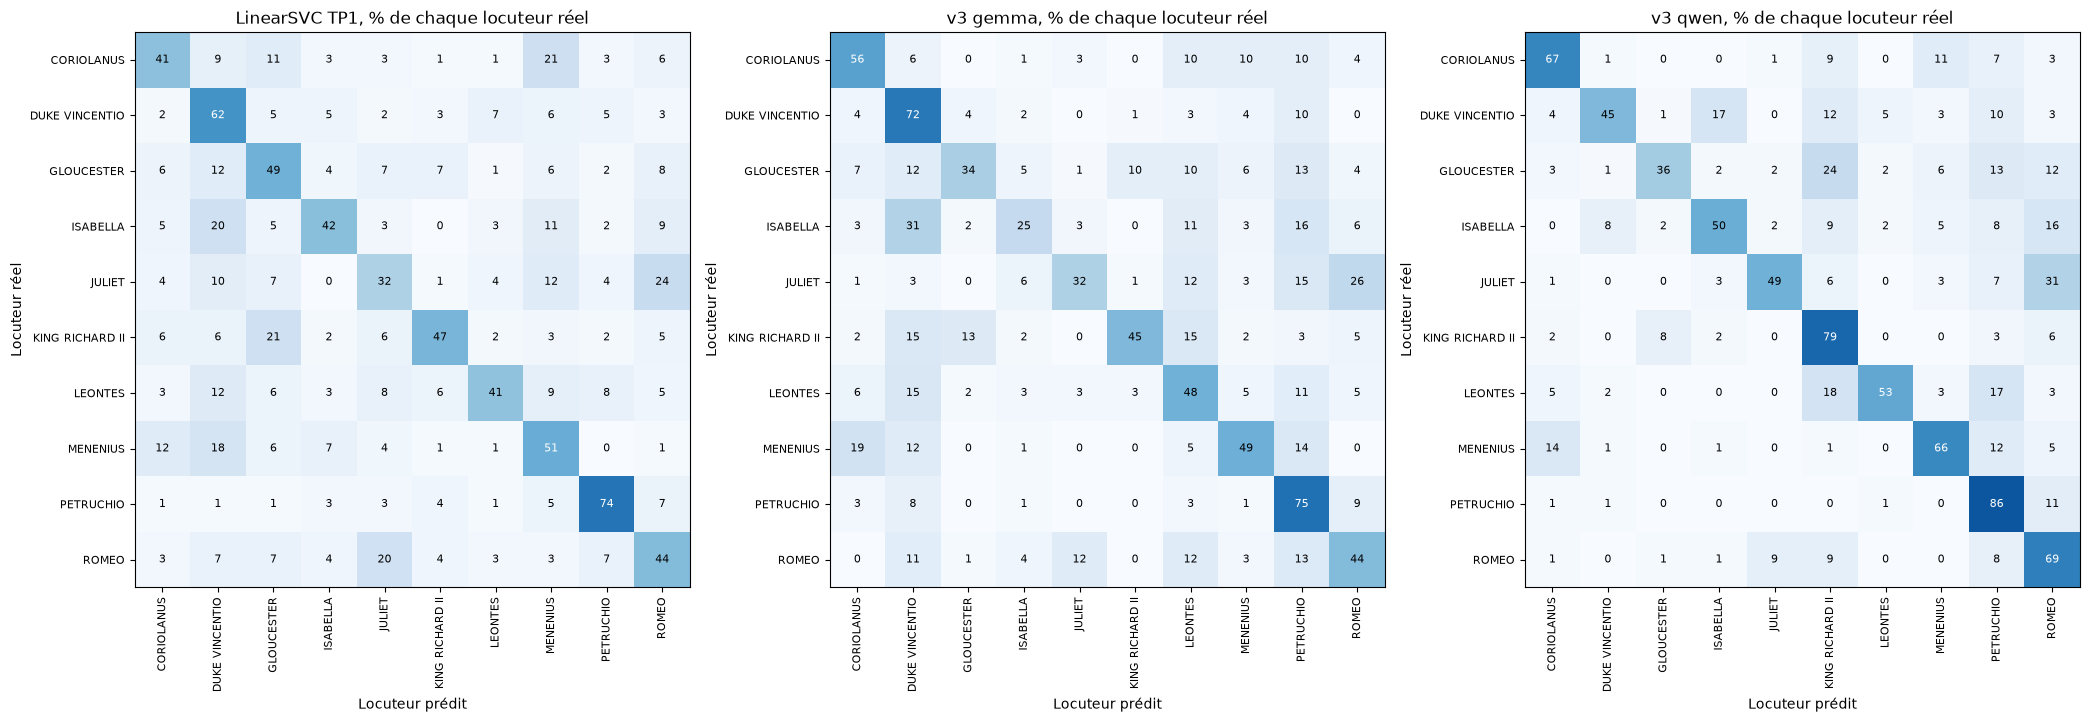

In [40]:
# Matrices de confusion de LinearSVC et de v3 sur les 769 répliques, en % du locuteur réel.
import matplotlib.pyplot as plt


def matrice_confusion(nom: str, registre: dict = resultats,
                      vrais: pd.Series = y_train) -> pd.DataFrame:
    """Effectifs réel × prédit, sorties hors liste ou tronquées dans des colonnes à part."""
    predits = registre[nom]['predictions']
    ratees = [sortie for sortie in (HORS_LISTE, TRONQUEE) if (predits == sortie).any()]
    return pd.crosstab(vrais, predits).reindex(index=NOMS, columns=NOMS + ratees, fill_value=0)


def en_pourcentage(matrice: pd.DataFrame) -> pd.DataFrame:
    """Chaque ligne en % des répliques du locuteur réel."""
    return matrice.apply(lambda ligne: pourcentage(ligne, ligne.sum()), axis=1)


def tracer_matrice(axe, nom: str, matrice: pd.DataFrame) -> None:
    """Carte d'une matrice en % par ligne, valeurs arrondies écrites dans les cases."""
    parts = en_pourcentage(matrice)
    axe.imshow(parts, cmap='Blues', vmin=0, vmax=100)
    for (ligne, colonne), valeur in np.ndenumerate(parts.to_numpy()):
        axe.text(colonne, ligne, f'{valeur:.0f}', ha='center', va='center', fontsize=8,
                 color='white' if valeur > 50 else 'black')
    axe.set_xticks(range(len(parts.columns)), parts.columns, rotation=90, fontsize=8)
    axe.set_yticks(range(len(NOMS)), NOMS, fontsize=8)
    axe.set(title=f'{nom}, % de chaque locuteur réel', xlabel='Locuteur prédit',
            ylabel='Locuteur réel')


matrices = {nom: matrice_confusion(nom) for nom in MEILLEURS}
fig, axes = plt.subplots(1, len(matrices), figsize=(21, 7))
for axe, (nom, matrice) in zip(axes, matrices.items()):
    tracer_matrice(axe, nom, matrice)
plt.tight_layout()
plt.show()

Je résume chaque matrice par son rappel moyen, ses trois plus fortes confusions et les deux couples suivis depuis le TP1. Je donne chaque case en % et en effectifs, car un petit locuteur fait varier un pourcentage avec peu de répliques.

In [41]:
# Rappel moyen, trois plus fortes confusions et couples du TP1 de chaque matrice.
CONFUSIONS_TP1 = [('JULIET', 'ROMEO'), ('ROMEO', 'JULIET'),
                  ('GLOUCESTER', 'DUKE VINCENTIO'), ('DUKE VINCENTIO', 'GLOUCESTER')]


def decrire_case(matrice: pd.DataFrame, reel: str, predit: str) -> str:
    """Part d'une case dans les répliques du locuteur réel, avec les effectifs."""
    case, total = matrice.loc[reel, predit], matrice.loc[reel].sum()
    return f'{reel} → {predit} : {pourcentage(case, total):.1f} % ({case} sur {total})'


def decrire_confusions(matrices: dict) -> None:
    """Rappel moyen, trois plus fortes confusions et couples du TP1 de chaque matrice."""
    for nom, matrice in matrices.items():
        parts = en_pourcentage(matrice)[NOMS]
        hors_diagonale = parts.where(~np.eye(len(NOMS), dtype=bool)).stack().dropna()
        print(f'{nom} : rappel moyen {np.diag(parts).mean():.1f} %')
        for titre, cases in (('plus fortes confusions', hors_diagonale.nlargest(3).index),
                             ('couples suivis depuis le TP1', CONFUSIONS_TP1)):
            print(f'   {titre}')
            for reel, predit in cases:
                print(f'      {decrire_case(matrice, reel, predit)}')


decrire_confusions(matrices)

LinearSVC TP1 : rappel moyen 48.2 %
   plus fortes confusions
      JULIET → ROMEO : 23.5 % (16 sur 68)
      CORIOLANUS → MENENIUS : 21.4 % (15 sur 70)
      KING RICHARD II → GLOUCESTER : 21.0 % (13 sur 62)
   couples suivis depuis le TP1
      JULIET → ROMEO : 23.5 % (16 sur 68)
      ROMEO → JULIET : 20.0 % (15 sur 75)
      GLOUCESTER → DUKE VINCENTIO : 11.7 % (12 sur 103)
      DUKE VINCENTIO → GLOUCESTER : 5.0 % (5 sur 100)
v3 gemma : rappel moyen 48.1 %
   plus fortes confusions
      ISABELLA → DUKE VINCENTIO : 31.2 % (20 sur 64)
      JULIET → ROMEO : 26.5 % (18 sur 68)
      MENENIUS → CORIOLANUS : 18.8 % (16 sur 85)
   couples suivis depuis le TP1
      JULIET → ROMEO : 26.5 % (18 sur 68)
      ROMEO → JULIET : 12.0 % (9 sur 75)
      GLOUCESTER → DUKE VINCENTIO : 11.7 % (12 sur 103)
      DUKE VINCENTIO → GLOUCESTER : 4.0 % (4 sur 100)
v3 qwen : rappel moyen 59.9 %
   plus fortes confusions
      JULIET → ROMEO : 30.9 % (21 sur 68)
      GLOUCESTER → KING RICHARD II : 24.3

> *Mes observations :*
>
> Le rappel moyen vaut 48,2 % pour LinearSVC, 48,1 % pour Gemma et 59,9 % pour Qwen. Les trois plus fortes confusions de Gemma relient des personnages d'une même pièce, ISABELLA vers DUKE VINCENTIO (31,2 %), JULIET vers ROMEO et MENENIUS vers CORIOLANUS. JULIET part de plus en plus vers ROMEO, de 23,5 % chez LinearSVC à 30,9 % chez Qwen, alors que ROMEO vers JULIET baisse de 20,0 % à 9,3 %. Qwen ne confond presque plus GLOUCESTER et DUKE VINCENTIO, avec 1,0 % dans chaque sens. Il envoie pourtant 24,3 % des répliques de GLOUCESTER et 18,2 % de celles de LEONTES vers KING RICHARD II.
>
> *Ma conclusion :* mon hypothèse tient. v3 sur Qwen bat LinearSVC sur les mêmes répliques au-delà du hasard, dans les cinq folds et sur neuf locuteurs sur dix. v3 sur Gemma reste à égalité avec LinearSVC, mais les deux ont raison sur des répliques différentes. Les erreurs des LLM ont une forme propre. Gemma se trompe surtout à l'intérieur d'une pièce, et Qwen attire GLOUCESTER et LEONTES vers KING RICHARD II, JULIET vers ROMEO. La section 4.2 doit donc mesurer la part des erreurs à l'intérieur d'une pièce, et compter les prédictions par classe pour lire cet a priori.

### 4.2 Revenir aux répliques

Je relis les erreurs réplique par réplique avec la sortie brute du modèle, car une étiquette fausse et une sortie hors liste ne racontent pas la même chose. Je sépare d'abord les erreurs dans la pièce et hors de la pièce, avec les pièces reconstruites depuis les seules étiquettes comme au TP2 (section 4.2). Puis je compte les prédictions par classe, car un nom prédit trop souvent trahirait un a priori appris avant ce corpus.

> *Mon hypothèse :* les erreurs des LLM restent plus souvent dans la pièce que celles de LinearSVC, car v3 donne la pièce de chaque personnage mais pas sa voix. Le gain de v3 sur Qwen face à LinearSVC vient surtout des répliques qui citent un nom, car le contexte relie ces noms aux personnages.

Les deux modèles échouent-ils sur les mêmes répliques ? Je mesure leur accord, car deux modèles qui se trompent de la même façon diraient que la limite vient de la tâche. Aucune version retenue n'a d'exemple, donc un biais copié depuis les exemples du prompt ne peut pas exister ici.

In [42]:
# Pièces reconstruites à partir des seules étiquettes du corpus, avec la règle du TP2.
from collections import Counter

ECART_PIECE = 400  # Positions sans le locuteur au-delà desquelles il change de pièce
FENETRE_PIECE = 5  # Répliques suivantes où je cherche une réponse
SEUIL_PIECE = 20  # Réponses nécessaires pour relier deux morceaux


def morceaux_locuteurs() -> dict:
    """Positions de chaque locuteur retenu dans le corpus, coupées aux grands écarts."""
    etiquettes, morceaux = df['locuteur'].to_numpy(), {}
    for locuteur in NOMS:
        positions = np.flatnonzero(etiquettes == locuteur)
        coupures = np.flatnonzero(np.diff(positions) > ECART_PIECE) + 1
        for numero, bloc in enumerate(np.split(positions, coupures), start=1):
            morceaux[(locuteur, numero)] = bloc
    return morceaux


def compter_reponses(morceaux: dict) -> Counter:
    """Fois où deux morceaux de locuteurs différents se suivent à moins de la fenêtre."""
    morceau_de = {position: cle for cle, bloc in morceaux.items() for position in bloc}
    liens = Counter()
    for position, cle in morceau_de.items():
        for suivante in range(position + 1, position + FENETRE_PIECE + 1):
            autre = morceau_de.get(suivante)
            if autre is not None and autre[0] != cle[0]:
                liens[tuple(sorted((cle, autre)))] += 1
    return liens


def numeroter_pieces(morceaux: dict, liens: Counter) -> dict:
    """Pièce de chaque morceau : liens d'au moins SEUIL_PIECE réponses, numéros dans l'ordre."""
    parent = {cle: cle for cle in morceaux}

    def racine(cle):
        while parent[cle] != cle:
            cle = parent[cle]
        return cle

    for (a, b), nombre in liens.items():
        if nombre >= SEUIL_PIECE:
            parent[racine(a)] = racine(b)
    debuts = {}
    for cle, bloc in morceaux.items():
        debuts[racine(cle)] = min(debuts.get(racine(cle), bloc[0]), bloc[0])
    numeros = {r: k for k, r in enumerate(sorted(debuts, key=debuts.get), start=1)}
    return {cle: numeros[racine(cle)] for cle in morceaux}


# Morceaux, liens et pièces
morceaux = morceaux_locuteurs()
liens = compter_reponses(morceaux)
piece_morceau = numeroter_pieces(morceaux, liens)

# Pièce de chaque réplique de développement, par sa position dans le corpus
assert (df.loc[X_train.index, 'locuteur'] == y_train).all()  # Indices du TP1 conservés
piece_position = {p: piece_morceau[cle] for cle, bloc in morceaux.items() for p in bloc}
pieces_du_locuteur = {locuteur: {piece for (nom, _), piece in piece_morceau.items()
                                 if nom == locuteur} for locuteur in NOMS}

# Morceaux de chaque pièce, avec leurs répliques de développement entre parenthèses
developpement = set(X_train.index)
for piece in sorted(set(piece_morceau.values())):
    membres = [f'{nom} {numero} ({len(developpement.intersection(morceaux[(nom, numero)]))})'
               for (nom, numero), p in piece_morceau.items() if p == piece]
    print(f'Pièce {piece} : {", ".join(membres)}')

Pièce 1 : CORIOLANUS 1 (70), MENENIUS 1 (85)
Pièce 2 : GLOUCESTER 1 (78)
Pièce 3 : KING RICHARD II 1 (62)
Pièce 4 : JULIET 1 (67), ROMEO 1 (75)
Pièce 5 : GLOUCESTER 2 (25)
Pièce 6 : LEONTES 1 (66)
Pièce 7 : DUKE VINCENTIO 1 (100), ISABELLA 1 (64), JULIET 2 (1)
Pièce 8 : PETRUCHIO 1 (76)


> *Mes observations :*
>
> Je retrouve les huit pièces du TP2. GLOUCESTER a deux morceaux, avec 78 répliques de développement dans la pièce 2 et 25 dans la pièce 5. Le second JULIET, dans la pièce de DUKE VINCENTIO et d'ISABELLA, ne porte qu'une réplique de développement. Le contexte de v3, qui place JULIET dans Romeo and Juliet, ne peut donc presque rien coûter ici.

Je mesure d'abord la part des erreurs qui restent dans la pièce de la réplique. Je la compare au hasard, où l'erreur tomberait sur l'un des neuf autres locuteurs avec la même chance. Comparer v0 et v3 dit si le contexte des pièces pousse les erreurs dans la pièce.

In [43]:
# Part des erreurs restées dans la pièce de la réplique, face au hasard, pour LinearSVC et les LLM.
INTRA = ['LinearSVC TP1'] + COUPLES


def dans_la_piece(indice, predit: str) -> bool:
    """Vrai si le locuteur prédit a un morceau dans la pièce de la réplique."""
    return piece_position[indice] in pieces_du_locuteur.get(predit, set())  # Hors liste : non


def part_intra(nom: str) -> dict:
    """Erreurs, part restée dans la pièce de la réplique et part attendue au hasard."""
    predits = resultats[nom]['predictions']
    erreurs = predits.index[predits != y_train]
    dedans = sum(dans_la_piece(i, predits.loc[i]) for i in erreurs)
    # Hasard : l'erreur tombe sur l'un des neuf autres locuteurs, chacun avec la même chance
    hasard = sum(dans_la_piece(i, autre) for i in erreurs for autre in NOMS
                 if autre != y_train.loc[i]) / (len(NOMS) - 1)
    return {'Modèle': nom, 'Erreurs': len(erreurs),
            'Dans la pièce (%)': pourcentage(dedans, len(erreurs)),
            'Hasard (%)': pourcentage(hasard, len(erreurs)), 'Rapport au hasard': dedans / hasard}


display(pd.DataFrame([part_intra(nom) for nom in INTRA]).set_index('Modèle').round(2))

,Erreurs,Dans la pièce (%),Hasard (%),Rapport au hasard
Modèle,,,,
LinearSVC TP1,391,20.20,9.15,2.21
v0 gemma,534,10.11,8.86,1.14
v3 gemma,393,18.58,8.91,2.09
v0 qwen,391,22.76,9.01,2.53
v3 qwen,318,22.01,9.96,2.21


> *Mes observations :*
>
> LinearSVC garde 20,2 % de ses erreurs dans la pièce, soit 2,21 fois le hasard. v3 fait autant chez Qwen (22,0 %, 2,21 fois) et un peu moins chez Gemma (18,6 %). Le contexte double la part de Gemma, de 10,1 % avec v0 à 18,6 % avec v3, alors que Qwen est déjà à 22,8 % avec v0. Cela rejoint la section 3.4, où Gemma situait 3 pièces sur 10 et Qwen 9.

Je compte ensuite combien de fois chaque modèle prédit chaque locuteur, face à ses effectifs réels. Un rapport au-dessus de 1 signale un nom prédit trop souvent, donc un a priori du modèle. v0 montre cet a priori sans contexte, et v3 avec le contexte des pièces.

In [44]:
# Prédictions par locuteur face aux effectifs réels, puis rapport des prédictions au réel.
RATEES = [HORS_LISTE, TRONQUEE]
predites = pd.DataFrame({nom: resultats[nom]['predictions'].value_counts() for nom in INTRA})
predites = predites.reindex(NOMS + RATEES).fillna(0).astype(int)
predites.insert(0, 'Réel', y_train.value_counts().reindex(NOMS + RATEES).fillna(0).astype(int))
display(predites)
display(predites.loc[NOMS, INTRA].div(predites.loc[NOMS, 'Réel'], axis=0).round(2))

,Réel,LinearSVC TP1,v0 gemma,v3 gemma,v0 qwen,v3 qwen
CORIOLANUS,70,62,101,76,127,73
DUKE VINCENTIO,100,133,148,153,30,55
GLOUCESTER,103,99,123,50,3,45
ISABELLA,64,52,4,36,73,56
JULIET,68,64,18,38,48,44
KING RICHARD II,62,52,8,42,164,122
LEONTES,66,46,118,91,29,44
MENENIUS,85,99,19,70,116,80
PETRUCHIO,76,80,85,138,73,132
ROMEO,75,82,141,75,104,118


,LinearSVC TP1,v0 gemma,v3 gemma,v0 qwen,v3 qwen
CORIOLANUS,0.89,1.44,1.09,1.81,1.04
DUKE VINCENTIO,1.33,1.48,1.53,0.30,0.55
GLOUCESTER,0.96,1.19,0.49,0.03,0.44
ISABELLA,0.81,0.06,0.56,1.14,0.88
JULIET,0.94,0.26,0.56,0.71,0.65
KING RICHARD II,0.84,0.13,0.68,2.65,1.97
LEONTES,0.70,1.79,1.38,0.44,0.67
MENENIUS,1.16,0.22,0.82,1.36,0.94
PETRUCHIO,1.05,1.12,1.82,0.96,1.74
ROMEO,1.09,1.88,1.00,1.39,1.57


> *Mes observations :*
>
> LinearSVC prédit chaque locuteur entre 0,70 et 1,33 fois son effectif réel, alors que les LLM s'en écartent bien plus. ROMEO est trop prédit par v0 sur Gemma (1,88), par v0 sur Qwen (1,39) et par v3 sur Qwen (1,57). JULIET est au contraire sous-prédite partout, de 0,26 à 0,71. Qwen avec v0 ne dit GLOUCESTER que 3 fois pour 103 répliques, mais KING RICHARD II 164 fois pour 62.
>
> *Mon hypothèse :* Qwen attribue les répliques de Richard, duc de Gloucester, au seul roi Richard de la liste. v3 remonte GLOUCESTER à 45 prédictions, sans combler l'écart.

Je mesure l'accord entre deux modèles, sur l'étiquette puis sur l'erreur quand les deux se trompent. Si deux modèles se trompent souvent de la même façon, la limite vient plutôt de la réplique que du modèle. Je compte aussi les répliques que les six configurations ratent toutes.

In [45]:
# Accord entre deux modèles : même étiquette, erreurs communes, même erreur, puis ratées par tous.
ACCORDS = [('v3 gemma', 'v3 qwen'), ('LinearSVC TP1', 'v3 gemma'), ('LinearSVC TP1', 'v3 qwen')]


def accord(a: str, b: str) -> dict:
    """Part d'étiquettes identiques, répliques fausses pour les deux et part de la même erreur."""
    predits_a, predits_b = resultats[a]['predictions'], resultats[b]['predictions']
    deux_faux = (predits_a != y_train) & (predits_b != y_train)
    meme_erreur = (deux_faux & (predits_a == predits_b)).sum()
    return {'A': a, 'B': b,
            'Même étiquette (%)': pourcentage((predits_a == predits_b).sum(), len(y_train)),
            'Deux faux': int(deux_faux.sum()),
            'Même erreur (%)': pourcentage(meme_erreur, deux_faux.sum())}


display(pd.DataFrame([accord(a, b) for a, b in ACCORDS]).set_index(['A', 'B']).round(1))
justes = pd.DataFrame({nom: resultats[nom]['predictions'] == y_train for nom in INTRA})
rates_par_tous = justes.index[~justes.any(axis=1)].sort_values()  # Ordre du corpus
print(f'Répliques ratées par les six : {len(rates_par_tous)} sur {len(justes)}, '
      f'soit {pourcentage(len(rates_par_tous), len(justes)):.1f} %')

Même étiquette (%)  Deux faux  Même erreur (%)
A             B                                                       
v3 gemma      v3 qwen                 49.4        241             33.6
LinearSVC TP1 v3 gemma                36.9        254             17.7
              v3 qwen                 40.4        212             18.4

Répliques ratées par les six : 132 sur 769, soit 17.2 %


> *Mes observations :*
>
> v3 sur Gemma et v3 sur Qwen donnent la même étiquette sur 49,4 % des répliques. Quand les deux se trompent, ils choisissent le même mauvais nom dans 33,6 % des cas. Avec LinearSVC, cette part tombe à 17,7 % pour Gemma et 18,4 % pour Qwen. Les six configurations ratent ensemble 132 répliques, soit 17,2 %.

Je sépare les répliques qui citent un nom de la liste ou du contexte de v3, avec le même repérage que dans la section 3.4. Je compte ce que v3 corrige et casse face à LinearSVC dans chaque groupe, puis je ramène le gain net à 100 répliques.

In [46]:
# Répliques corrigées et cassées par v3 face à LinearSVC, selon qu'elles citent un nom ou non.
MOTIF_CITE = '|'.join(rf'\b{nom}\b' for nom in NOMS_CITES)  # Nom entier, comme en 3.4
cite_769 = X_train.str.contains(MOTIF_CITE)


def ligne_cite(nom: str, libelle: str, masque: pd.Series, registre: dict = resultats,
               vrais: pd.Series = y_train) -> dict:
    """Bilan face à LinearSVC sur un groupe de répliques, gain net pour 100 et justesses."""
    vrais, svc = vrais[masque], registre['LinearSVC TP1']['predictions'][masque]
    predits = registre[nom]['predictions'][masque]
    bilan = bilan_changement(vrais, svc, predits)
    return {'Modèle': nom, 'Répliques': libelle, 'Nombre': int(masque.sum()), **bilan,
            'Gain net pour 100': pourcentage(bilan['Gain net'], masque.sum()),
            'Justesse LinearSVC (%)': pourcentage((svc == vrais).sum(), masque.sum()),
            'Justesse du modèle (%)': pourcentage((predits == vrais).sum(), masque.sum())}


lignes_cite = [ligne_cite(nom, libelle, masque) for nom in ('v3 gemma', 'v3 qwen')
               for libelle, masque in (('avec nom cité', cite_769), ('sans nom cité', ~cite_769))]
display(pd.DataFrame(lignes_cite).set_index(['Modèle', 'Répliques']).round(1))

Nombre  Corrigées  Cassées  Gain net  \
Modèle   Répliques                                             
v3 gemma avec nom cité     258         50       31        19   
         sans nom cité     511         87      108       -21   
v3 qwen  avec nom cité     258         63       19        44   
         sans nom cité     511        116       87        29   

                        Gain net pour 100  Justesse LinearSVC (%)  \
Modèle   Répliques                                                  
v3 gemma avec nom cité                7.4                    64.3   
         sans nom cité               -4.1                    41.5   
v3 qwen  avec nom cité               17.1                    64.3   
         sans nom cité                5.7                    41.5   

                        Justesse du modèle (%)  
Modèle   Répliques                              
v3 gemma avec nom cité                    71.7  
         sans nom cité                    37.4  
v3 qwen  avec nom cité                    81.4  
         sans nom cité                    47.2

> *Mes observations :*
>
> 258 répliques citent un nom, et LinearSVC y atteint 64,3 % de justesse contre 41,5 % sur les 511 autres. v3 sur Qwen gagne 17,1 répliques nettes pour 100 avec un nom cité, et 5,7 sans nom. v3 sur Gemma gagne 7,4 pour 100 avec un nom, mais perd 4,1 pour 100 sans nom. Qwen atteint 81,4 % de justesse sur les répliques qui citent un nom.

Je relis enfin des répliques entières, prises dans l'ordre du corpus pour ne pas choisir les cas. Je commence par les sorties hors liste ou tronquées de v0, puis trois répliques que les six ratent, puis trois que seul v3 sur Qwen rattrape.

In [47]:
# Répliques entières : sorties ratées de v0, puis ratées par tous et rattrapées par Qwen seul.
A_RELIRE = 3  # Répliques affichées par groupe
SORTIE_MAX = 300  # Caractères affichés d'une sortie brute


def afficher_replique(indice) -> None:
    """Locuteur réel, étiquette de chaque modèle, puis la réplique entière."""
    etiquettes = ', '.join(f'{nom} {resultats[nom]["predictions"].loc[indice]}' for nom in INTRA)
    print(f'[{indice}] réel {y_train.loc[indice]} | {etiquettes}')
    print(f'   {X_train.loc[indice]}')


# Sorties hors liste ou tronquées de v0, avec leur texte brut
for nom in ('v0 gemma', 'v0 qwen'):
    predits, table = resultats[nom]['predictions'], resultats[nom]['mesures']
    for indice in predits.index[predits.isin(RATEES)].sort_values():
        print(f'{nom} [{indice}] réel {y_train.loc[indice]}, {predits.loc[indice]}, '
              f'sortie {table.loc[indice, "contenu"][:SORTIE_MAX]!r}')

# Trois répliques ratées par les six, puis trois que seul v3 sur Qwen rattrape
print(f'\nRatées par les six, les {A_RELIRE} premières')
for indice in rates_par_tous[:A_RELIRE]:
    afficher_replique(indice)
seul_qwen = justes.index[justes['v3 qwen'] & ~justes['LinearSVC TP1'] & ~justes['v3 gemma']]
print(f'\nRattrapées par v3 sur Qwen seul : {len(seul_qwen)}, les {A_RELIRE} premières')
for indice in seul_qwen.sort_values()[:A_RELIRE]:
    afficher_replique(indice)

v0 gemma [593] réel MENENIUS, hors liste, sortie 'ANTONY'
v0 gemma [1098] réel GLOUCESTER, hors liste, sortie 'RICHARD II'
v0 gemma [3227] réel JULIET, hors liste, sortie 'GERTRUDE'
v0 gemma [5916] réel ISABELLA, hors liste, sortie 'CLAUDIUS'
v0 qwen [3131] réel JULIET, tronquée, sortie "This is a famous soliloquy from *The Merchant of Venice*, spoken by Portia. However, looking at the provided list of speakers (CORIOLANUS, DUKE VINCENTIO, GLOUCESTER, ISABELLA, JULIET, KING RICHARD II, LEONTES, MENENIUS, PETRUCHIO, ROMEO), none of them are Portia.\n\nLet's re-evaluate the quote and th"
v0 qwen [6100] réel PETRUCHIO, hors liste, sortie 'LORENZO'

Ratées par les six, les 3 premières
[34] réel MENENIUS | LinearSVC TP1 JULIET, v0 gemma PETRUCHIO, v3 gemma PETRUCHIO, v0 qwen CORIOLANUS, v3 qwen PETRUCHIO
   What then? 'Fore me, this fellow speaks! What then? what then?
[265] réel MENENIUS | LinearSVC TP1 DUKE VINCENTIO, v0 gemma GLOUCESTER, v3 gemma CORIOLANUS, v0 qwen CORIOLANUS, v3 qwen C

> *Mes observations :*
>
> Les six sorties ratées de v0 sont des noms d'autres pièces, ANTONY, GERTRUDE, CLAUDIUS ou LORENZO, ou bien « RICHARD II » pour une réplique de GLOUCESTER. La sortie tronquée de Qwen reconnaît une tirade de Portia, puis cherche longuement un nom de la liste. Les trois répliques que les six ratent sont de MENENIUS. Deux sont très courtes, et la troisième cite Marcius, ce qui envoie trois des quatre LLM vers CORIOLANUS. Les trois que seul Qwen rattrape sont aussi de MENENIUS, dont deux passages de sa fable du ventre.
>
> *Ma conclusion :* ma première hypothèse est réfutée. Les erreurs de v3 restent dans la pièce à peu près autant que celles de LinearSVC, environ deux fois le hasard, et le contexte ne fait qu'y amener Gemma. Ma seconde hypothèse tient, car Qwen gagne trois fois plus par réplique quand un nom est cité. Il gagne pourtant aussi sans nom, là où Gemma perd.
>
> Sans contexte, les deux LLM prédisent trop ROMEO et trop peu JULIET, et Qwen attribue Richard de Gloucester à KING RICHARD II, comme Gemma dans sa sortie « RICHARD II ». Les deux LLM partagent donc leurs erreurs presque deux fois plus qu'avec LinearSVC (33,6 % contre environ 18 %), ce qui rend LinearSVC complémentaire. Pour le test, j'attends un gain de Qwen porté surtout par les répliques à nom cité, car les mêmes pièces reviennent.

### 4.3 Qualité, coût et latence

> *Mon hypothèse :* le LLM coûte au moins cent fois la latence de LinearSVC par réplique, et le grand modèle au moins deux fois celle du petit. Ce sont les tests de H5 et de H6.

Je compare les pipelines sur trois axes, la qualité en F1 macro, le coût en tokens et en temps, la latence par réplique. Les modèles sont locaux, donc le coût se lit en tokens, en secondes et en taille, et un prix par token le convertirait pour une API. Je ne garde que les mesures des appels réels stockés dans le cache, chargement exclu.

| Colonne | Ce qu'elle mesure |
|---|---|
| F1 macro, écart-type | Qualité moyenne sur les cinq folds et sa dispersion. |
| Conformité, tronquées | Part des sorties lues comme une étiquette, et nombre de sorties coupées par la borne. |
| Tokens du prompt | Taille médiane du contexte payé par appel, préfixe compris. |
| Tokens générés | Longueur médiane de la sortie produite. |
| Latence par réplique (ms) | Durée médiane d'un appel hors chargement, ou temps de prédiction par réplique pour le ML. |
| Temps des 769 (min) | Coût d'une évaluation complète, appels du LLM ou ajustements des cinq folds. |
| Taille (Mio) | Taille sur disque du LLM, ou du pipeline LinearSVC sérialisé. |
| Bascule (s) | Chargement payé en changeant de modèle, mesuré dans la section 2.5. |
| Entraînement (s) | Temps d'ajustement pour le ML, zéro pour le LLM. |

Les folds ne portent que des configurations directes, donc le coût du raisonnement reste celui de la section 3.5. Le rapport de latence face à LinearSVC dépend de la configuration, donc je le donne par ligne et non comme un chiffre unique. Un pipeline hybride, LinearSVC d'abord puis le LLM sur les cas incertains, se simule sans nouvel appel, donc je le mesure ensuite.

In [48]:
# Temps d'ajustement, temps de prédiction par réplique et taille de LinearSVC TP1 sur le fold 1.
import pickle
import timeit

REPETITIONS = 20  # Mesures répétées, la médiane écarte les à-coups de la machine


def chronometrer_svc(fold: dict) -> dict:
    """Ajustement, prédiction par réplique (médianes) et taille de LinearSVC TP1 sur un fold."""
    textes, cibles = X_train.loc[fold['train']], y_train.loc[fold['train']]
    validation = X_train.loc[fold['validation']]
    ajustements = timeit.repeat(lambda: construire_svc_tp1().fit(textes, cibles), number=1,
                                repeat=REPETITIONS)
    pipeline = construire_svc_tp1().fit(textes, cibles)
    predictions = timeit.repeat(lambda: pipeline.predict(validation), number=1,
                                repeat=REPETITIONS)
    return {'Entraînement (s)': np.median(ajustements),
            'Latence par réplique (ms)': 1000 * np.median(predictions) / len(validation),
            'Taille (Mio)': len(pickle.dumps(pipeline)) / 2**20}


MESURES_SVC = chronometrer_svc(folds[0])
for cle, valeur in MESURES_SVC.items():
    print(f'LinearSVC TP1, {cle} : {valeur:.4f}')

LinearSVC TP1, Entraînement (s) : 0.0327
LinearSVC TP1, Latence par réplique (ms) : 0.0215
LinearSVC TP1, Taille (Mio) : 0.4700


Je rassemble ensuite chaque pipeline sur une ligne, avec le rapport de sa latence à celle de LinearSVC. Le coût de bascule est la médiane des chargements mesurés dans la section 2.5 quand le modèle change.

In [49]:
# Tableau qualité, coût et latence, une ligne par pipeline, et rapport de latence à LinearSVC.
BASCULE = bascules.iloc[:-1].groupby('Modèle')['Chargement (s)'].median()  # Appels avec bascule


def ligne_cout(nom: str) -> dict:
    """Qualité, conformité, tokens, latence, temps, taille et bascule d'une entrée LLM."""
    table, modele = resultats[nom]['mesures'], nom.split()[-1]
    score, f1 = scorer_table(table), resultats[nom]['folds']['F1 macro']
    return {'Modèle': nom, 'F1 macro': f1.mean(), 'Écart-type': f1.std(),
            'Conformité (%)': score['Conformité (%)'], 'Tronquées': score['Tronquées'],
            'Tokens du prompt': table['tokens prompt'].median(),
            'Tokens générés': score['Tokens générés (médiane)'],
            'Latence par réplique (ms)': 1000 * score['Latence hors chargement (s)'],
            'Temps des 769 (min)': temps_appels(table) / 60,
            'Taille (Mio)': tailles[MODELES[modele]] / 2**20,
            'Bascule (s)': BASCULE[modele], 'Entraînement (s)': 0.0}


def ligne_cout_svc() -> dict:
    """Les mêmes colonnes pour LinearSVC TP1, sans tokens ni bascule."""
    folds_svc = resultats['LinearSVC TP1']['folds']
    return {'Modèle': 'LinearSVC TP1', 'F1 macro': folds_svc['F1 macro'].mean(),
            'Écart-type': folds_svc['F1 macro'].std(), 'Conformité (%)': 100.0, 'Tronquées': 0,
            'Tokens du prompt': np.nan, 'Tokens générés': np.nan,
            'Latence par réplique (ms)': MESURES_SVC['Latence par réplique (ms)'],
            'Temps des 769 (min)': folds_svc['Temps (s)'].sum() / 60,
            'Taille (Mio)': MESURES_SVC['Taille (Mio)'], 'Bascule (s)': 0.0,
            'Entraînement (s)': MESURES_SVC['Entraînement (s)']}


couts = pd.DataFrame([ligne_cout_svc()] + [ligne_cout(nom) for nom in COUPLES]).set_index('Modèle')
couts['Rapport de latence à LinearSVC'] = (couts['Latence par réplique (ms)']
                                           / MESURES_SVC['Latence par réplique (ms)'])
display(couts.round(3))

,F1 macro,Écart-type,Conformité (%),Tronquées,Tokens du prompt,Tokens générés,Latence par réplique (ms),Temps des 769 (min),Taille (Mio),Bascule (s),Entraînement (s),Rapport de latence à LinearSVC
Modèle,,,,,,,,,,,,
LinearSVC TP1,0.482,0.039,100.00,0,NaN,NaN,0.021,0.004,0.470,0.000,0.033,1.000
v0 gemma,0.271,0.030,99.48,0,128.0,5.0,265.410,3.589,9253.559,4.025,0.000,12367.219
v3 gemma,0.472,0.068,100.00,0,412.0,19.0,640.744,8.380,9253.559,4.025,0.000,29856.532
v0 qwen,0.479,0.027,99.74,1,134.0,5.0,1080.799,17.817,11069.843,2.958,0.000,50361.620
v3 qwen,0.584,0.057,100.00,0,428.0,10.0,1354.839,19.169,11069.843,2.958,0.000,63130.957


> *Mes observations :*
>
> LinearSVC prédit une réplique en quelques centièmes de milliseconde, alors que le LLM met de 265 ms (v0 sur Gemma) à 1 355 ms (v3 sur Qwen). Le rapport de latence dépasse donc mille fois sur chaque ligne. Les 769 répliques demandent de 3,6 à 19,2 min d'appels, contre une fraction de seconde pour les cinq ajustements de LinearSVC. Chaque LLM pèse plus de 9 000 Mio sur disque, contre moins de 1 Mio pour LinearSVC. Le contexte de v3 triple le prompt, de 128 à 412 tokens chez Gemma, et multiplie la latence par 2,4 chez Gemma et par 1,25 chez Qwen.

Je place chaque pipeline dans le plan qualité et latence, avec une échelle logarithmique, car les latences s'étalent sur plusieurs ordres de grandeur. La barre verticale donne l'écart-type entre folds.

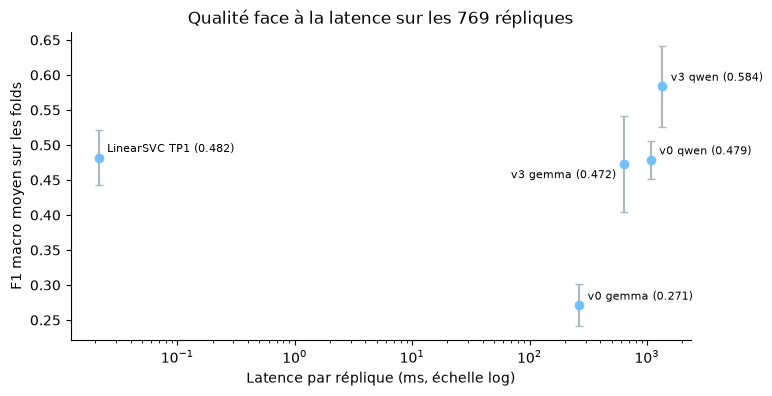

In [50]:
# F1 macro moyen face à la latence par réplique, échelle logarithmique, écart-type en barre.
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(couts['Latence par réplique (ms)'], couts['F1 macro'], yerr=couts['Écart-type'],
            fmt='o', color='#74c0fc', ecolor='#adb5bd', capsize=3)
for nom, ligne in couts.iterrows():
    gauche = nom == 'v3 gemma'  # Étiquette à gauche, sinon elle recouvre celle de v0 qwen
    ax.annotate(f'{nom} ({ligne["F1 macro"]:.3f})',
                (ligne['Latence par réplique (ms)'], ligne['F1 macro']),
                textcoords='offset points', xytext=(-6, -10) if gauche else (6, 4),
                ha='right' if gauche else 'left', fontsize=8)
ax.set_xscale('log')
ax.set(xlabel='Latence par réplique (ms, échelle log)', ylabel='F1 macro moyen sur les folds',
       title='Qualité face à la latence sur les 769 répliques')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

> *Mes observations :*
>
> Le graphique sépare LinearSVC, à gauche, des LLM placés environ quatre ordres de grandeur plus loin. Seul v3 sur Qwen monte au-dessus de LinearSVC, et sa barre d'écart-type ne recouvre pas la sienne. v3 sur Gemma et v0 sur Qwen restent à la hauteur de LinearSVC, pour une latence bien plus forte.

Je simule le pipeline hybride avec les prédictions déjà connues. LinearSVC garde les répliques où l'écart entre ses deux meilleurs scores est grand, et v3 répond aux autres. Je fais varier la part envoyée au LLM de 0 à 100 %, et je calcule la latence moyenne attendue par réplique.

In [51]:
# Pipeline hybride simulé : LinearSVC garde les répliques où il est sûr, v3 répond aux autres.
PARTS_LLM = np.round(np.linspace(0, 1, 11), 1)  # Part des répliques envoyées au LLM
HYBRIDES = ['v3 gemma', 'v3 qwen']


def marges_svc() -> pd.Series:
    """Écart entre les deux meilleurs scores de LinearSVC TP1, hors fold, pour chaque réplique."""
    marges, svc = pd.Series(index=X_train.index, dtype=float), resultats['LinearSVC TP1']
    for fold in folds:
        validation = X_train.loc[fold['validation']]
        pipeline = construire_svc_tp1().fit(X_train.loc[fold['train']],
                                            y_train.loc[fold['train']])
        assert (pipeline.predict(validation) == svc['predictions'].loc[fold['validation']]).all()
        tries = np.sort(pipeline.decision_function(validation), axis=1)
        marges.loc[fold['validation']] = tries[:, -1] - tries[:, -2]
    return marges


def hybride(nom: str, marges: pd.Series, part: float) -> dict:
    """F1 macro par fold et latence attendue quand le LLM répond aux plus faibles marges."""
    au_llm = marges.rank(method='first') <= part * len(marges)
    predits = resultats['LinearSVC TP1']['predictions'].where(~au_llm,
                                                              resultats[nom]['predictions'])
    f1 = pd.Series([f1_score(y_train.loc[fold['validation']], predits.loc[fold['validation']],
                             labels=NOMS, average='macro', zero_division=0) for fold in folds])
    latence = (MESURES_SVC['Latence par réplique (ms)']
               + part * couts.loc[nom, 'Latence par réplique (ms)'])
    return {'LLM': nom, 'Part au LLM (%)': round(100 * part), 'Appels au LLM': int(au_llm.sum()),
            'F1 macro': f1.mean(), 'Écart-type': f1.std(), 'Latence moyenne (ms)': latence}


marges = marges_svc()
simulation = pd.DataFrame([hybride(nom, marges, part) for nom in HYBRIDES for part in PARTS_LLM])
for nom in HYBRIDES:  # Aux deux bouts, LinearSVC seul puis le LLM seul
    bouts = simulation[simulation['LLM'] == nom].set_index('Part au LLM (%)')['F1 macro']
    assert np.isclose(bouts[0], couts.loc['LinearSVC TP1', 'F1 macro'])
    assert np.isclose(bouts[100], couts.loc[nom, 'F1 macro'])

# F1 et latence par part, puis la meilleure part de chaque LLM sur les 769
vue = simulation.pivot(index='Part au LLM (%)', columns='LLM',
                       values=['F1 macro', 'Latence moyenne (ms)'])
display(vue.round(3))
for _, ligne in simulation.loc[simulation.groupby('LLM')['F1 macro'].idxmax()].iterrows():
    print(f'{ligne["LLM"]} : meilleure part {ligne["Part au LLM (%)"]} %, '
          f'F1 macro {ligne["F1 macro"]:.3f} ± {ligne["Écart-type"]:.3f}, '
          f'{ligne["Appels au LLM"]} appels, {ligne["Latence moyenne (ms)"]:.0f} ms par réplique')

F1 macro         Latence moyenne (ms)          
LLM             v3 gemma v3 qwen             v3 gemma   v3 qwen
Part au LLM (%)                                                
0                  0.482   0.482                0.021     0.021
10                 0.495   0.506               64.096   135.505
20                 0.497   0.521              128.170   270.989
30                 0.512   0.548              192.245   406.473
40                 0.507   0.563              256.319   541.957
50                 0.530   0.584              320.394   677.441
60                 0.515   0.588              384.468   812.925
70                 0.505   0.592              448.542   948.409
80                 0.500   0.591              512.617  1083.892
90                 0.488   0.597              576.691  1219.376
100                0.472   0.584              640.766  1354.860

v3 gemma : meilleure part 50 %, F1 macro 0.530 ± 0.038, 384 appels, 320 ms par réplique
v3 qwen : meilleure part 90 %, F1 macro 0.597 ± 0.055, 692 appels, 1219 ms par réplique


> *Mes observations :*
>
> Avec Gemma, l'hybride culmine à 0,530 ± 0,038 quand la moitié des répliques va au LLM, au-dessus de LinearSVC (0,482) et de Gemma seul (0,472). Avec Qwen, il atteint déjà 0,584 à 50 %, soit le score de Qwen seul, pour une latence moyenne de 677 ms au lieu de 1 355. Son meilleur point, 0,597 ± 0,055 à 90 %, ne dépasse Qwen seul que de 0,013, bien moins que l'écart-type.

Je trace enfin le F1 macro selon la part envoyée au LLM, une courbe par modèle. Les deux bouts redonnent LinearSVC seul et le LLM seul.

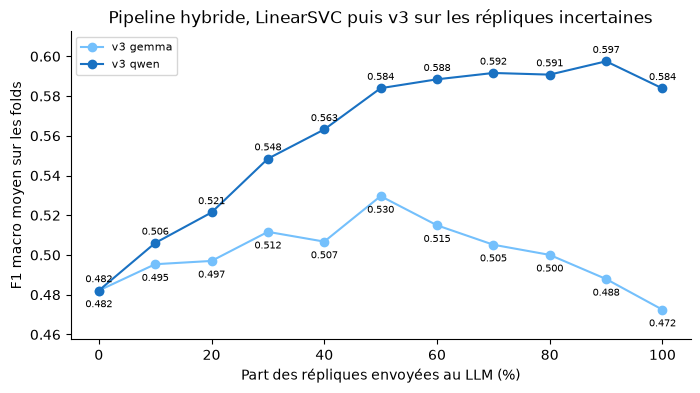

In [52]:
# F1 macro du pipeline hybride selon la part des répliques envoyées au LLM.
fig, ax = plt.subplots(figsize=(8, 4))
for nom, couleur, decalage in zip(HYBRIDES, ('#74c0fc', '#1971c2'), (-12, 6)):
    courbe = simulation[simulation['LLM'] == nom]
    ax.plot(courbe['Part au LLM (%)'], courbe['F1 macro'], marker='o', color=couleur, label=nom)
    for part, f1 in zip(courbe['Part au LLM (%)'], courbe['F1 macro']):  # Gemma sous ses points
        ax.annotate(f'{f1:.3f}', (part, f1), textcoords='offset points', xytext=(0, decalage),
                    ha='center', fontsize=7)
ax.set(xlabel='Part des répliques envoyées au LLM (%)', ylabel='F1 macro moyen sur les folds',
       title='Pipeline hybride, LinearSVC puis v3 sur les répliques incertaines')
ax.margins(y=0.12)  # Place pour les valeurs sous les points de Gemma
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

> *Mes observations :*
>
> La courbe de Qwen monte vite jusqu'à 50 %, puis reste presque plate. Celle de Gemma redescend après 50 %, donc Gemma rate plus souvent que LinearSVC les répliques où LinearSVC est sûr.
>
> *Ma conclusion :* H5 tient pour la latence, car chaque LLM dépasse mille fois celle de LinearSVC. Sa règle ne justifie que v3 sur Qwen, dont le gain de 0,102 sur LinearSVC dépasse l'écart-type des folds. H6 tient pour le coût, car Qwen coûte 4,1 fois la latence de Gemma avec v0 et 2,1 fois avec v3, pour une taille à peine plus grande.
>
> L'hybride change pourtant le compromis. Avec la moitié des appels, il garde le score de Qwen seul et divise sa latence moyenne par deux. Avec Gemma, il dépasse les deux briques seules, ce qui rejoint leurs erreurs différentes de la section 4.1. Ces parts sont choisies sur les 769, donc elles restent exploratoires, et le test de la section 4.4 ne porte que sur les choix figés.

### 4.4 Figer le prompt et évaluer sur le test

Je fige v3 pour les deux modèles, car elle bat v0 hors des 50 répliques chez chacun (section 3.6). v3 n'a aucun exemple, donc rien n'est tiré du développement, et LinearSVC est réajusté sur les 769 répliques. Je passe aussi v0 sur le test, comme témoin de ce que le contexte apporte sur des répliques jamais vues.

> *Mon hypothèse :* le classement des folds se retrouve sur le test, avec v3 sur Qwen devant LinearSVC, puis LinearSVC proche de v3 sur Gemma. Avec 193 répliques, l'intervalle de chaque score est large, donc un écart de quelques points ne suffira pas à départager.

Je compare sur les mêmes 193 répliques, avec le repère du TP1 de 0,563 pour LinearSVC, puis j'analyse les erreurs sans relancer d'itération. Ce test a déjà servi au TP1 pour choisir LinearSVC, donc la comparaison reste exploratoire.

In [53]:
# Test : repères ML réajustés sur les 769 répliques, puis v0 et v3 des deux modèles sur les 193.
resultats_test = {}  # nom -> prédictions des 193 répliques de test, mesures et temps


def evaluer_ml_test(nom: str, construire_pipeline) -> None:
    """Pipeline neuf ajusté sur les 769 répliques, puis une seule prédiction du test."""
    debut = time.perf_counter()
    pipeline = construire_pipeline().fit(X_train, y_train)
    resultats_test[nom] = {'famille': 'ML', 'temps': time.perf_counter() - debut,
                           'predictions': pd.Series(pipeline.predict(X_test), index=X_test.index)}


def evaluer_llm_test(nom: str, modele: str) -> None:
    """Une version figée sur les 193 répliques de test, sans exemple, appels mis en cache."""
    version = VERSIONS[nom]
    assert not version['tirage']  # Rien n'est tiré du développement
    appel = version['appel']
    table = mesurer_appels(modele, version, X_test.index, appel['format'], appel['think'],
                           textes=X_test)
    table['vrai'] = y_test
    resultats_test[f'{nom} {modele}'] = {'famille': 'LLM', 'predictions': lire_etiquettes(table),
                                         'mesures': table, 'temps': temps_appels(table)}


# Repères ML, puis v0 et v3 de chaque modèle, tous les appels de Gemma avant ceux de Qwen
for nom, construire in REPERES.items():
    evaluer_ml_test(nom, construire)
travaux = [(modele, lambda nom=nom, modele=modele: evaluer_llm_test(nom, modele))
           for modele in MODELES for nom in CONFIGURATIONS_FOLDS]
grouper_par_modele(travaux)
for nom in COUPLES:
    print(f'{nom} : {len(resultats_test[nom]["mesures"])} appels, '
          f'{resultats_test[nom]["temps"] / 60:.1f} min hors chargement')

v0 gemma : 193 appels, 0.9 min hors chargement
v3 gemma : 193 appels, 2.1 min hors chargement
v0 qwen : 193 appels, 4.5 min hors chargement
v3 qwen : 193 appels, 5.1 min hors chargement


Je donne chaque score du test avec un intervalle bootstrap à 95 %, car 193 répliques laissent une forte incertitude. Le bootstrap retire 1 000 fois 193 répliques avec remise, avec les mêmes tirages pour tous les modèles. Je place le F1 moyen des folds à côté, pour lire l'écart entre validation et test.

In [54]:
# Scores du test avec intervalle bootstrap à 95 %, face au F1 moyen des cinq folds.
TIRAGES_BOOTSTRAP = 1000
TESTES = ['Majoritaire', 'LinearSVC TP1'] + COUPLES


def f1_noms(vrais: pd.Series, predits: pd.Series) -> float:
    """F1 macro sur les dix noms, une sortie hors liste comptée comme une erreur."""
    return f1_score(vrais, predits, labels=NOMS, average='macro', zero_division=0)


def intervalle_bootstrap(predits: pd.Series, vrais: pd.Series = y_test) -> tuple:
    """Intervalle à 95 % du F1 macro, mêmes tirages de répliques pour tous les modèles."""
    generateur = np.random.default_rng(RANDOM_STATE)
    tirages = generateur.integers(0, len(vrais), (TIRAGES_BOOTSTRAP, len(vrais)))
    valeurs = [f1_noms(vrais.iloc[tirage], predits.iloc[tirage]) for tirage in tirages]
    return tuple(np.percentile(valeurs, [2.5, 97.5]))


def ligne_test(nom: str) -> dict:
    """F1 des folds, F1 et accuracy du test avec son intervalle, conformité et temps."""
    predits = resultats_test[nom]['predictions']
    bas, haut = intervalle_bootstrap(predits)
    return {'Modèle': nom, 'F1 folds': resultats[nom]['folds']['F1 macro'].mean(),
            'F1 test': f1_noms(y_test, predits), 'Intervalle bas': bas, 'Intervalle haut': haut,
            'Accuracy test': accuracy_score(y_test, predits),
            'Conformité (%)': pourcentage(predits.isin(NOMS).sum(), len(predits)),
            'Temps (s)': resultats_test[nom]['temps']}


bilan_test = pd.DataFrame([ligne_test(nom) for nom in TESTES]).set_index('Modèle')
assert round(bilan_test.loc['LinearSVC TP1', 'F1 test'], 3) == 0.563  # Repère du TP1
display(bilan_test.round(3))

,F1 folds,F1 test,Intervalle bas,Intervalle haut,Accuracy test,Conformité (%),Temps (s)
Modèle,,,,,,,
Majoritaire,0.024,0.024,0.016,0.031,0.135,100.000,0.000
LinearSVC TP1,0.482,0.563,0.487,0.624,0.565,100.000,0.041
v0 gemma,0.271,0.314,0.238,0.376,0.326,99.482,54.221
v3 gemma,0.472,0.527,0.450,0.590,0.539,100.000,126.455
v0 qwen,0.479,0.537,0.466,0.593,0.549,99.482,272.024
v3 qwen,0.584,0.658,0.585,0.715,0.658,100.000,306.678


> *Mes observations :*
>
> LinearSVC réajusté retrouve 0,563, le repère du TP1, avec un intervalle de 0,487 à 0,624. v3 sur Qwen atteint 0,658, de 0,585 à 0,715, et v3 sur Gemma 0,527. Le test garde l'ordre des folds, v3 sur Qwen, LinearSVC, v0 sur Qwen, v3 sur Gemma puis v0 sur Gemma. Chaque F1 du test dépasse celui des folds, de 0,043 pour v0 sur Gemma à 0,081 pour LinearSVC. Les 193 appels de v3 sur Qwen prennent 307 s, contre moins d'une seconde pour ajuster et appliquer LinearSVC.

Je reprends ensuite les comparaisons appariées de la section 4.1 sur le test, avec le test de McNemar exact. Puis je sépare les répliques qui citent un nom, comme dans la section 4.2, pour voir si le gain de Qwen y reste concentré.

In [55]:
# Répliques où un seul modèle a raison sur le test, McNemar exact, puis gain selon le nom cité.
display(pd.DataFrame([comparer_paire(a, b, resultats_test, y_test) for a, b in PAIRES])
        .set_index(['A', 'B']))
cite_test = X_test.str.contains(MOTIF_CITE)
lignes_cite_test = [ligne_cite(nom, libelle, masque, resultats_test, y_test)
                    for nom in ('v3 gemma', 'v3 qwen')
                    for libelle, masque in (('avec nom cité', cite_test),
                                            ('sans nom cité', ~cite_test))]
display(pd.DataFrame(lignes_cite_test).set_index(['Modèle', 'Répliques']).round(1))

A seul juste  B seul juste  Deux justes  Deux faux  \
A             B                                                              
LinearSVC TP1 v3 gemma            43            38           66         46   
              v3 qwen             31            49           78         35   
v3 gemma      v3 qwen             16            39           88         50   
v0 gemma      v3 gemma            14            55           49         75   
v0 qwen       v3 qwen              7            28           99         59   

                        p-value  
A             B                  
LinearSVC TP1 v3 gemma  6.6e-01  
              v3 qwen   5.7e-02  
v3 gemma      v3 qwen   2.7e-03  
v0 gemma      v3 gemma  6.9e-07  
v0 qwen       v3 qwen   5.1e-04

Nombre  Corrigées  Cassées  Gain net  \
Modèle   Répliques                                             
v3 gemma avec nom cité      65         12       15        -3   
         sans nom cité     128         26       28        -2   
v3 qwen  avec nom cité      65         17        3        14   
         sans nom cité     128         32       28         4   

                        Gain net pour 100  Justesse LinearSVC (%)  \
Modèle   Répliques                                                  
v3 gemma avec nom cité               -4.6                    70.8   
         sans nom cité               -1.6                    49.2   
v3 qwen  avec nom cité               21.5                    70.8   
         sans nom cité                3.1                    49.2   

                        Justesse du modèle (%)  
Modèle   Répliques                              
v3 gemma avec nom cité                    66.2  
         sans nom cité                    47.7  
v3 qwen  avec nom cité                    92.3  
         sans nom cité                    52.3

> *Mes observations :*
>
> Sur le test, v3 sur Qwen a seul raison sur 49 répliques contre 31 pour LinearSVC, avec une p-value de 0,057. LinearSVC et v3 sur Gemma restent à égalité, 43 contre 38, avec une p-value de 0,66. v3 bat v0 chez les deux modèles, avec des p-values de 6,9e-07 et 5,1e-04. Les 65 répliques qui citent un nom portent encore le gain de Qwen, 21,5 répliques nettes pour 100 contre 3,1 sans nom. Qwen y atteint 92,3 % de justesse, contre 70,8 % pour LinearSVC.

Je trace les matrices de confusion du test pour LinearSVC et v3 sur les deux modèles, puis je les résume comme dans la section 4.1. Chaque locuteur n'a qu'une vingtaine de répliques de test, donc un pourcentage bouge de 5 points par réplique.

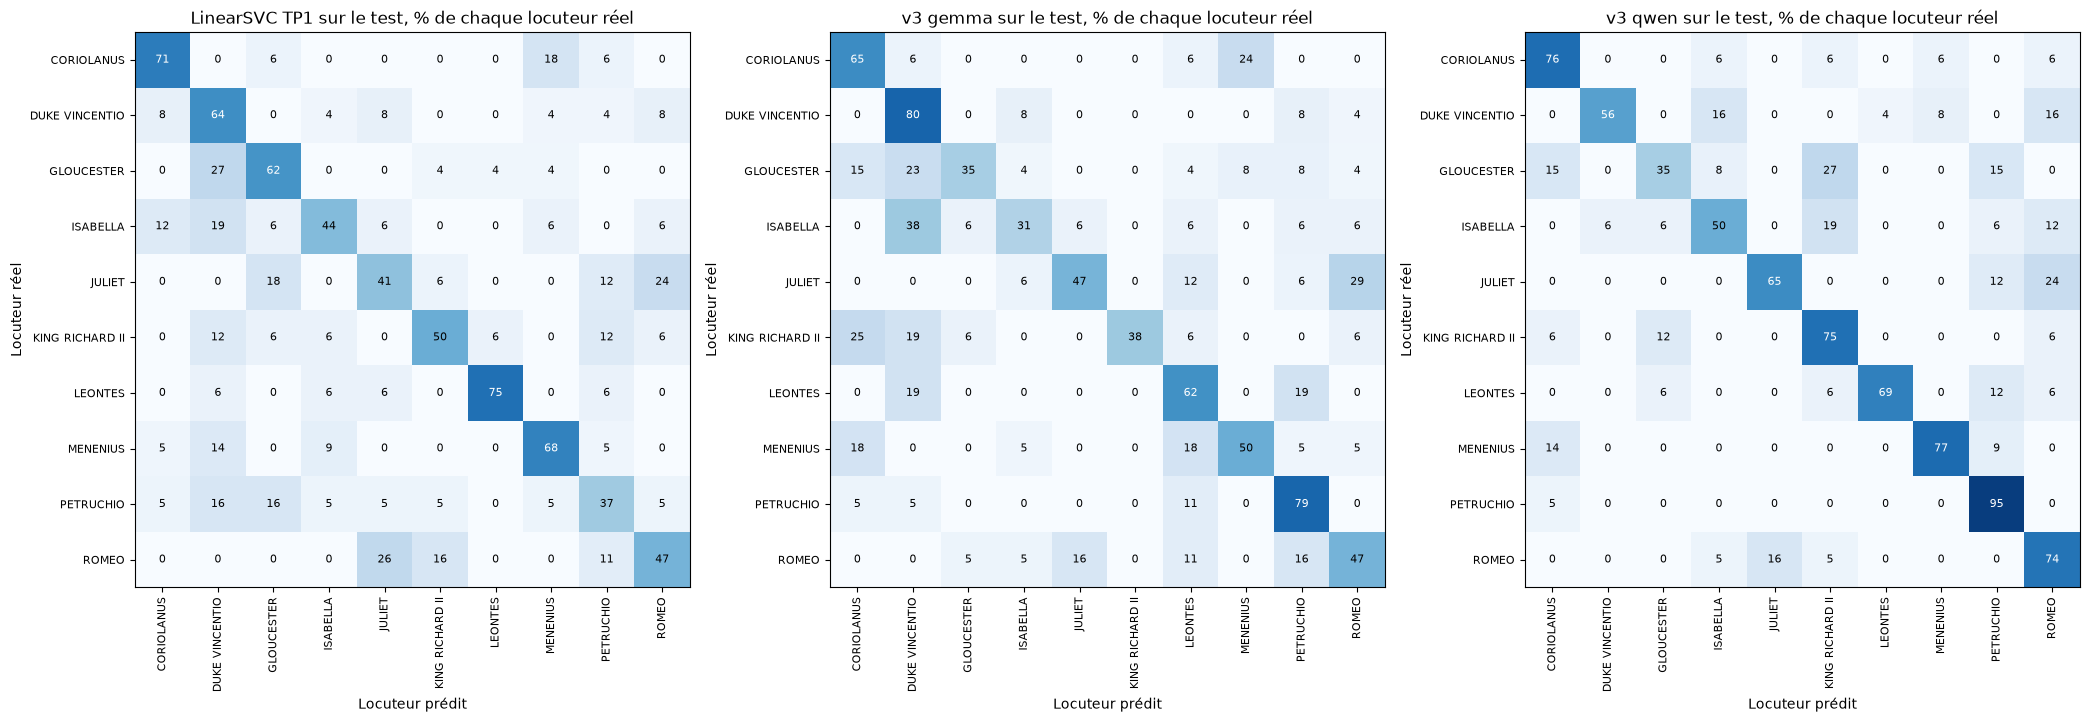

In [56]:
# Matrices de confusion du test pour LinearSVC et pour v3, en % de chaque locuteur réel.
matrices_test = {nom: matrice_confusion(nom, resultats_test, y_test) for nom in MEILLEURS}
fig, axes = plt.subplots(1, len(matrices_test), figsize=(21, 7))
for axe, (nom, matrice) in zip(axes, matrices_test.items()):
    tracer_matrice(axe, f'{nom} sur le test', matrice)
plt.tight_layout()
plt.show()

In [57]:
# Rappel moyen, trois plus fortes confusions et couples du TP1 sur le test.
decrire_confusions(matrices_test)

LinearSVC TP1 : rappel moyen 55.8 %
   plus fortes confusions
      GLOUCESTER → DUKE VINCENTIO : 26.9 % (7 sur 26)
      ROMEO → JULIET : 26.3 % (5 sur 19)
      JULIET → ROMEO : 23.5 % (4 sur 17)
   couples suivis depuis le TP1
      JULIET → ROMEO : 23.5 % (4 sur 17)
      ROMEO → JULIET : 26.3 % (5 sur 19)
      GLOUCESTER → DUKE VINCENTIO : 26.9 % (7 sur 26)
      DUKE VINCENTIO → GLOUCESTER : 0.0 % (0 sur 25)
v3 gemma : rappel moyen 53.4 %
   plus fortes confusions
      ISABELLA → DUKE VINCENTIO : 37.5 % (6 sur 16)
      JULIET → ROMEO : 29.4 % (5 sur 17)
      KING RICHARD II → CORIOLANUS : 25.0 % (4 sur 16)
   couples suivis depuis le TP1
      JULIET → ROMEO : 29.4 % (5 sur 17)
      ROMEO → JULIET : 15.8 % (3 sur 19)
      GLOUCESTER → DUKE VINCENTIO : 23.1 % (6 sur 26)
      DUKE VINCENTIO → GLOUCESTER : 0.0 % (0 sur 25)
v3 qwen : rappel moyen 67.1 %
   plus fortes confusions
      GLOUCESTER → KING RICHARD II : 26.9 % (7 sur 26)
      JULIET → ROMEO : 23.5 % (4 sur 17)
   

> *Mes observations :*
>
> Le rappel moyen vaut 55,8 % pour LinearSVC, 53,4 % pour Gemma et 67,1 % pour Qwen. La confusion GLOUCESTER vers DUKE VINCENTIO du TP1 revient chez LinearSVC (7 sur 26) et chez Gemma (6 sur 26), mais disparaît chez Qwen (0 sur 26). Qwen envoie en revanche 7 répliques de GLOUCESTER sur 26 vers KING RICHARD II, proche des 24,3 % des folds. JULIET vers ROMEO reste dans les trois modèles, avec 4 ou 5 répliques sur 17.
>
> *Ma conclusion :* mon hypothèse tient. Le test garde exactement l'ordre des folds, avec v3 sur Qwen en tête à 0,658, puis LinearSVC à 0,563. Cet écart de 0,095 reste pourtant à la limite du hasard, car les intervalles se recouvrent et McNemar donne 0,057. H1 tient encore, car v0 reste sous LinearSVC chez les deux modèles, de 0,026 chez Qwen. Le gain de v3 sur v0 se confirme sur des répliques jamais vues. Tous les scores montent sur le test, même ceux des LLM qui n'apprennent rien, donc ces 193 répliques sont plus faciles que le développement.

### 4.5 Mon journal d'expériences

Une ligne après chaque essai, et une hypothèse reste même si le résultat ne la confirme pas. Le registre affiché dans la section 3.4 fournit les chiffres.

| Expérience | Hypothèse | Changement | Observation chiffrée | Décision |
|---|---|---|---|---|
| 1. Déterminisme (section 2.4) | Deux appels identiques donnent le même texte | température 0 puis 0,7, seed 42, second appel hors cache | Sorties identiques pour les deux modèles, aux deux températures | Hypothèse confirmée. Seed 42 et température 0 gardées, le cache rejoue une mesure fidèle |
| 2. Cache de préfixe (section 2.4) | Le second appel d'un prompt à trente exemples évalue moins de tokens | même prompt envoyé deux fois, puis une autre réplique | Même prompt : environ 2,7 s puis quelques centièmes de seconde chez Gemma, 15,8 s puis 0,2 s chez Qwen. Autre réplique : environ 0,1 s chez Gemma, plus de 15 s chez Qwen | Hypothèse confirmée pour Gemma, réfutée pour Qwen dès que la réplique change |
| 3. Coût de bascule (section 2.5) | Alterner les modèles à chaque appel paierait un chargement par réplique | appels alternés contre appels groupés par modèle | Plusieurs secondes de chargement par bascule, contre moins de 0,2 s sans bascule | Hypothèse confirmée. Appels groupés par modèle avec `grouper_par_modele` |
| 4. Modèle de mise au point (section 2.5) | Le modèle le plus rapide peut mener les itérations sans changer les décisions | latence par appel des deux modèles | Latence directe 0,26 s contre 1,09 s, 769 appels en 3,4 min contre 14 min, et 3,6 min contre 88 min avec trente exemples | Gemma mène les itérations, Qwen vérifie les paliers retenus |
| 5. Mode de sortie (section 3.3) | H4, H8 | bloc `format`, v0 contre v1-texte, v1-json et v1-schema, sur les deux modèles | Conformité de 100 % partout. Gemma : v1-schema 0,269 contre 0,236 (gain net 3), v1-json +2, v1-texte −1. Qwen : v1-texte 0,469 contre 0,426 (gain net 3), JSON et schéma +2. JSON à 18 ou 19 tokens contre 5 chez Gemma | H4 confirmée. v1-schema retenue pour Gemma, v1-texte pour Qwen, au seuil de 3. H8 mesurée dans la section 3.5 |
| 6. v2 critères (section 3.4) | Des indices explicites corrigent les erreurs à nom cité | bloc `criteres` | F1 0,306 contre 0,269, 3 corrigées, 1 cassée, gain net 2 | Sous le seuil, v1-schema gardée |
| 7. v3 contexte des pièces (section 3.4) | H2 | bloc `contexte` | Gemma situe 3 pièces sur 10, Qwen 9. F1 0,453 contre 0,269, gain net 7, dont 5 sur les 17 répliques à nom cité et 2 sur les 33 autres | H2 confirmée sur les 50, v3 retenue pour Gemma |
| 8. v4 un exemple par classe (section 3.4) | H3 | bloc `exemples`, dix exemples | F1 0,222, gain net −8, prompt de 1 139,5 tokens en médiane | H3 réfutée, v3 gardée |
| 9. v5 trois exemples par classe (section 3.4) | H3, H5 | bloc `exemples`, trente exemples | F1 0,352, gain net −3, prompt de 2 822,5 tokens, latence de 0,63 s | H3 réfutée, v3 gardée |
| 10. v6 exemples difficiles (section 3.4) | Les cas que LinearSVC rate guident mieux | choix des exemples | 366 répliques difficiles sur 719. F1 0,350, gain net −3 face à v3 et 0 face à v5 | Hypothèse réfutée, v3 gardée |
| 11. Transfert du prompt (section 3.4) | H7 | mêmes versions rejouées sur le modèle de comparaison | v3 sur Qwen : F1 0,488 contre 0,461, gain net 0 | H7 soutenue, même signe du F1, gain nul |
| 12. v7 raisonnement (section 3.5) | H8 | direct, raisonnement demandé, réflexion native | Gemma : 0,337 et 0,348 contre 0,453, gain net −5, 687 tokens générés contre 19. Qwen : 0,505 avec le raisonnement demandé (gain net 0), 0,534 avec la réflexion native mais 22 sorties tronquées sur 50 à 6 144 tokens et 59,7 s par réplique. Gain net sans nom cité de −1 à −4 | H8 tient pour le déclencheur, réfutée pour l'effet. v3 gardée, folds en direct |
| 13. Versions retenues sur les cinq folds (section 3.6) | H1, H6, H7, gain de v3 plus faible hors des 50 | v0 et v3 sur les 769 répliques, deux modèles | v0 : Gemma 0,271, Qwen 0,479, contre 0,482 pour LinearSVC. v3 : Gemma 0,472, Qwen 0,584, et Qwen bat LinearSVC dans les cinq folds. Gain de v3 sur les 719 : 0,202 chez Gemma et 0,108 chez Qwen, contre 0,217 et 0,062 sur les 50 | H1 tient, de justesse pour Qwen. H6 et H7 confirmées. Rétrécissement faible pour Gemma, réfuté pour Qwen. v3 gardée pour les deux modèles |
| 14. Test final (section 4.4) | H1, H5, H6, H7, même ordre que les folds | v3 figée pour les deux modèles, v0 en témoin, LinearSVC réajusté sur les 769 | LinearSVC 0,563, v3 sur Qwen 0,658 (intervalle de 0,585 à 0,715), v3 sur Gemma 0,527, v0 sur Qwen 0,537, v0 sur Gemma 0,314. Face à LinearSVC, Qwen a seul raison sur 49 répliques contre 31, p-value de 0,057 | Même ordre que les folds, avance de Qwen à la limite du hasard. H1 tient, gain de v3 confirmé |

### 4.6 Ce que je peux conclure

Je réponds à cinq questions. Que sait déjà le modèle de ces dix personnages, et que lui apportent le contexte et les exemples ? Quelle brique répond le mieux au problème, LinearSVC, un LLM ou les deux, scores, coût et latence compris ? Quel modèle pour quel budget, et le grand modèle justifie-t-il sa latence ? Quelles hypothèses, de H1 à H8, mes expériences soutiennent-elles ? Qu'est-ce qui reste incertain sur la conformité des sorties, le choix des exemples et la généralisation ?

Je commence par une synthèse de toutes les briques, F1 des folds et du test face à la latence par réplique.

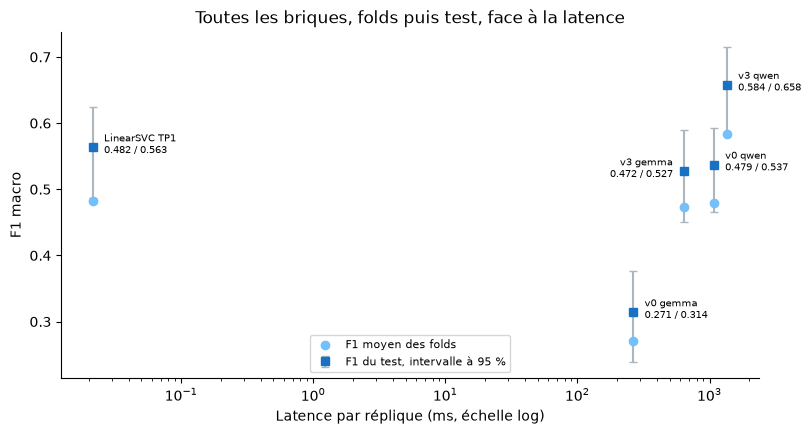

In [58]:
# Synthèse : F1 des folds et du test face à la latence par réplique, intervalle du test en barre.
SYNTHESE = ['LinearSVC TP1'] + COUPLES
latences = couts.loc[SYNTHESE, 'Latence par réplique (ms)']
test = bilan_test.loc[SYNTHESE]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(latences, test['F1 folds'], color='#74c0fc', zorder=3, label='F1 moyen des folds')
barres = [test['F1 test'] - test['Intervalle bas'], test['Intervalle haut'] - test['F1 test']]
ax.errorbar(latences, test['F1 test'], yerr=barres, fmt='s', color='#1971c2', ecolor='#adb5bd',
            capsize=3, label='F1 du test, intervalle à 95 %')
for nom in SYNTHESE:
    gauche = nom == 'v3 gemma'  # Étiquette à gauche, sinon elle recouvre celle de v0 qwen
    ax.annotate(f'{nom}\n{test.loc[nom, "F1 folds"]:.3f} / {test.loc[nom, "F1 test"]:.3f}',
                (latences[nom], test.loc[nom, 'F1 test']), textcoords='offset points',
                xytext=(-8, -4) if gauche else (8, -4), ha='right' if gauche else 'left',
                fontsize=7)
ax.set_xscale('log')
ax.set(xlabel='Latence par réplique (ms, échelle log)', ylabel='F1 macro',
       title='Toutes les briques, folds puis test, face à la latence')
ax.legend(fontsize=8, loc='lower center')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

> *Mes observations :*
>
> Chaque brique monte du F1 des folds au F1 du test, sans changer d'ordre. v3 sur Qwen reste la seule au-dessus de LinearSVC, mais l'intervalle de son test recouvre en partie celui de LinearSVC. Le prix de ce gain est une latence plusieurs dizaines de milliers de fois plus forte.

**Connaissance préalable, contexte et exemples.** Sans contexte, Gemma reste à 0,271 sur les folds et Qwen à 0,479, à égalité avec LinearSVC. Qwen situe 9 pièces sur 10 et Gemma 3, ce qui explique une grande part de cet écart (section 3.4). Le contexte des pièces apporte 0,202 de F1 à Gemma et 0,108 à Qwen hors des 50 répliques, et ce gain se confirme sur le test. Les exemples ont fait baisser Gemma sur les 50 répliques, de 0,222 à 0,352 contre 0,453 pour v3, donc je n'en ai retenu aucun.

**La meilleure brique.** v3 sur Qwen donne le meilleur F1, 0,584 sur les folds et 0,658 sur le test, et bat LinearSVC sur neuf locuteurs sur dix. Son avance sur le test reste à la limite du hasard, avec une p-value de 0,057, pour une latence plusieurs dizaines de milliers de fois plus forte. Les deux briques se trompent sur des répliques différentes, donc l'hybride à 50 % garde le F1 de Qwen avec moitié moins d'appels (section 4.3). Pour un usage réel, je choisirais cet hybride, après l'avoir testé sur un découpage neuf.

**Quel modèle pour quel budget.** Avec un budget de latence serré, LinearSVC reste le bon choix. Ni v3 sur Gemma ni v0 sur Qwen ne le dépassent, sur les folds comme sur le test. Le grand modèle justifie sa latence, car Qwen dépasse Gemma de 0,112 sur les folds et de 0,131 sur le test, pour 2,1 fois sa latence. Gemma n'a d'intérêt que dans l'hybride, où il dépasse LinearSVC de 0,048 avec deux fois moins de latence que seul.

**Ce qui reste incertain.** La conformité atteint 100 % avec v3, mais v0 répondait parfois par un personnage d'une autre pièce. La réflexion de Qwen se coupait aussi sur 22 répliques sur 50. Les exemples n'ont été essayés que sur Gemma et sur 50 répliques, donc un gain avec Qwen ou avec des exemples mieux choisis reste possible. Mes décisions sur 50 répliques étaient bruitées, car le gain de v3 chez Qwen valait 2 répliques nettes sur les 50 et 71 sur les 719. Enfin, le test a déjà servi au TP1, il est plus facile que le développement, et ses intervalles sont larges d'environ 0,13.

Mes hypothèses, avec leur verdict et la preuve qui le porte :

| Hypothèse | Verdict | Preuve |
|---|---|---|
| H1, connaissance préalable | Tient de justesse, réfutée sur les 50 pour Qwen | v0 sous LinearSVC sur les folds (0,271 et 0,479 contre 0,482) et sur le test (0,314 et 0,537 contre 0,563), sections 3.1, 3.6 et 4.4 |
| H2, contexte | Tient | v3 gagne 5 répliques nettes sur les 17 à nom cité de Gemma (section 3.4), et Qwen 17,1 pour 100 avec un nom contre 5,7 sans (section 4.2) |
| H3, exemples | Réfutée | v4, v5 et v6 perdent de 3 à 8 répliques nettes face à v3 sur les 50 (section 3.4) |
| H4, format | Tient | conformité de 100 % dans les trois modes, écarts de F1 au seuil ou dessous (section 3.3) |
| H5, coût | Tient pour la latence, sa règle ne justifie que v3 sur Qwen | latence plus de mille fois plus forte, gain de 0,102 au-dessus de l'écart-type des folds (section 4.3) |
| H6, grand modèle | Tient | Qwen dépasse Gemma de 0,208 avec v0 et de 0,112 avec v3, pour 4,1 et 2,1 fois sa latence (sections 3.6 et 4.3) |
| H7, transfert du prompt | Tient | gain de v3 de 0,202 chez Gemma et de 0,108 chez Qwen hors des 50 (section 3.6) |
| H8, raisonnement | Tient pour le déclencheur, réfutée pour l'effet | gains nets de −5 chez Gemma et de 0 et −3 chez Qwen, sans gain sur les répliques sans nom (section 3.5) |
| Gain de v3 plus faible hors des 50 | Faible pour Gemma, réfutée pour Qwen | de 20 à 18,2 répliques nettes pour 100 chez Gemma, de 4 à 9,9 chez Qwen (section 3.6) |
| Erreurs des LLM plus souvent dans la pièce | Réfutée | 18,6 % et 22,0 % pour v3 contre 20,2 % pour LinearSVC (section 4.2) |

> *Ma conclusion :* un LLM local sans exemple reconnaît un locuteur de Shakespeare surtout par ce qu'il sait déjà des pièces. Le contexte des pièces apporte le gain principal, et le grand modèle en profite le mieux, avec 0,658 sur le test contre 0,563 pour LinearSVC. Ce gain se concentre sur les répliques qui citent un nom, et il coûte plusieurs dizaines de milliers de fois la latence de LinearSVC. Les exemples et le raisonnement n'ont rien apporté sur ce problème. Le choix le plus solide reste donc un pipeline hybride, où LinearSVC répond seul aux cas sûrs et le LLM aux autres.

### Pour aller plus loin

Chaque piste part d'un résultat de ce TP.

- Tester l'hybride à 50 % sur un découpage neuf, car sa part a été choisie sur les 769 répliques (section 4.3).
- Distinguer Richard, duc de Gloucester, de KING RICHARD II dans le bloc contexte, car Qwen envoie environ un quart des répliques de GLOUCESTER vers ce roi (sections 4.2 et 4.4).
- Décider sur plus de 50 répliques, ou avec un test apparié, car mon seuil de 3 répliques a écarté un gain de 71 répliques nettes chez Qwen (section 3.6).
- Choisir les exemples par similarité avec la réplique, car des exemples tirés au hasard ont fait baisser Gemma (section 3.4).
- Relever la borne de la réflexion de Qwen, car 22 de ses 28 réponses terminées étaient justes (section 3.5).
- Lire les log-probabilités du premier token comme confiance du LLM, pour router les cas incertains comme avec la marge de LinearSVC.
- Ajuster finement un des deux modèles sur les 769 répliques, si le prompt plafonne.